# Connect Forest Management Model with Forest Carbon Budget Model

In [15]:
import numpy as np
import math
import matplotlib.pyplot as plt
import pandas as pd
import ipywidgets as widgets
from IPython.display import display
import ws3.forest
import time
import gurobipy as grb
import pickle
import libcbm
import os
from util_opt import compile_events, cbm_report, compile_scenario_maxstock, plot_scenario_maxstock, run_cbm_emissionstock, run_scenario, plugin_c_curves, plugin_c_curves_both, cbm_report_both, compare_ws3_cbm, compare_ws3_cbm_both, track_system_stock, track_system_emission, compile_scenario_minemission, plot_scenario_minemission, kpi_age, kpi_species, cmp_c_ss, cmp_c_se, results_scenarios, bootstrap_ogi, compare_kpi_age

In [16]:
base_year = 2020
horizon = 10
period_length = 10
max_age = 1000
n_steps = 100
tvy_name = 'totvol'
max_harvest = 1.0

In [17]:
# Define scenario options based on case study
scenario_options = {
    'redchris': ['no_cons','evenflow_cons',  'bau_redchrs', 'redchrs_AAC_90%', 'redchrs_AAC_80%', 'redchrs_AAC_70%', 'redchrs_AAC_60%', 'redchrs_AAC_50%', 'redchrs_AAC_40%', 'redchrs_AAC_30%', 'redchrs_AAC_20%', 'redchrs_AAC_10%' ],
    'goldenbear': ['no_cons', 'evenflow_cons', 'bau_gldbr', 'gldbr_AAC_90%', 'gldbr_AAC_80%', 'gldbr_AAC_70%', 'gldbr_AAC_60%', 'gldbr_AAC_50%', 'gldbr_AAC_40%', 'gldbr_AAC_30%', 'gldbr_AAC_20%', 'gldbr_AAC_10%'],
    'equitysilver': [ 'no_cons','evenflow_cons', 'bau_eqtslvr', 'eqtslvr_AAC_90%', 'eqtslvr_AAC_80%', 'eqtslvr_AAC_70%', 'eqtslvr_AAC_60%', 'eqtslvr_AAC_50%', 'eqtslvr_AAC_40%', 'eqtslvr_AAC_30%', 'eqtslvr_AAC_20%', 'eqtslvr_AAC_10%'],
    'test': ['no_cons', 'evenflow_cons', 'bau_redchrs']
}

# Function to handle case study selection and update scenario dropdown
def select_case_study(case_study):
    print(f"Selected case study: {case_study}")
    # Update the scenario dropdown based on the selected case study
    scenario_dropdown.options = scenario_options.get(case_study, [])
    scenario_dropdown.value = scenario_options[case_study][0]  # Set a default value

# Case study dropdown
case_study_dropdown = widgets.Dropdown(
    options=['redchris', 'goldenbear', 'equitysilver', 'test'],
    value='goldenbear',
    description='Case Study:'
)
case_study_dropdown.observe(lambda change: select_case_study(change['new']), names='value')
display(case_study_dropdown)

# Function to handle scenario selection
def select_scenario(scenario_name):
    print(f"Selected scenario: {scenario_name}")

# Scenario dropdown
scenario_dropdown = widgets.Dropdown(
    options=scenario_options['redchris'],  # Set initial options based on default case study
    value=scenario_options['redchris'][1],  # Set initial value
    description='Scenario:'
)
scenario_dropdown.observe(lambda change: select_scenario(change['new']), names='value')
display(scenario_dropdown)

# Function to handle objective functon
def select_obj(obj_mode):
    print(f"Selected objective: {obj_mode}")
obj_dropdown = widgets.Dropdown(
    options=['max_hv', 'min_ha', 'max_st', 'min_em'],
    value='max_st',
    description='Objective:'
)
display(obj_dropdown)
obj_dropdown.observe(lambda change: select_obj(change['new']), names='value')

Dropdown(description='Case Study:', index=1, options=('redchris', 'goldenbear', 'equitysilver', 'test'), value…

Dropdown(description='Scenario:', index=1, options=('no_cons', 'evenflow_cons', 'bau_redchrs', 'redchrs_AAC_90…

Dropdown(description='Objective:', index=2, options=('max_hv', 'min_ha', 'max_st', 'min_em'), value='max_st')

In [18]:
# Initialize main widget components 
hwp_pool_effect = widgets.FloatSlider(min=0, max=1, step=1, description='HWP_effect', value=1, layout=widgets.Layout(margin='10px 0'))
release_immediately = widgets.FloatSlider(min=0, max=1, step=1, description='Release immediately', value=1, layout=widgets.Layout(margin='10px 0'))
displacement_effect = widgets.FloatSlider(min=0, max=1, step=1, description='Displacement', value=1, layout=widgets.Layout(margin='10px 0'))
clt_percentage = widgets.FloatSlider(min=0, max=1, step=0.1, description='CLT_percent:', value=0.5, layout=widgets.Layout(margin='10px 0'))
credibility = widgets.FloatSlider(min=0, max=1, step=0.1, description='Credibility:', value=1, layout=widgets.Layout(margin='10px 0'))
# max_harvest = widgets.FloatSlider(min=0, max=1, step=0.05, description='Max_harvest:', value=1.0, layout=widgets.Layout(margin='10px 0'))
budget_input = widgets.FloatText(value=10000000, description='Budget:', layout=widgets.Layout(margin='10px 0'))

release_immediately.layout.display = 'none' if hwp_pool_effect.value != 0 else 'block'
displacement_effect.layout.display = 'block' if hwp_pool_effect.value != 0 else 'none'
clt_percentage.layout.display = 'block' if hwp_pool_effect.value != 0 and displacement_effect.value != 0 else 'none'
credibility.layout.display = 'block' if hwp_pool_effect.value != 0 and displacement_effect.value != 0 else 'none'

container = widgets.VBox([
    hwp_pool_effect, release_immediately, displacement_effect, clt_percentage, credibility, budget_input  
    # ,max_harvest
])

display(container)

def update_widgets(change):
    hwp_pool_effect_value = hwp_pool_effect.value
    displacement_effect_value = displacement_effect.value

    release_immediately.layout.display = 'block' if hwp_pool_effect_value == 0 else 'none'
    displacement_effect.layout.display = 'block' if hwp_pool_effect_value != 0 else 'none'

    clt_percentage.layout.display = 'block' if hwp_pool_effect_value != 0 and displacement_effect_value != 0 else 'none'
    credibility.layout.display = 'block' if hwp_pool_effect_value != 0 and displacement_effect_value != 0 else 'none'

hwp_pool_effect.observe(update_widgets, names='value')
displacement_effect.observe(update_widgets, names='value')

In [19]:
#Start Calculating the Running Time
Start = time.time()

In [20]:
case_study = case_study_dropdown.value
scenario_name = scenario_dropdown.value
obj_mode = obj_dropdown.value
hwp_pool_effect_value = hwp_pool_effect.value
release_immediately_value = release_immediately.value if hwp_pool_effect_value == 0 else 0
displacement_effect = displacement_effect.value if hwp_pool_effect_value != 0 else 0
clt_percentage = clt_percentage.value if displacement_effect != 0 else 0
credibility = credibility.value if displacement_effect != 0 else 0
# max_harvest = max_harvest.value
budget_input = budget_input.value

In [21]:
# Define case study mappings and retrieve model details based on case study
case_study_options = {
    'redchris': {
        'model_name': 'redchris',
        'model_path': './data/woodstock_model_files_redchris'
    },
    'goldenbear': {
        'model_name': 'goldenbear',
        'model_path': './data/woodstock_model_files_goldenbear'
    },
    'equitysilver': {
        'model_name': 'equitysilver',
        'model_path': './data/woodstock_model_files_equitysilver'
    },
    'test': {
        'model_name': 'redchris',
        'model_path': './data/woodstock_model_files_redchris_test'
    }
}

model_info = case_study_options.get(case_study)

if model_info:
    model_name = model_info['model_name']
    model_path = model_info['model_path']
else:
    print('The case study name is not valid')


In [22]:
# Create and Run `ForestModel` instance
fm = ws3.forest.ForestModel(model_name=model_name,
                            model_path=model_path,
                            base_year=base_year,
                            horizon=horizon,
                            period_length=period_length,
                            max_age=max_age)
fm.import_landscape_section()
fm.import_areas_section()
fm.import_yields_section()
fm.import_actions_section()
fm.import_transitions_section()
fm.initialize_areas()
fm.add_null_action()
fm.reset_actions()
fm.grow()

In [23]:
# Flag 'harvest' as a harvesting action in the ws3 model
harvest_acode='harvest'
fm.actions[harvest_acode].is_harvest = True

In [24]:
# Read curves
file_directory = "./inputs/curves"
file_names = [f"{case_study}_c_curves_p.pkl", f"{case_study}_c_curves_f.pkl"]
loaded_data = {}

for filename in file_names:
    file_path = os.path.join(file_directory, filename)
    with open(file_path, 'rb') as file:
        loaded_data[filename] = pickle.load(file)
    print(f"Loaded data from {file_path}")

c_curves_p = loaded_data.get(f"{case_study}_c_curves_p.pkl")
c_curves_f = loaded_data.get(f"{case_study}_c_curves_f.pkl")

Loaded data from ./inputs/curves/goldenbear_c_curves_p.pkl
Loaded data from ./inputs/curves/goldenbear_c_curves_f.pkl


In [25]:
# Plug carbon and old groth yield curves into forest model
plugin_c_curves_both(fm, c_curves_p, c_curves_f)
bootstrap_ogi(fm)

Running for goldenbear_max_st_no_cons...
running no_cons scenario
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 3905 rows, 36130 columns and 36130 nonzeros
Model fingerprint: 0xb0ae7bf3
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [2e+02, 1e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+00]
Presolve removed 3905 rows and 36130 columns
Presolve time: 0.03s
Presolve: All rows and columns removed
Iteration    Objective       Primal Inf.    Dual Inf.      Time
       0    3.0270251e+08   0.000000e+00   0.000000e+00      0s

Solved in 0 iterations and 0.03 seconds (0.01 work units)
Optimal objective  3.027025112e+08


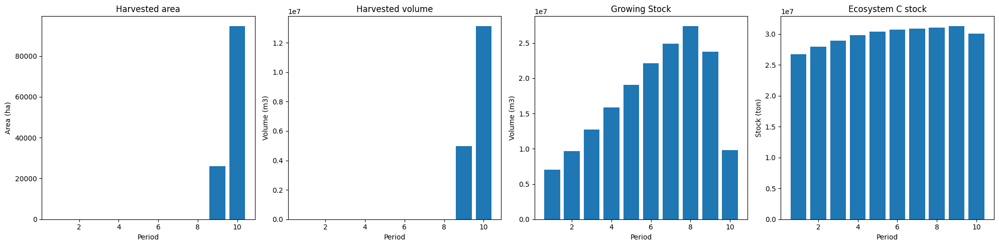

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_no_cons_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  19176
The economic indicator (the provincial government revenues) is:  653970
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


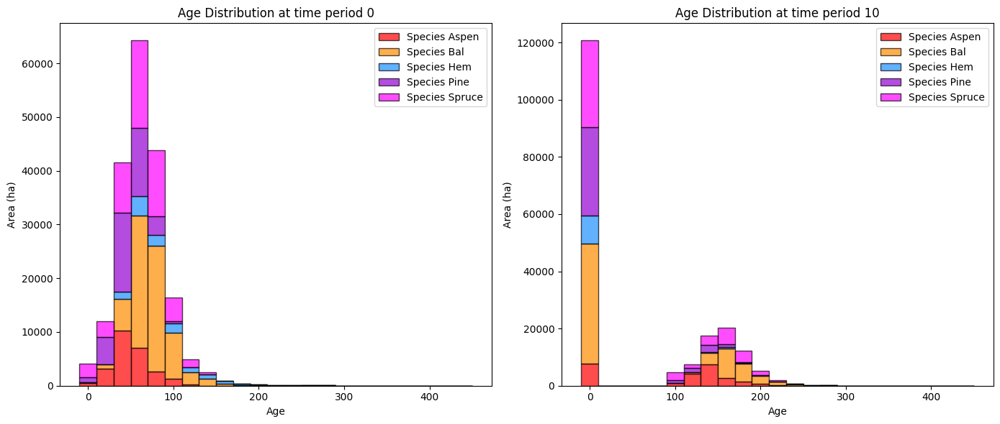

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_no_cons_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                 0           10   Difference
Spruce    2.708533  3485.893305  3483.184771
Bal     278.565372  7368.335601  7089.770229
Aspen   273.490478  9252.111513  8978.621035
Pine      0.000000  1097.627363  1097.627363
Hem     419.699331   705.040396   285.341065

Overall diversity has **increased** by 20934.54 hectares from time period 0 to time period 10.


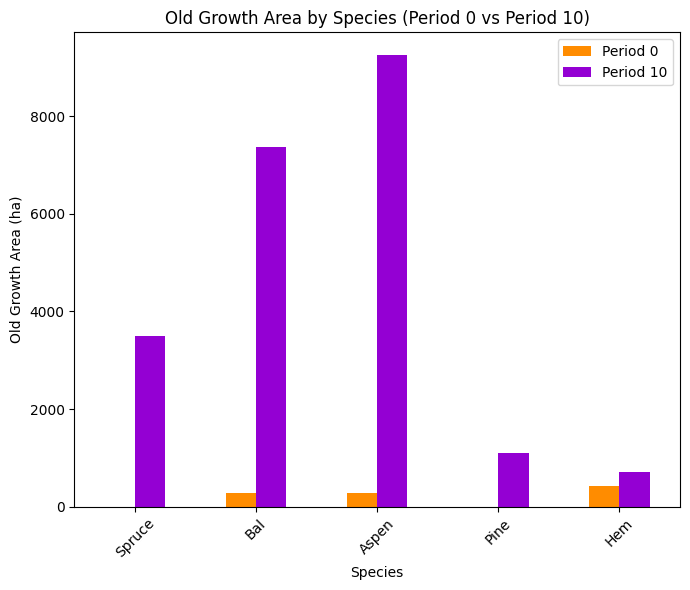

Clustered column plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_no_cons_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.9455
Shannon Evenness Index for time period 10: 0.8672

Diversity has **decreased** by 7.83% from time 0 to time 10.


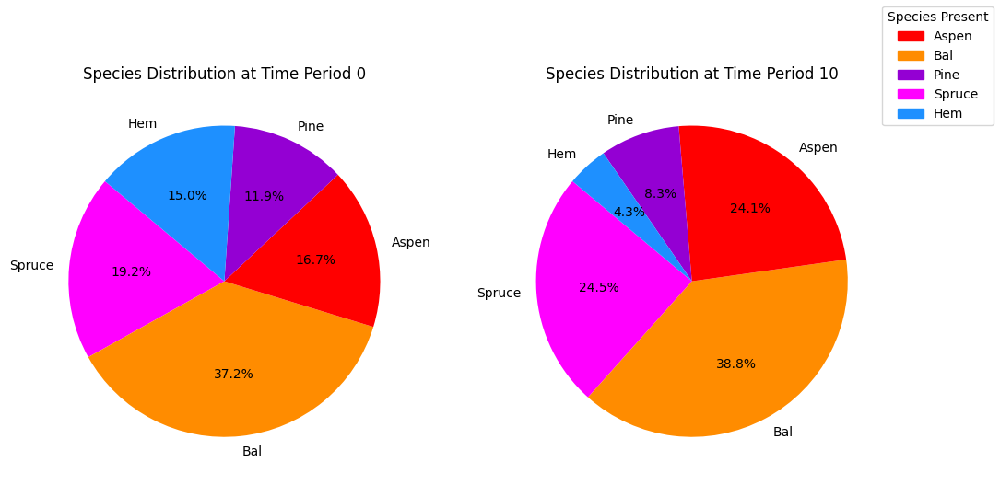

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_no_cons_species_pie.pdf
running business as usual scenario for the Golden Bear mine site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 3949 rows, 36130 columns and 470612 nonzeros
Model fingerprint: 0x7ea88e1f
Coefficient statistics:
  Matrix range     [1e-02, 1e+05]
  Objective range  [2e+02, 1e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 4e+07]
Presolve removed 2037 rows and 2031 columns
Presolve time: 0.13s
Presolved: 1912 rows, 34099 columns, 421112 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Ordering time: 0.00s

Barrier statistics:
 AA' NZ     : 6.876e+04
 Factor NZ  : 9.245e+04 (roughly 15 MB of memory)
 Factor Ops

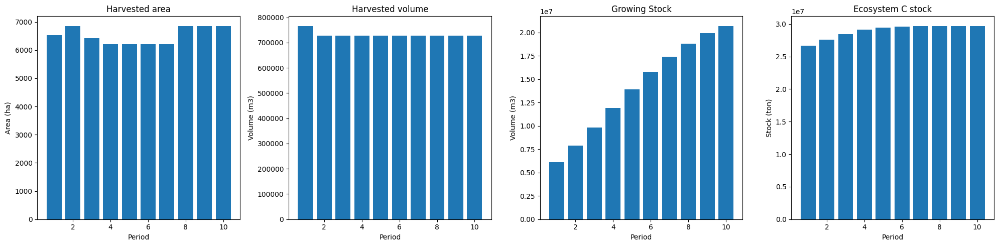

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  7734
The economic indicator (the provincial government revenues) is:  263762
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


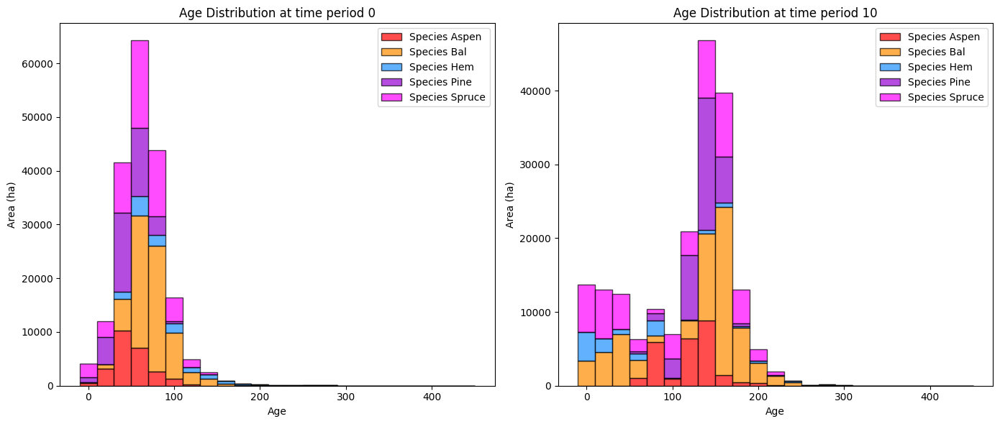

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                 0           10   Difference
Spruce    2.708533  4193.083821  4190.375287
Bal     278.565372  9045.947970  8767.382599
Aspen   273.490478  7151.110261  6877.619783
Pine      0.000000  6650.455938  6650.455938
Hem     419.699331   710.903413   291.204082

Overall diversity has **increased** by 26777.04 hectares from time period 0 to time period 10.


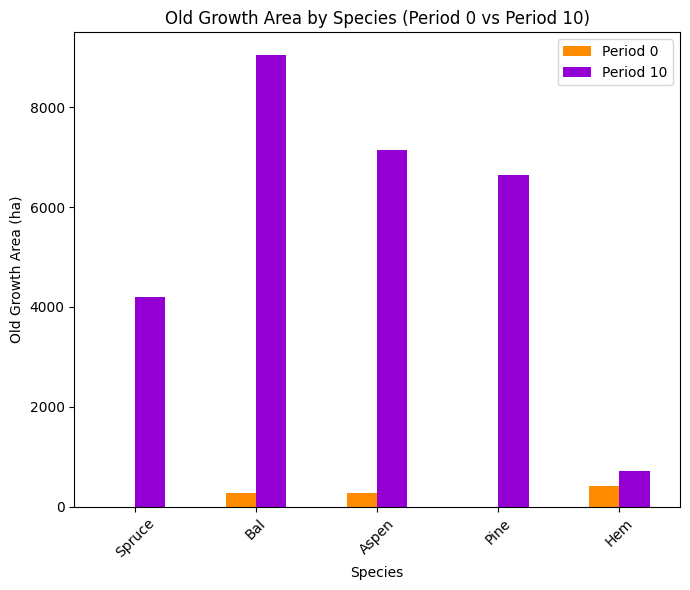

Clustered column plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.9455
Shannon Evenness Index for time period 10: 0.8856

Diversity has **decreased** by 5.99% from time 0 to time 10.


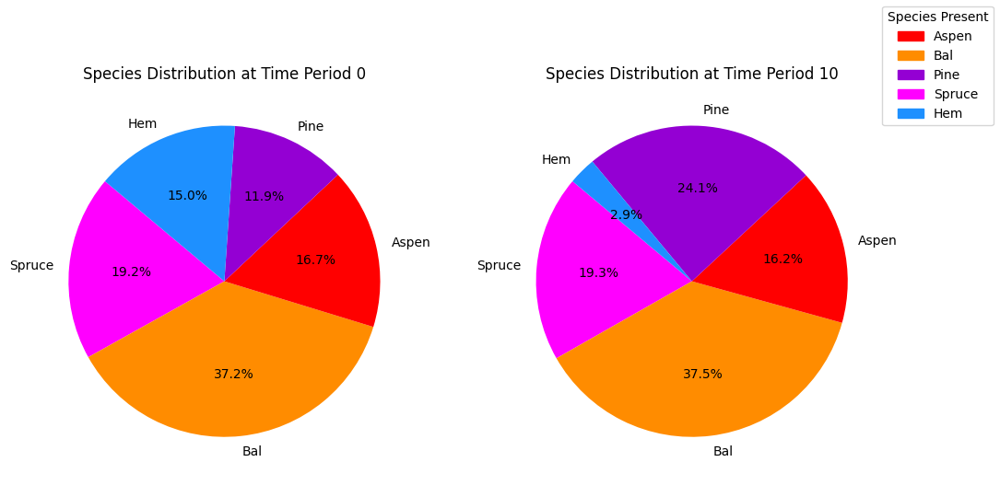

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_species_pie.pdf


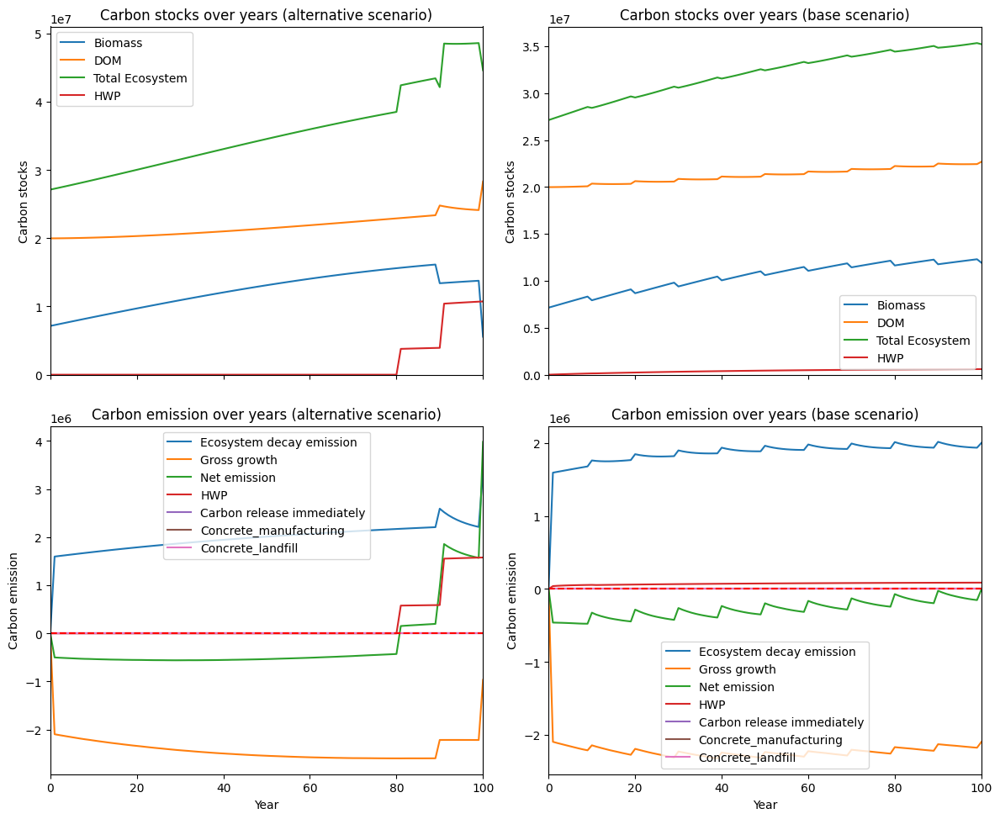

---------------------------------------------------------------------------------------
Net emission difference -3032702.434750341
Net emission base scenario -12873402.697854219
Net emission alternative scenario -9840700.263103876
dollar_per_ton is:  3.297389115863991
Comparison of Old Growth Areas (Alternative - Base)
          0           10   Difference
Spruce  0.0  -707.190516  -707.190516
Bal     0.0 -1677.612370 -1677.612370
Aspen   0.0  2101.001252  2101.001252
Pine    0.0 -5552.828574 -5552.828574
Hem     0.0    -5.863017    -5.863017

Overall, the old growth area has **decreased** by -5842.49 hectares in the alternative scenario compared to the base scenario.


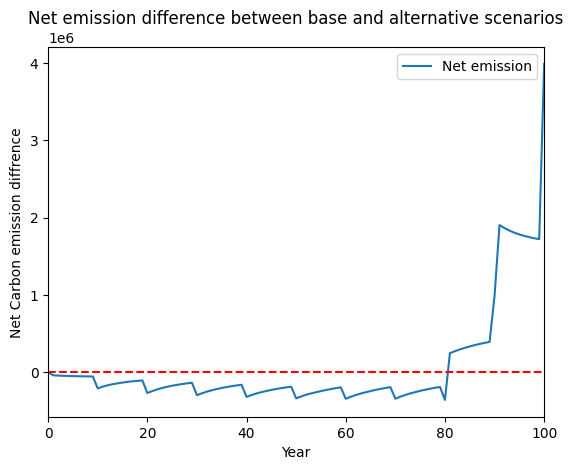

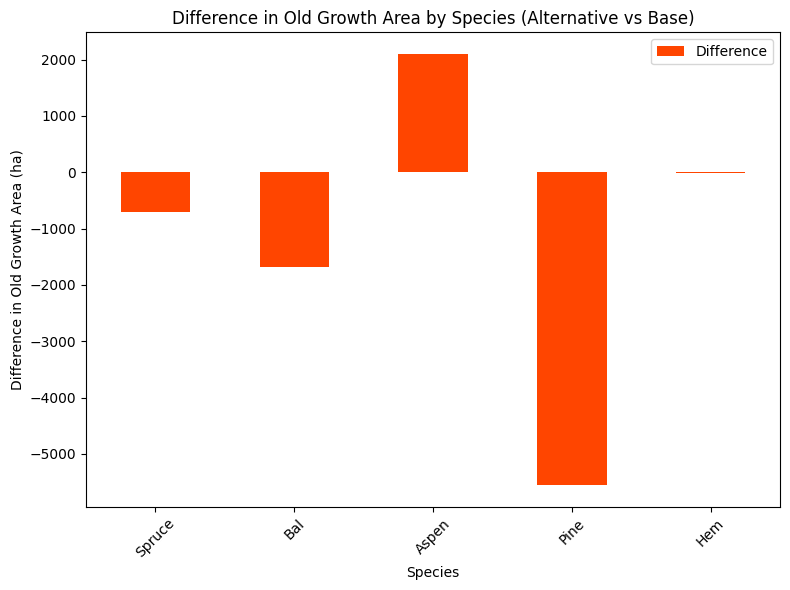

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_kpi_age_difference.pdf


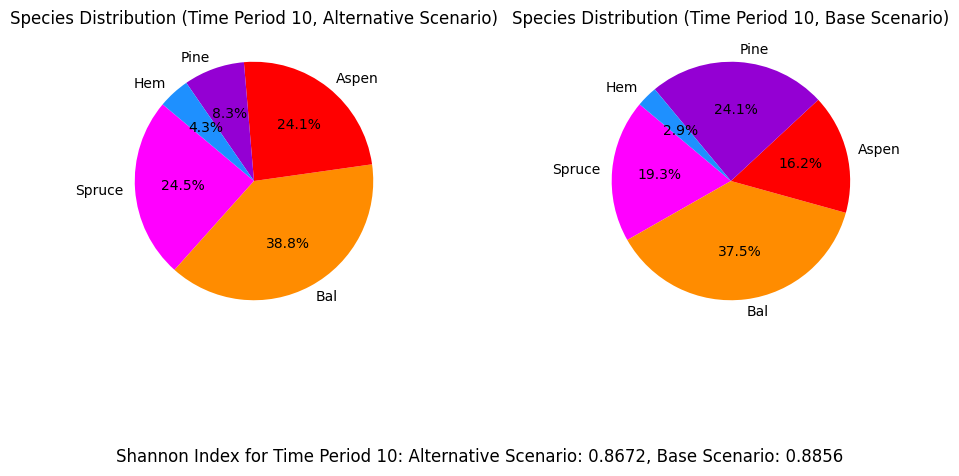

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
Running for goldenbear_max_st_evenflow_cons...
running even flow constraints scenario
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 3945 rows, 36130 columns and 430076 nonzeros
Model fingerprint: 0xff5fc6a0
Coefficient statistics:
  Matrix range     [1e-02, 9e+04]
  Objective range  [2e+02, 1e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 1e+00]
Presolve removed 2035 rows and 2031 columns
Presolve time: 0.10s
Presolved: 1910 rows, 34099 columns, 402875 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Ordering ti

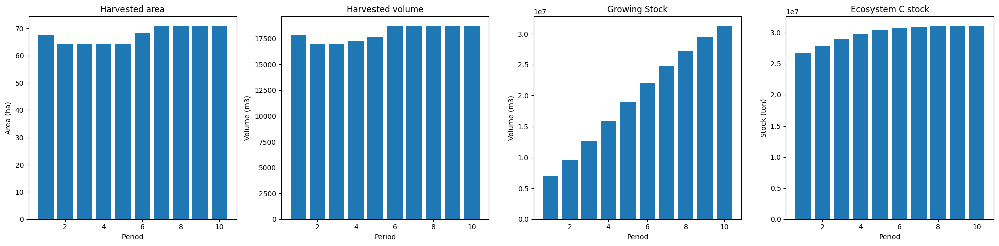

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_evenflow_cons_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  190
The economic indicator (the provincial government revenues) is:  6499
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


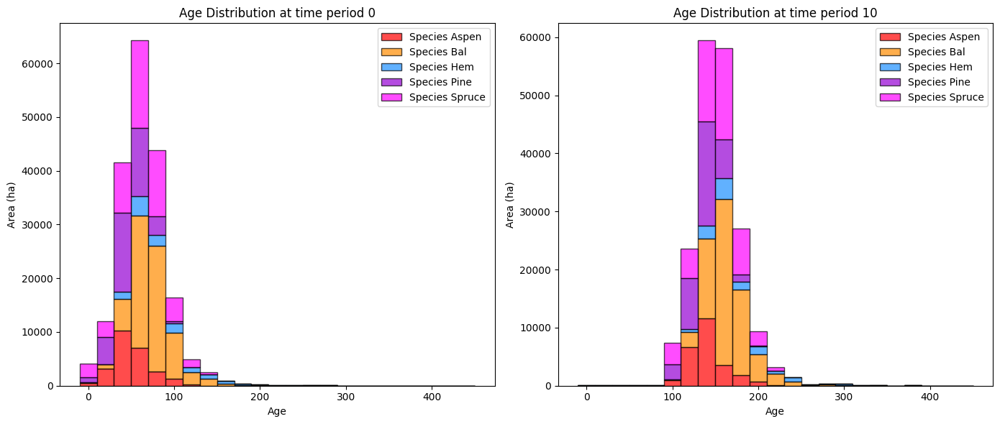

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_evenflow_cons_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                 0            10    Difference
Spruce    2.708533   7973.657683   7970.949150
Bal     278.565372  15930.145805  15651.580433
Aspen   273.490478  13191.618272  12918.127794
Pine      0.000000   7631.887200   7631.887200
Hem     419.699331   3412.039931   2992.340600

Overall diversity has **increased** by 47164.89 hectares from time period 0 to time period 10.


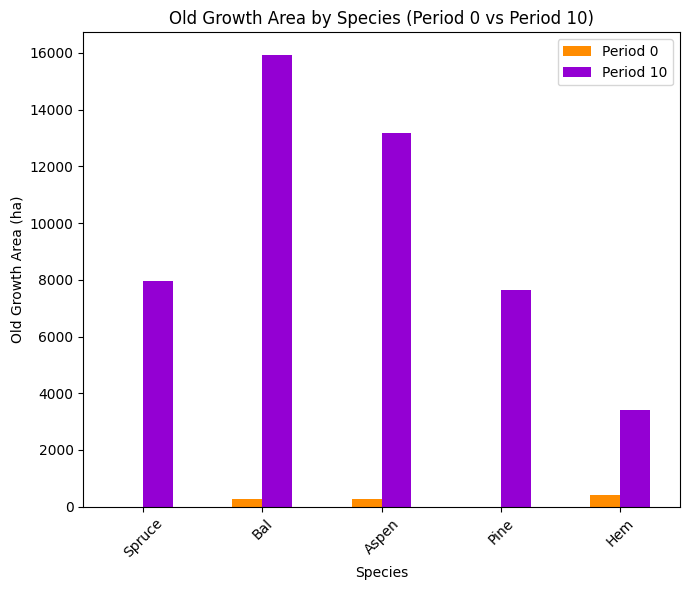

Clustered column plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_evenflow_cons_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.9455
Shannon Evenness Index for time period 10: 0.9256

Diversity has **decreased** by 1.99% from time 0 to time 10.


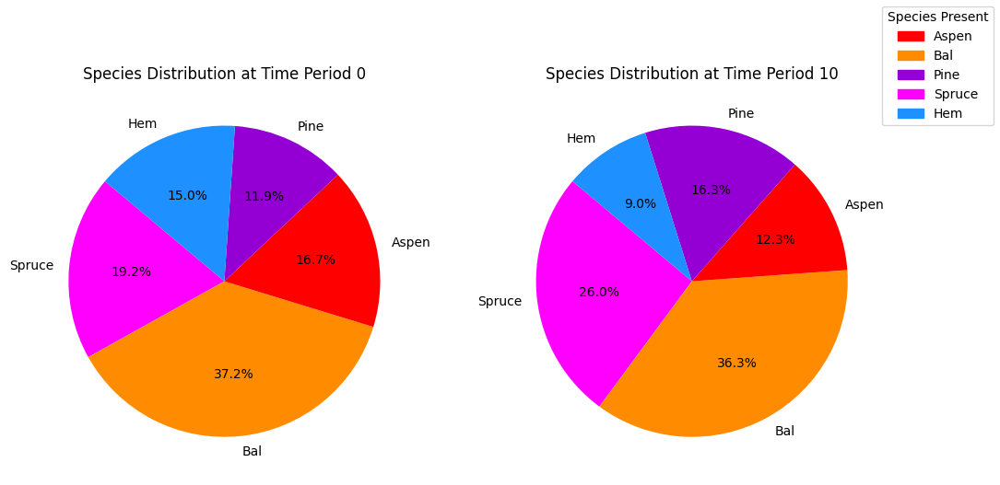

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_evenflow_cons_species_pie.pdf
running business as usual scenario for the Golden Bear mine site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 3949 rows, 36130 columns and 470612 nonzeros
Model fingerprint: 0x7ea88e1f
Coefficient statistics:
  Matrix range     [1e-02, 1e+05]
  Objective range  [2e+02, 1e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 4e+07]
Presolve removed 2037 rows and 2031 columns
Presolve time: 0.13s
Presolved: 1912 rows, 34099 columns, 421112 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Ordering time: 0.00s

Barrier statistics:
 AA' NZ     : 6.876e+04
 Factor NZ  : 9.245e+04 (roughly 15 MB of memory)
 Fact

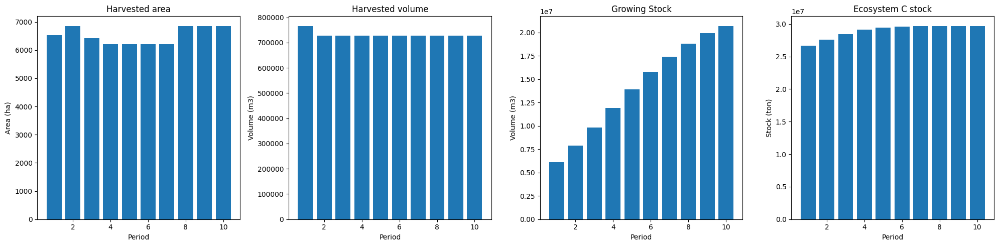

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  7734
The economic indicator (the provincial government revenues) is:  263762
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


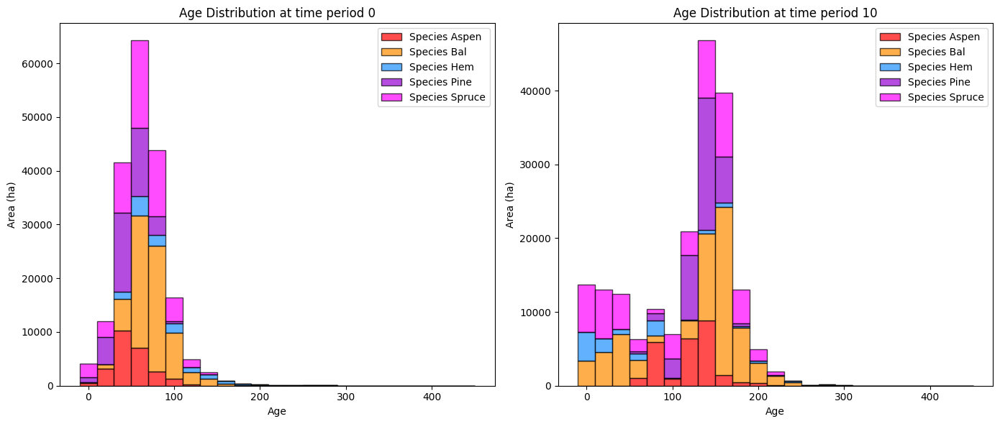

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                 0           10   Difference
Spruce    2.708533  4193.083821  4190.375287
Bal     278.565372  9045.947970  8767.382599
Aspen   273.490478  7151.110261  6877.619783
Pine      0.000000  6650.455938  6650.455938
Hem     419.699331   710.903413   291.204082

Overall diversity has **increased** by 26777.04 hectares from time period 0 to time period 10.


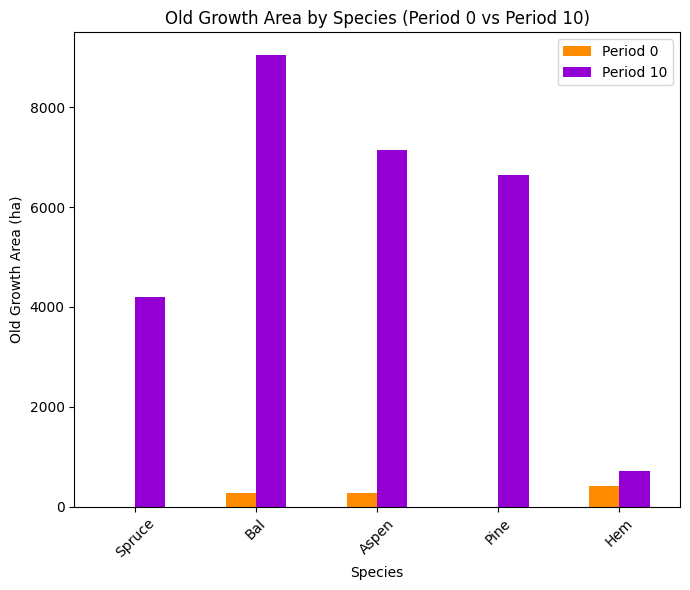

Clustered column plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.9455
Shannon Evenness Index for time period 10: 0.8856

Diversity has **decreased** by 5.99% from time 0 to time 10.


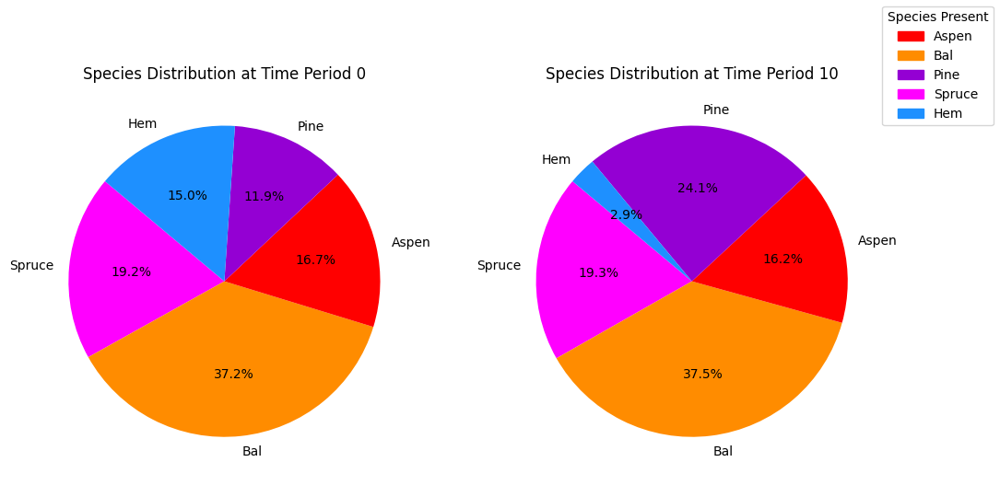

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_species_pie.pdf


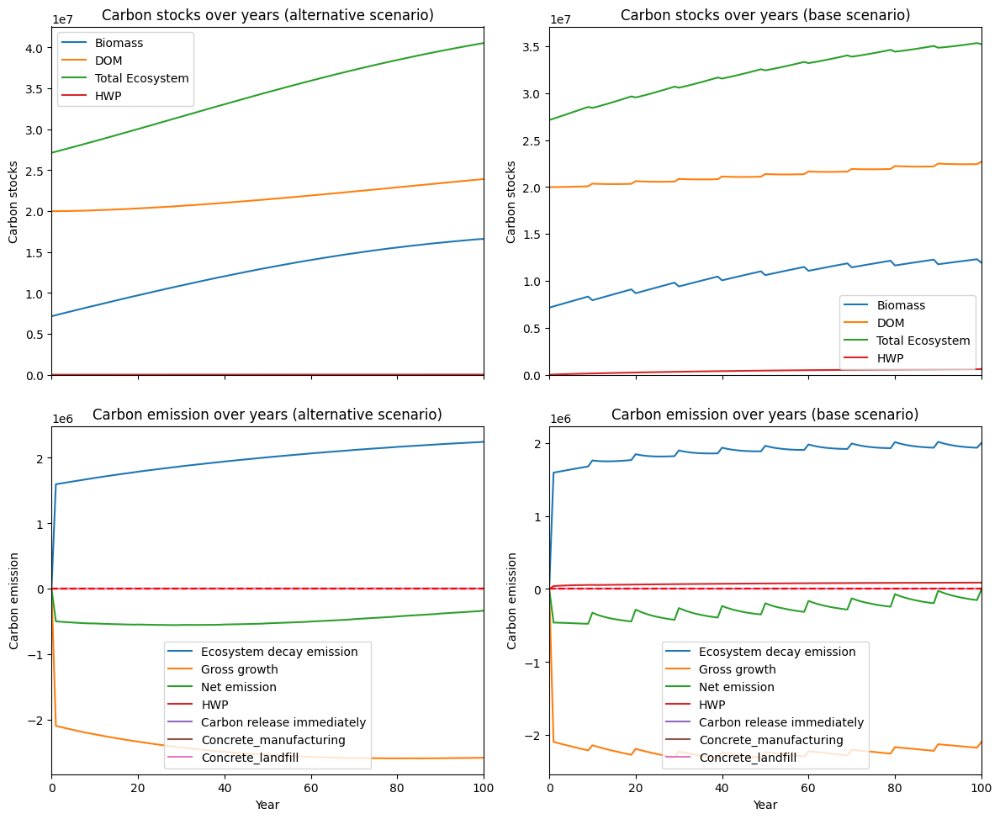

---------------------------------------------------------------------------------------
Net emission difference -2974136.7038540253
Net emission base scenario -12814836.966957904
Net emission alternative scenario -9840700.263103876
dollar_per_ton is:  3.362320227930859
Comparison of Old Growth Areas (Alternative - Base)
          0           10   Difference
Spruce  0.0  3780.573862  3780.573862
Bal     0.0  6884.197835  6884.197835
Aspen   0.0  6040.508011  6040.508011
Pine    0.0   981.431263   981.431263
Hem     0.0  2701.136517  2701.136517

Overall, the old growth area has **increased** by 20387.85 hectares in the alternative scenario compared to the base scenario.


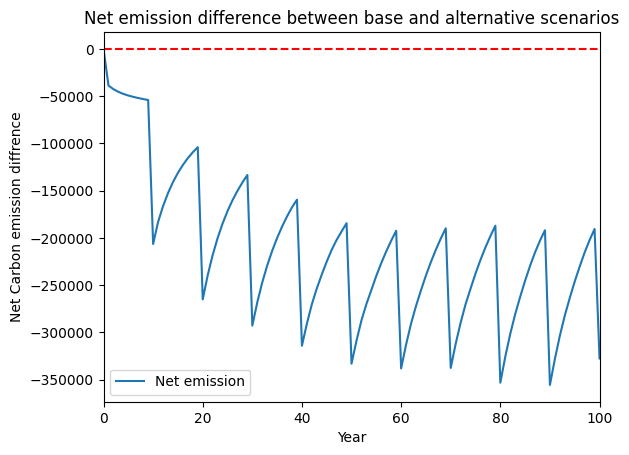

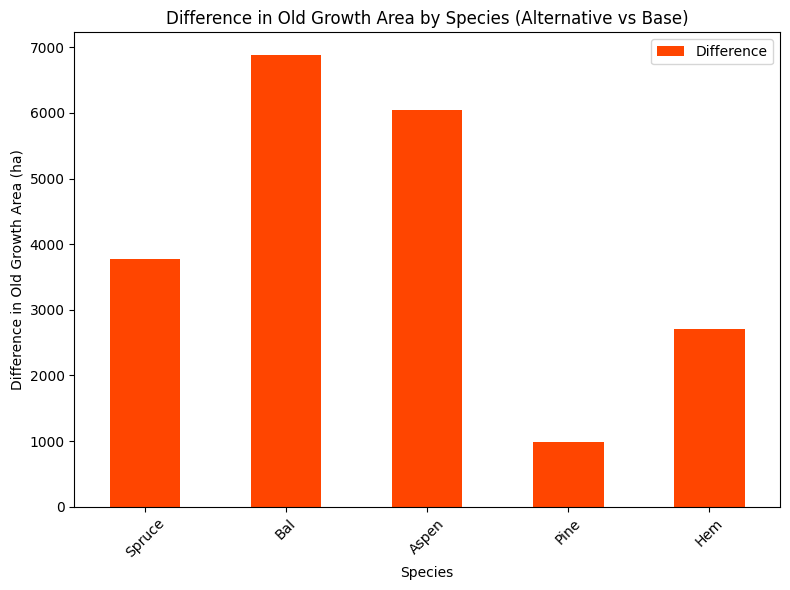

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_kpi_age_difference.pdf


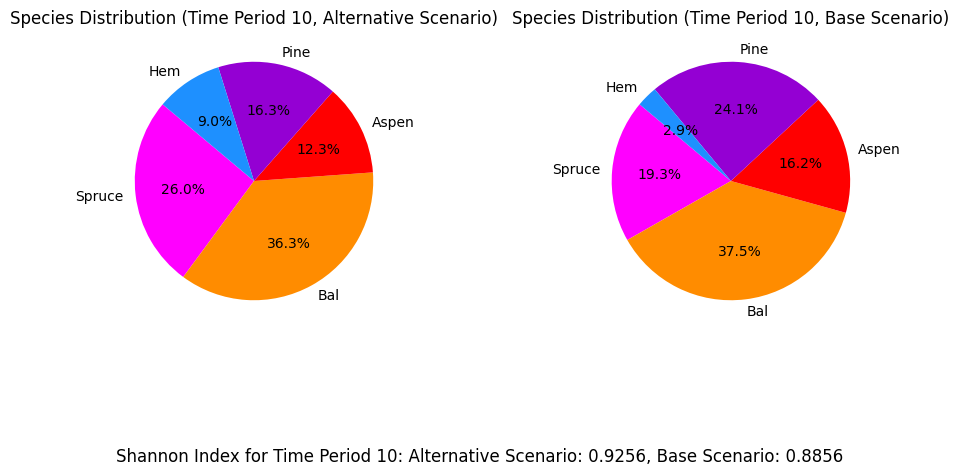

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
Running for goldenbear_max_st_bau_gldbr...
running business as usual scenario for the Golden Bear mine site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 3949 rows, 36130 columns and 470612 nonzeros
Model fingerprint: 0x7ea88e1f
Coefficient statistics:
  Matrix range     [1e-02, 1e+05]
  Objective range  [2e+02, 1e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 4e+07]
Presolve removed 2037 rows and 2031 columns
Presolve time: 0.13s
Presolved: 1912 rows, 34099 columns, 421112 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier lo

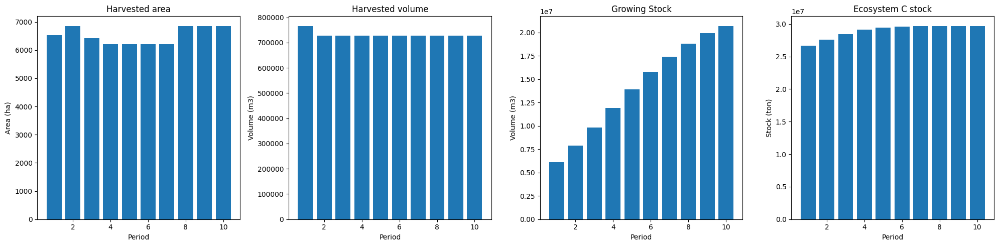

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  7734
The economic indicator (the provincial government revenues) is:  263762
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


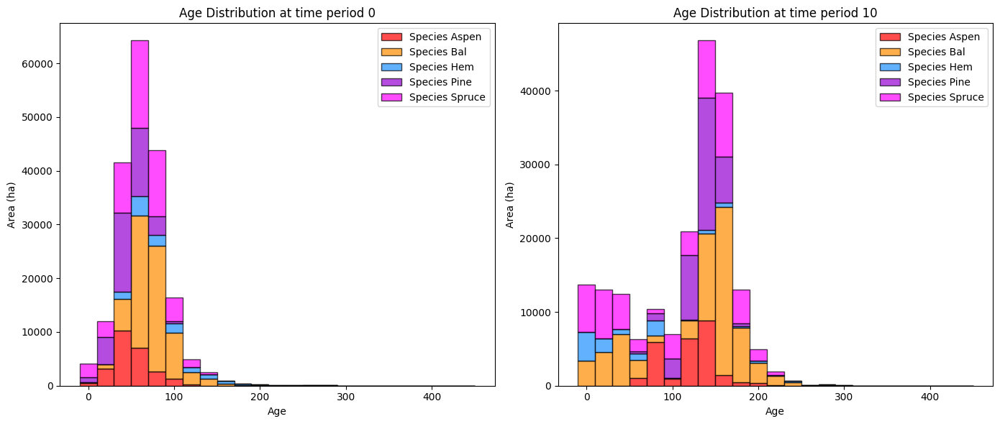

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                 0           10   Difference
Spruce    2.708533  4193.083821  4190.375287
Bal     278.565372  9045.947970  8767.382599
Aspen   273.490478  7151.110261  6877.619783
Pine      0.000000  6650.455938  6650.455938
Hem     419.699331   710.903413   291.204082

Overall diversity has **increased** by 26777.04 hectares from time period 0 to time period 10.


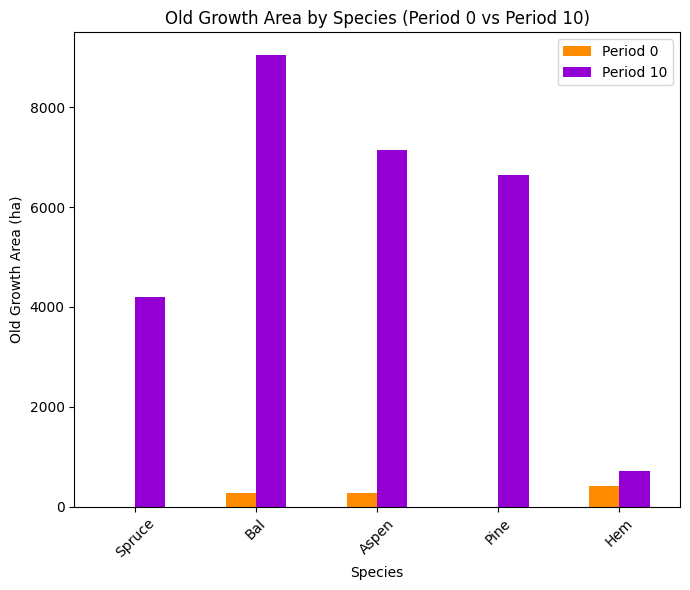

Clustered column plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.9455
Shannon Evenness Index for time period 10: 0.8856

Diversity has **decreased** by 5.99% from time 0 to time 10.


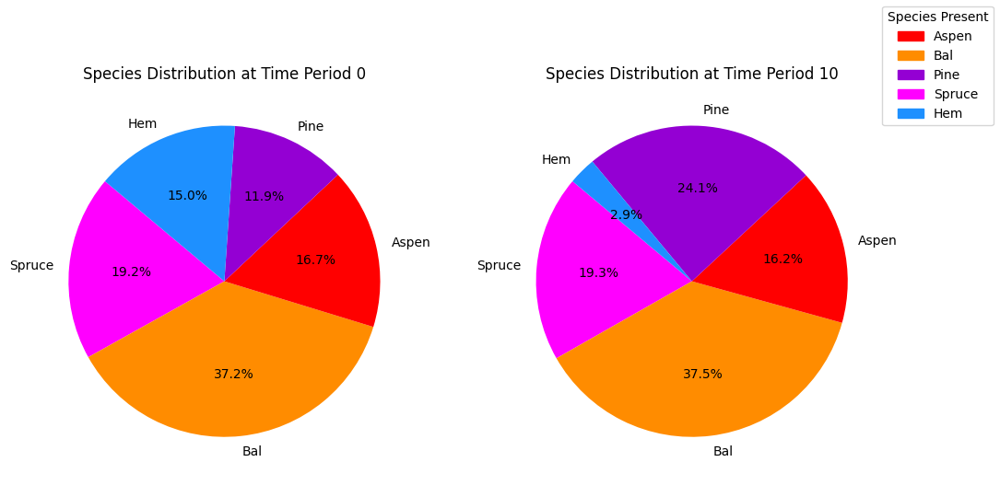

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_species_pie.pdf
running business as usual scenario for the Golden Bear mine site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 3949 rows, 36130 columns and 470612 nonzeros
Model fingerprint: 0x7ea88e1f
Coefficient statistics:
  Matrix range     [1e-02, 1e+05]
  Objective range  [2e+02, 1e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 4e+07]
Presolve removed 2037 rows and 2031 columns
Presolve time: 0.14s
Presolved: 1912 rows, 34099 columns, 421112 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Ordering time: 0.00s

Barrier statistics:
 AA' NZ     : 6.876e+04
 Factor NZ  : 9.245e+04 (roughly 15 MB of memory)
 Factor O

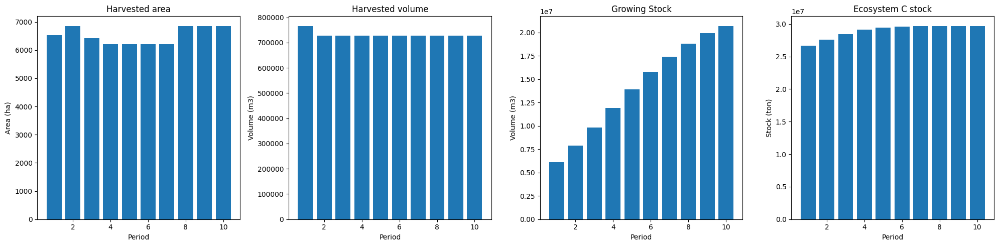

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  7734
The economic indicator (the provincial government revenues) is:  263762
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


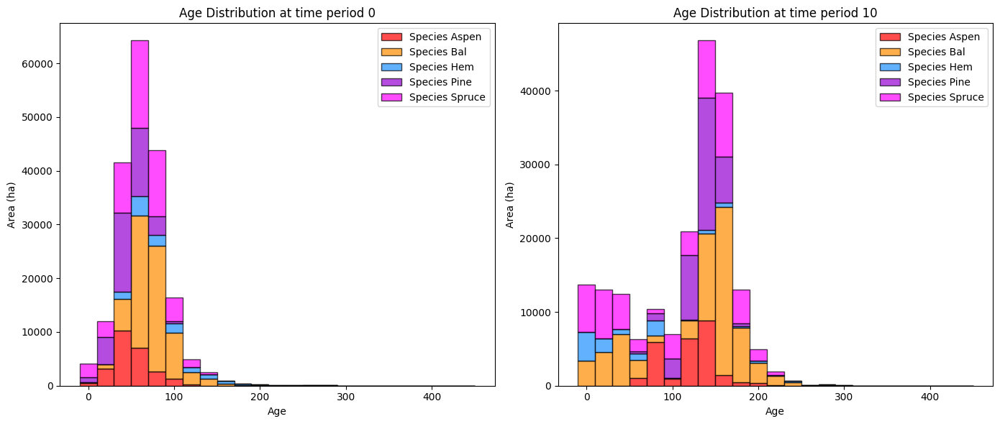

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                 0           10   Difference
Spruce    2.708533  4193.083821  4190.375287
Bal     278.565372  9045.947970  8767.382599
Aspen   273.490478  7151.110261  6877.619783
Pine      0.000000  6650.455938  6650.455938
Hem     419.699331   710.903413   291.204082

Overall diversity has **increased** by 26777.04 hectares from time period 0 to time period 10.


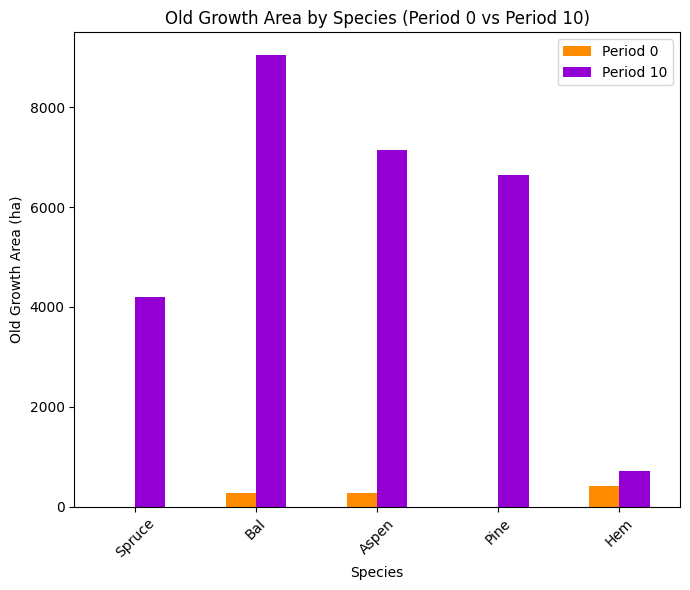

Clustered column plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.9455
Shannon Evenness Index for time period 10: 0.8856

Diversity has **decreased** by 5.99% from time 0 to time 10.


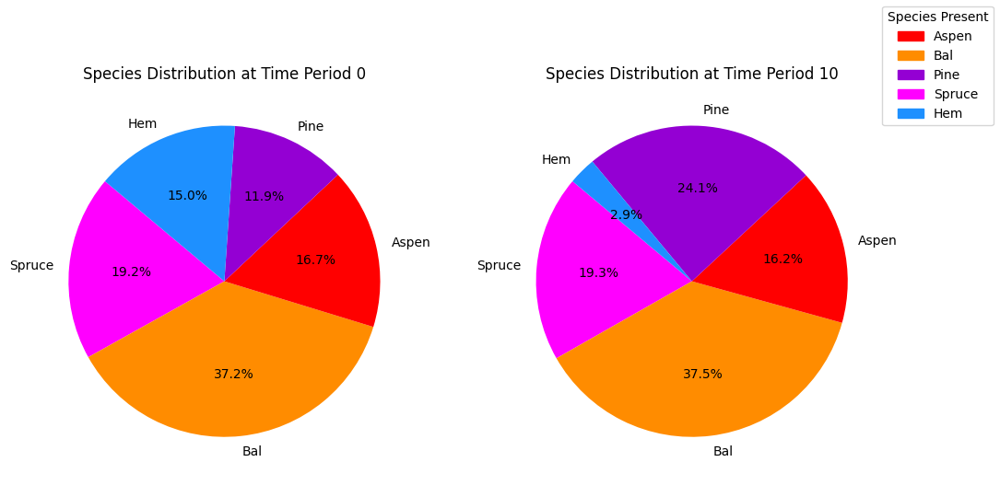

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_species_pie.pdf


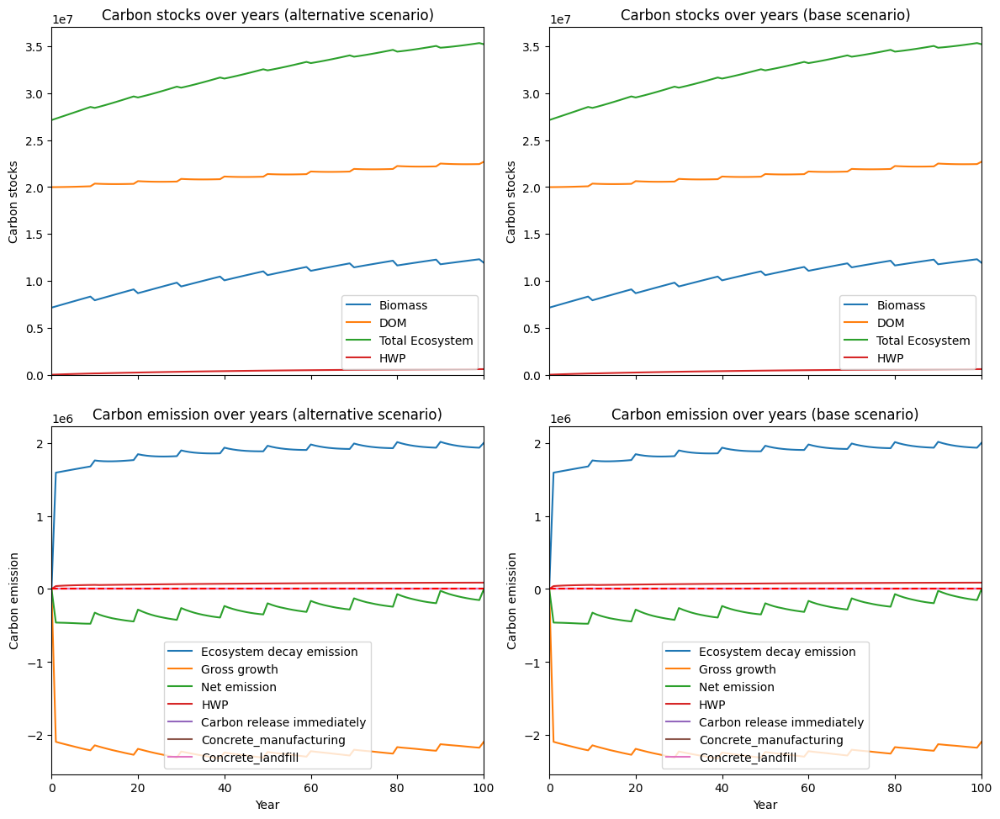

---------------------------------------------------------------------------------------
Net emission difference 0.0
Net emission base scenario -9840700.263103876
Net emission alternative scenario -9840700.263103876
dollar_per_ton is:  inf
Comparison of Old Growth Areas (Alternative - Base)
          0   10  Difference
Spruce  0.0  0.0         0.0
Bal     0.0  0.0         0.0
Aspen   0.0  0.0         0.0
Pine    0.0  0.0         0.0
Hem     0.0  0.0         0.0

Overall, the old growth area has **increased** by 0.00 hectares in the alternative scenario compared to the base scenario.


/media/data/project/eghasemi/nbds_mining/util_opt.py:1211: RuntimeWarning: divide by zero encountered in scalar divide
  dollar_per_ton = abs(budget_input / dif_scenario.iloc[:25]['Net emission'].sum())


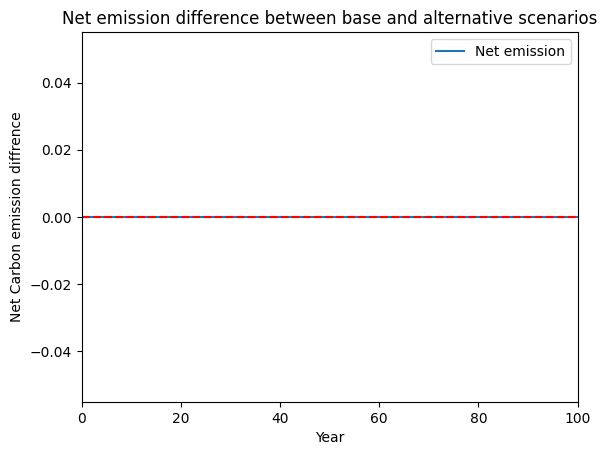

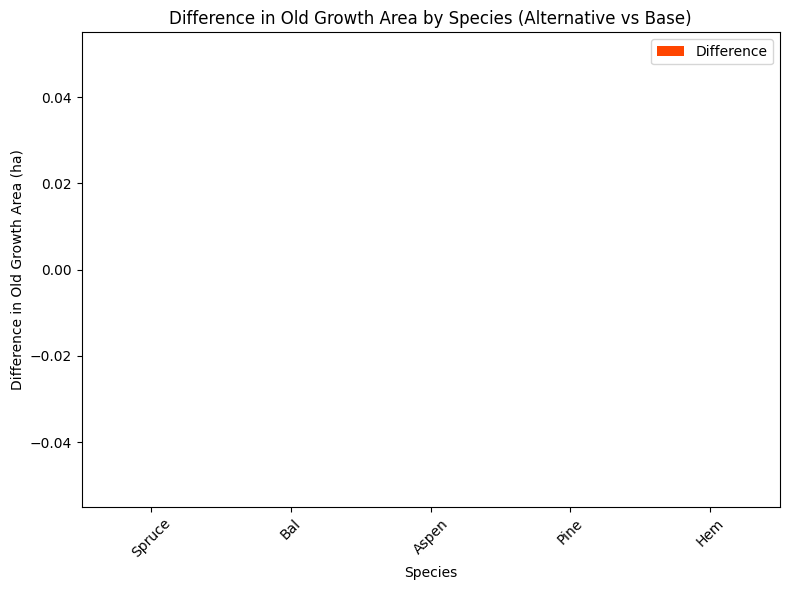

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_kpi_age_difference.pdf


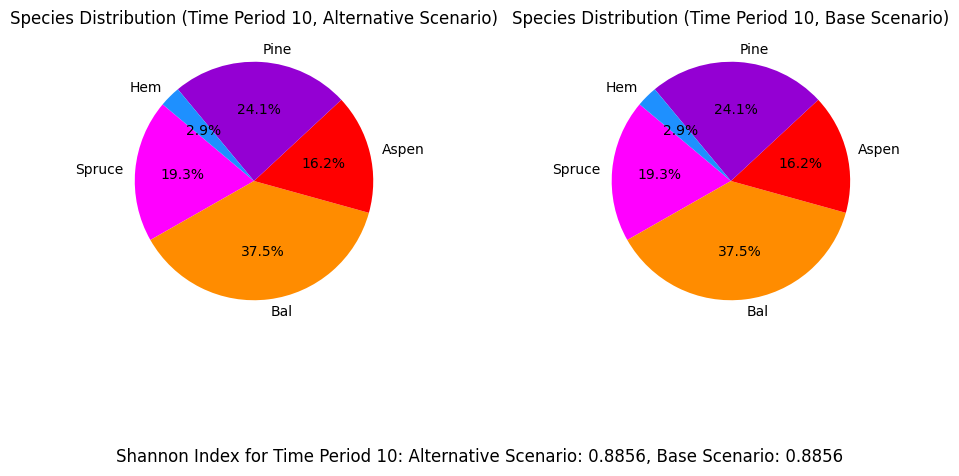

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
Running for goldenbear_max_st_gldbr_AAC_90%...
running the scenario for the Golden Bear mining site (90%_AAC),
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 3949 rows, 36130 columns and 470612 nonzeros
Model fingerprint: 0x10e84045
Coefficient statistics:
  Matrix range     [1e-02, 1e+05]
  Objective range  [2e+02, 1e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 7e+09]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 2038 rows and 2031 columns
Presolve time: 0.13s
Presolved: 1911 rows, 34100 

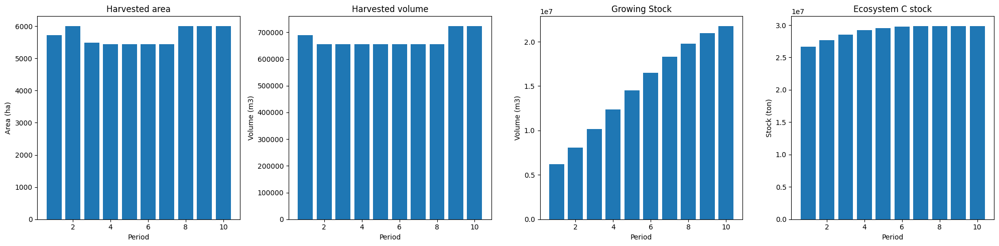

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_90%_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  7106
The economic indicator (the provincial government revenues) is:  242357
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


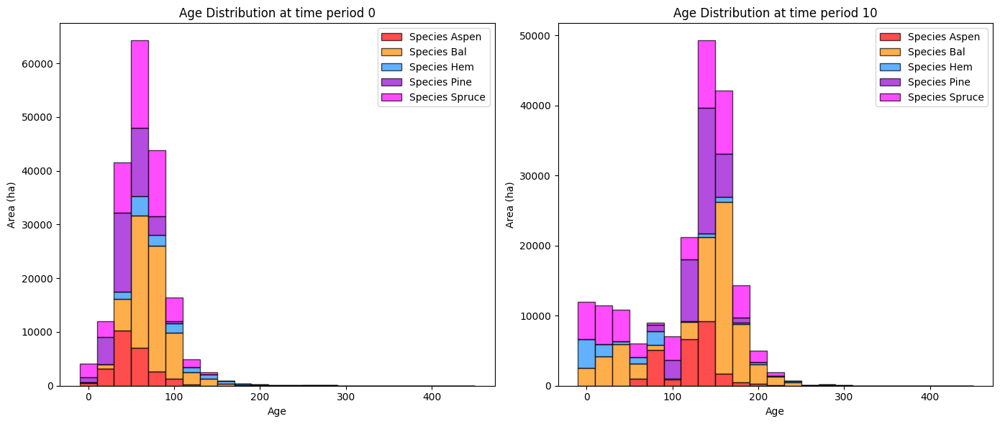

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_90%_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                 0           10   Difference
Spruce    2.708533  4498.772127  4496.063594
Bal     278.565372  9786.248962  9507.683590
Aspen   273.490478  7796.518322  7523.027844
Pine      0.000000  6902.802138  6902.802138
Hem     419.699331   731.925091   312.225760

Overall diversity has **increased** by 28741.80 hectares from time period 0 to time period 10.


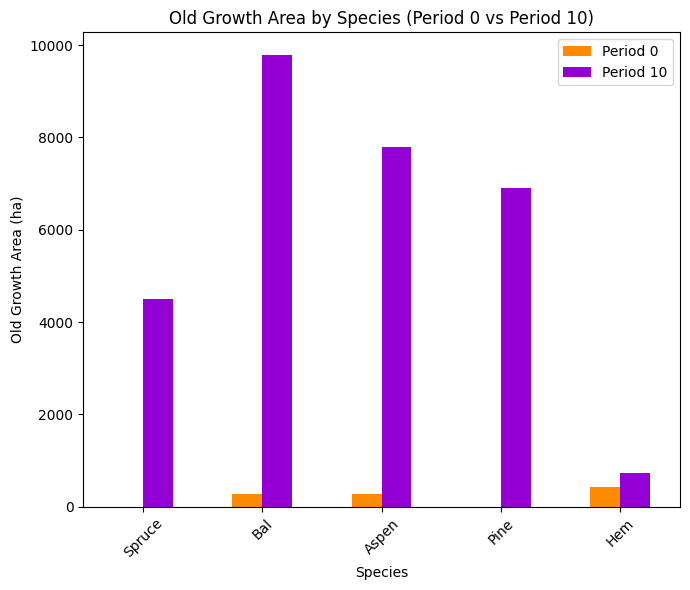

Clustered column plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_90%_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.9455
Shannon Evenness Index for time period 10: 0.8838

Diversity has **decreased** by 6.18% from time 0 to time 10.


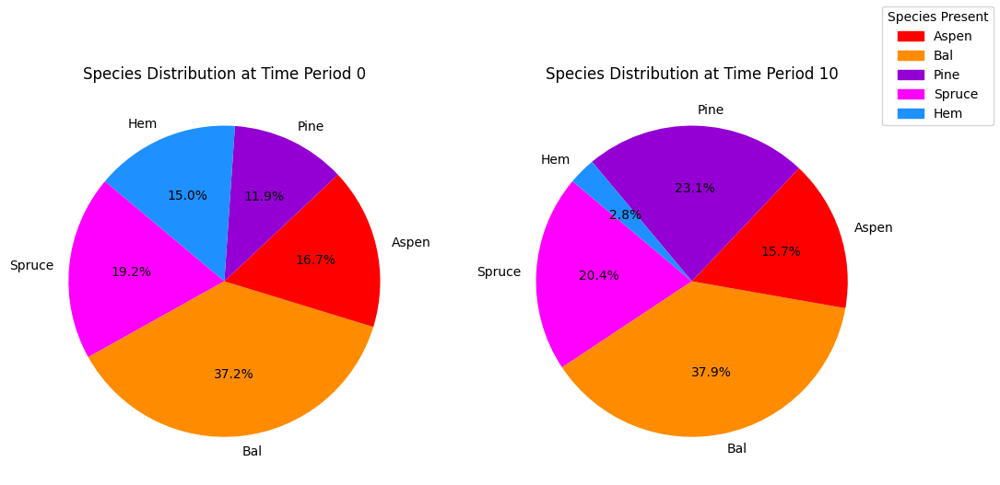

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_90%_species_pie.pdf
running business as usual scenario for the Golden Bear mine site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 3949 rows, 36130 columns and 470612 nonzeros
Model fingerprint: 0x7ea88e1f
Coefficient statistics:
  Matrix range     [1e-02, 1e+05]
  Objective range  [2e+02, 1e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 4e+07]
Presolve removed 2037 rows and 2031 columns
Presolve time: 0.19s
Presolved: 1912 rows, 34099 columns, 421112 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Ordering time: 0.00s

Barrier statistics:
 AA' NZ     : 6.876e+04
 Factor NZ  : 9.245e+04 (roughly 15 MB of memory)
 Fact

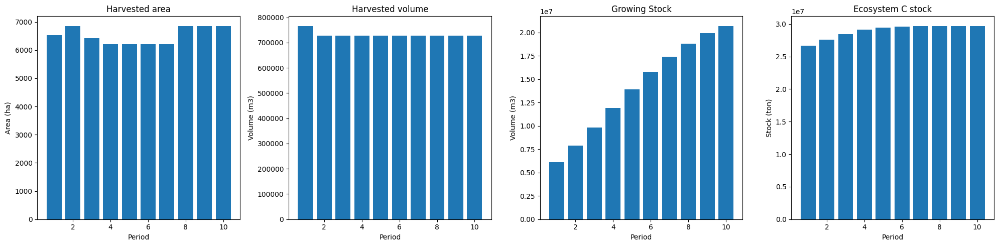

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  7734
The economic indicator (the provincial government revenues) is:  263762
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


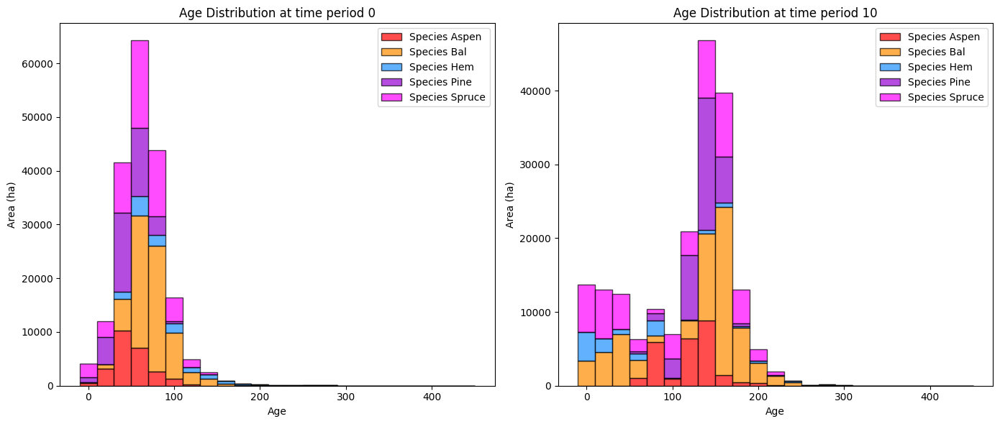

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                 0           10   Difference
Spruce    2.708533  4193.083821  4190.375287
Bal     278.565372  9045.947970  8767.382599
Aspen   273.490478  7151.110261  6877.619783
Pine      0.000000  6650.455938  6650.455938
Hem     419.699331   710.903413   291.204082

Overall diversity has **increased** by 26777.04 hectares from time period 0 to time period 10.


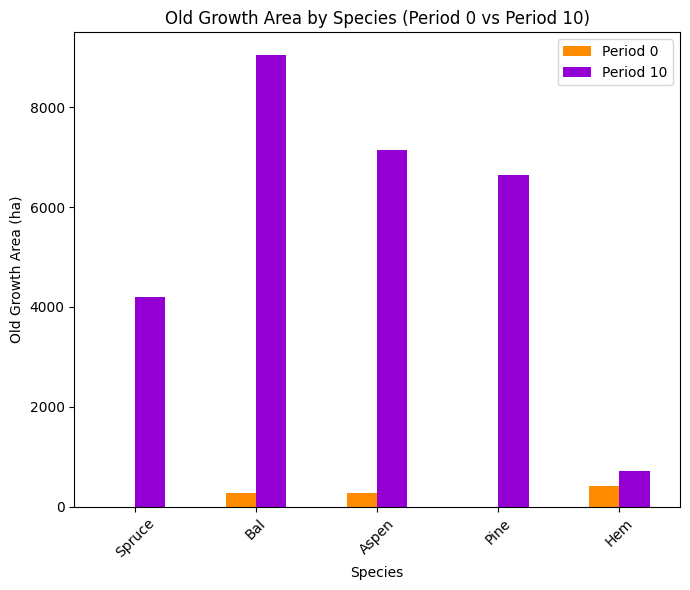

Clustered column plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.9455
Shannon Evenness Index for time period 10: 0.8856

Diversity has **decreased** by 5.99% from time 0 to time 10.


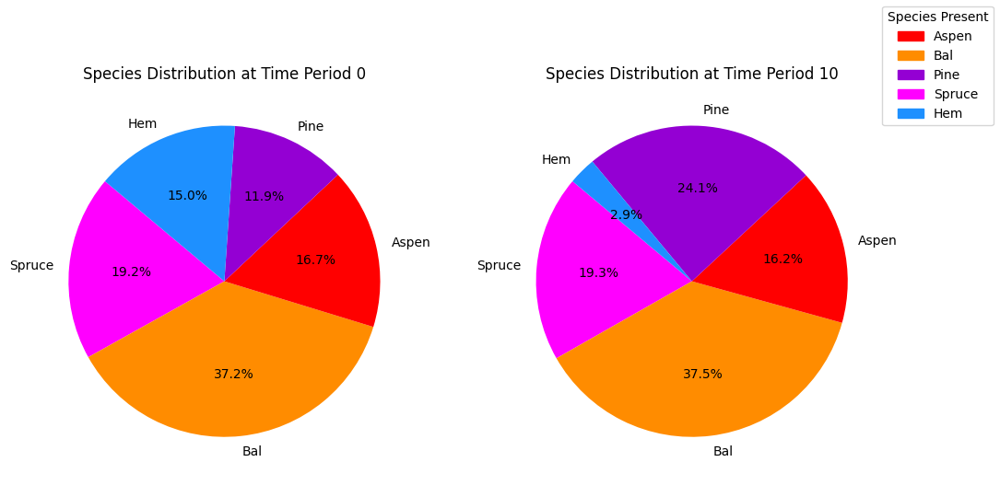

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_species_pie.pdf


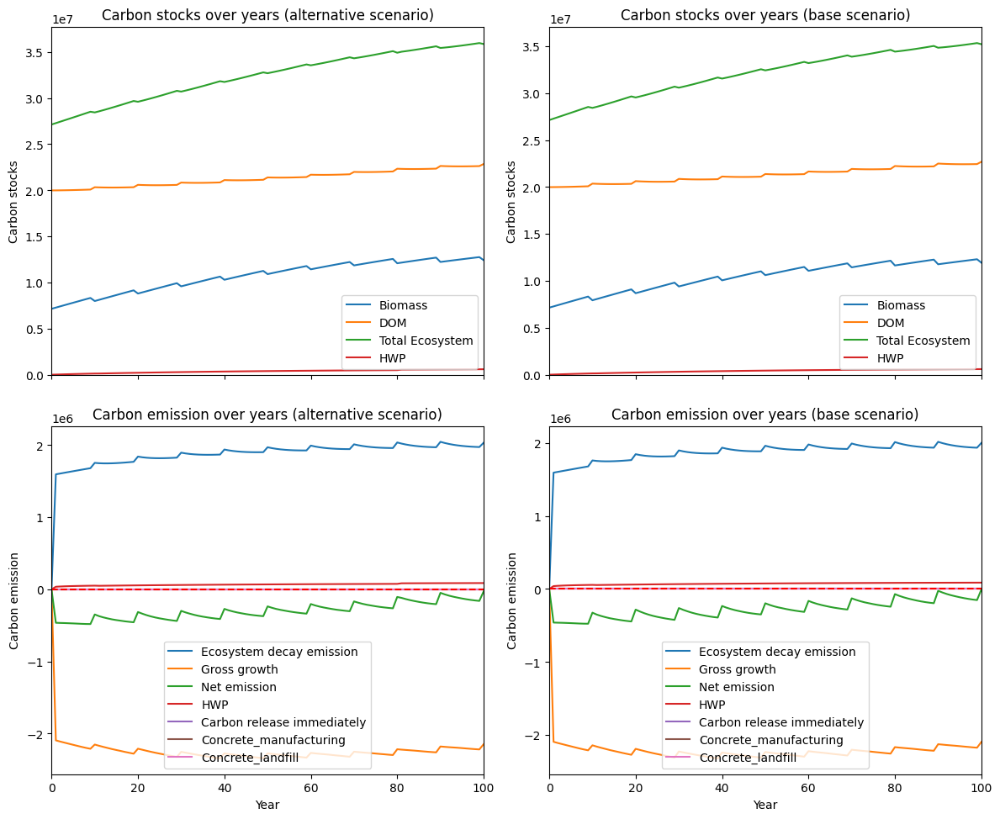

---------------------------------------------------------------------------------------
Net emission difference -344218.56577344413
Net emission base scenario -10184918.828877324
Net emission alternative scenario -9840700.263103876
dollar_per_ton is:  29.05130923874032
Comparison of Old Growth Areas (Alternative - Base)
          0          10  Difference
Spruce  0.0  305.688306  305.688306
Bal     0.0  740.300991  740.300991
Aspen   0.0  645.408060  645.408060
Pine    0.0  252.346200  252.346200
Hem     0.0   21.021677   21.021677

Overall, the old growth area has **increased** by 1964.77 hectares in the alternative scenario compared to the base scenario.


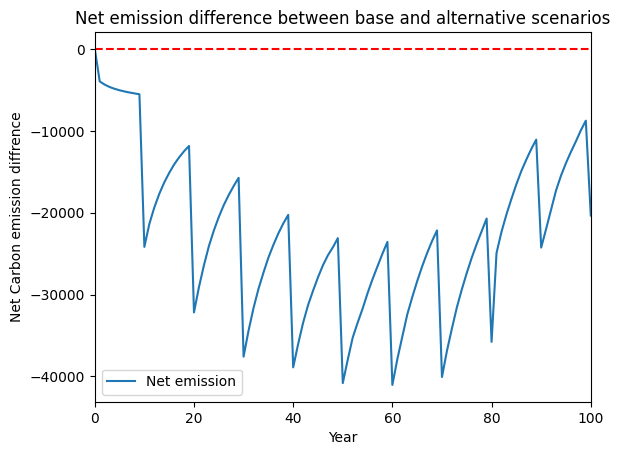

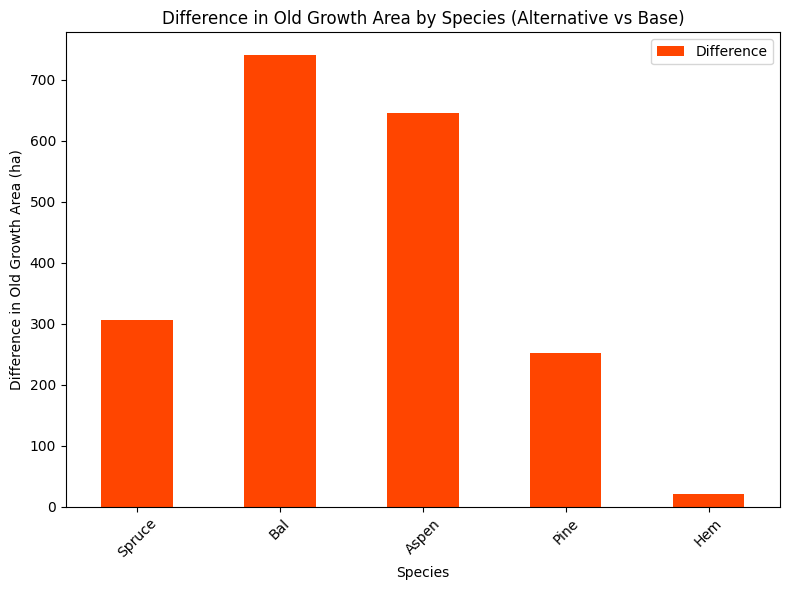

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_kpi_age_difference.pdf


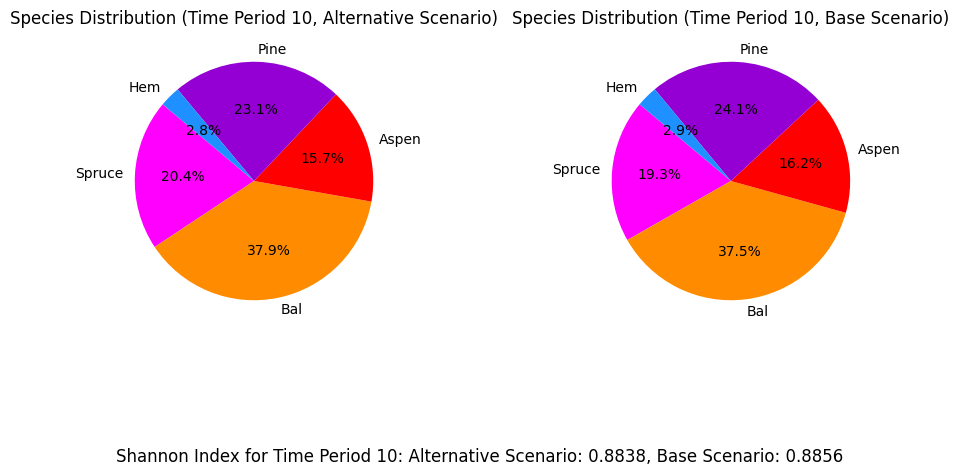

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
Running for goldenbear_max_st_gldbr_AAC_80%...
running the scenario for the Golden Bear mining site (80%_AAC),
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 3949 rows, 36130 columns and 470612 nonzeros
Model fingerprint: 0xdbe64f6a
Coefficient statistics:
  Matrix range     [1e-02, 1e+05]
  Objective range  [2e+02, 1e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 7e+09]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 2038 rows and 2031 columns
Presolve time: 0.16s
Presolved: 1911 rows, 34100 

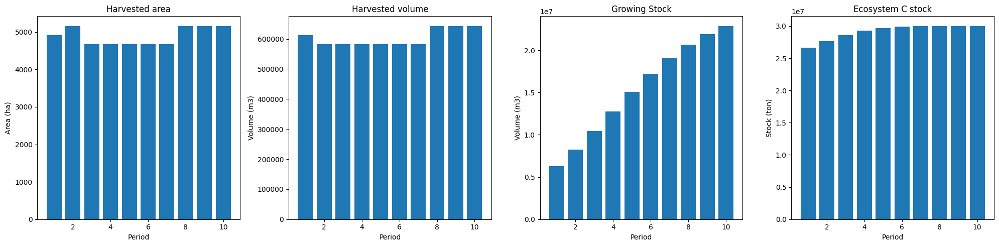

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_80%_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  6381
The economic indicator (the provincial government revenues) is:  217638
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


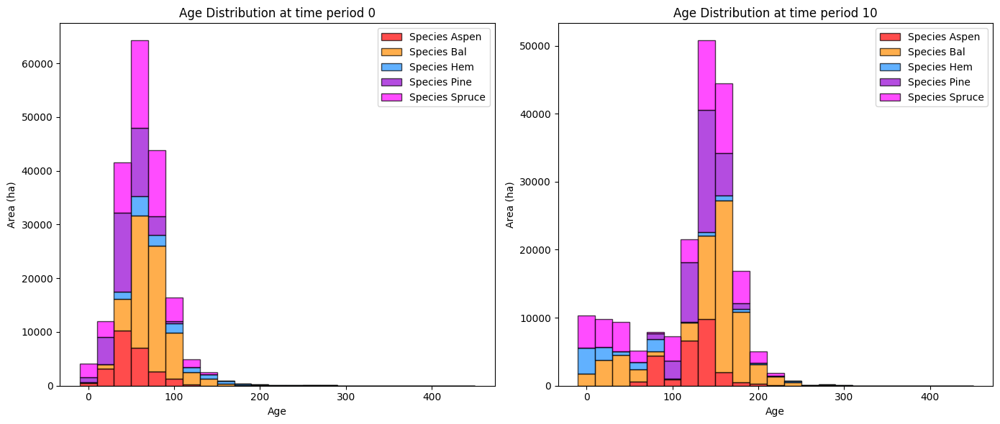

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_80%_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                 0            10    Difference
Spruce    2.708533   4751.857024   4749.148491
Bal     278.565372  10667.530805  10388.965433
Aspen   273.490478   8559.557428   8286.066950
Pine      0.000000   6976.016150   6976.016150
Hem     419.699331    759.720458    340.021127

Overall diversity has **increased** by 30740.22 hectares from time period 0 to time period 10.


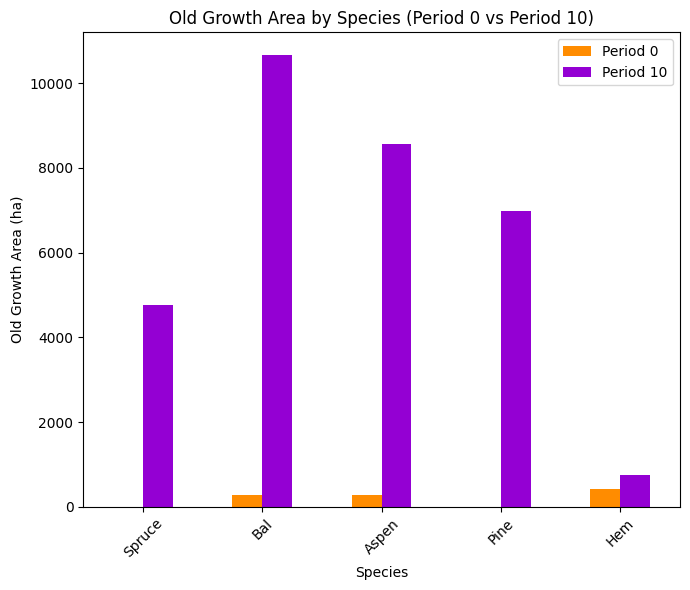

Clustered column plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_80%_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.9455
Shannon Evenness Index for time period 10: 0.8807

Diversity has **decreased** by 6.48% from time 0 to time 10.


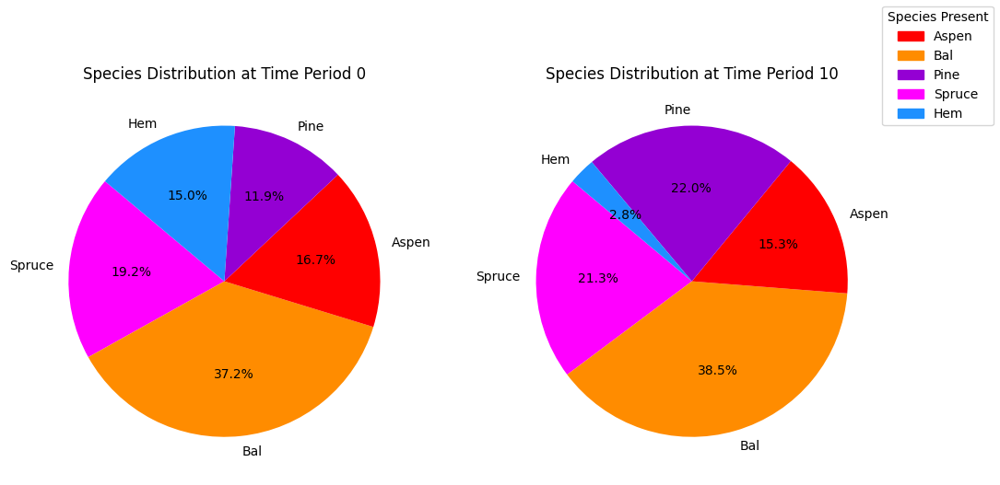

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_80%_species_pie.pdf
running business as usual scenario for the Golden Bear mine site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 3949 rows, 36130 columns and 470612 nonzeros
Model fingerprint: 0x7ea88e1f
Coefficient statistics:
  Matrix range     [1e-02, 1e+05]
  Objective range  [2e+02, 1e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 4e+07]
Presolve removed 2037 rows and 2031 columns
Presolve time: 0.19s
Presolved: 1912 rows, 34099 columns, 421112 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Ordering time: 0.00s

Barrier statistics:
 AA' NZ     : 6.876e+04
 Factor NZ  : 9.245e+04 (roughly 15 MB of memory)
 Fact

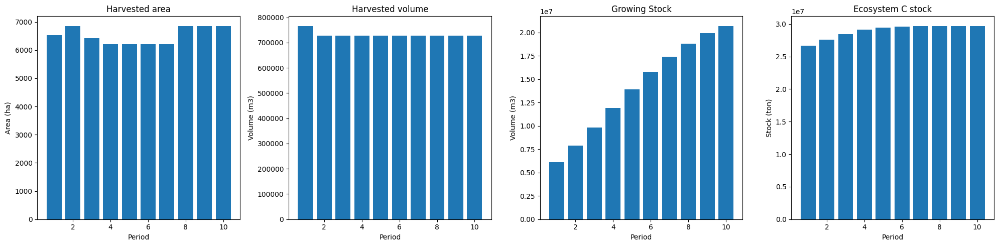

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  7734
The economic indicator (the provincial government revenues) is:  263762
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


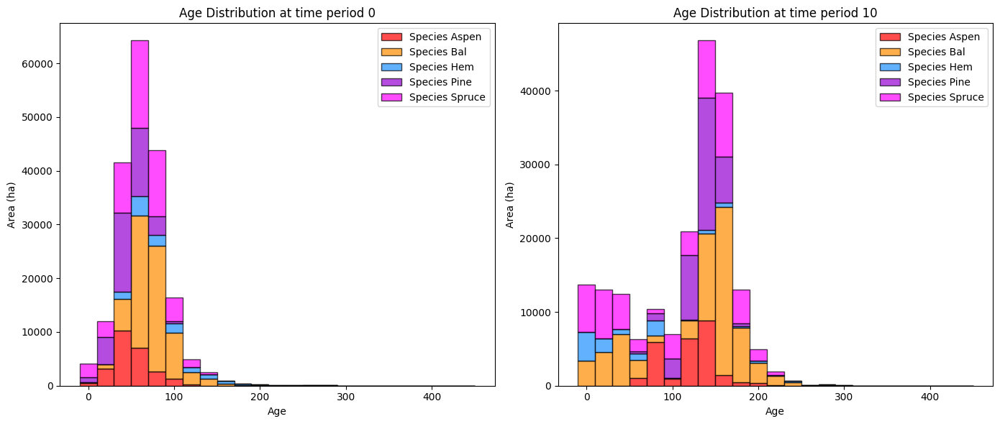

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                 0           10   Difference
Spruce    2.708533  4193.083821  4190.375287
Bal     278.565372  9045.947970  8767.382599
Aspen   273.490478  7151.110261  6877.619783
Pine      0.000000  6650.455938  6650.455938
Hem     419.699331   710.903413   291.204082

Overall diversity has **increased** by 26777.04 hectares from time period 0 to time period 10.


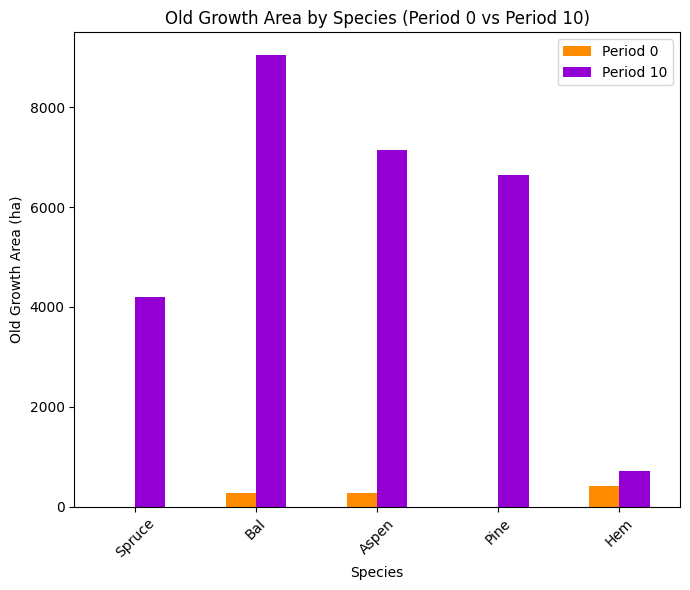

Clustered column plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.9455
Shannon Evenness Index for time period 10: 0.8856

Diversity has **decreased** by 5.99% from time 0 to time 10.


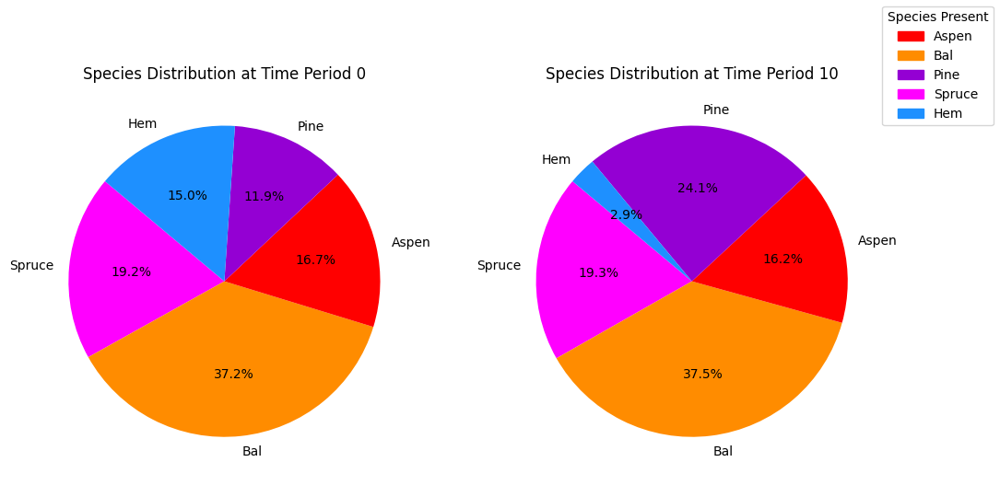

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_species_pie.pdf


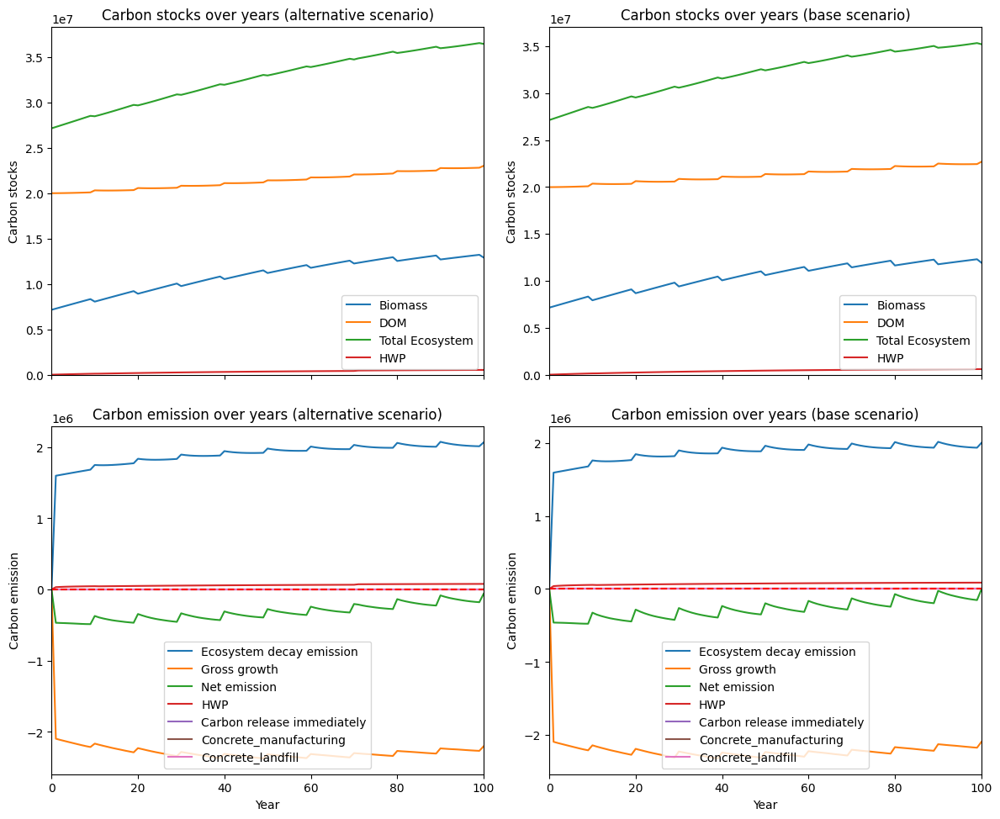

---------------------------------------------------------------------------------------
Net emission difference -677513.3063454145
Net emission base scenario -10518213.569449294
Net emission alternative scenario -9840700.263103876
dollar_per_ton is:  14.759857712523997
Comparison of Old Growth Areas (Alternative - Base)
          0           10   Difference
Spruce  0.0   558.773203   558.773203
Bal     0.0  1621.582834  1621.582834
Aspen   0.0  1408.447167  1408.447167
Pine    0.0   325.560213   325.560213
Hem     0.0    48.817044    48.817044

Overall, the old growth area has **increased** by 3963.18 hectares in the alternative scenario compared to the base scenario.


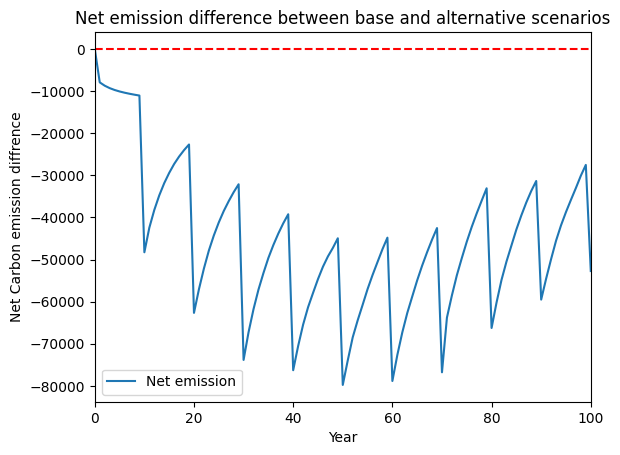

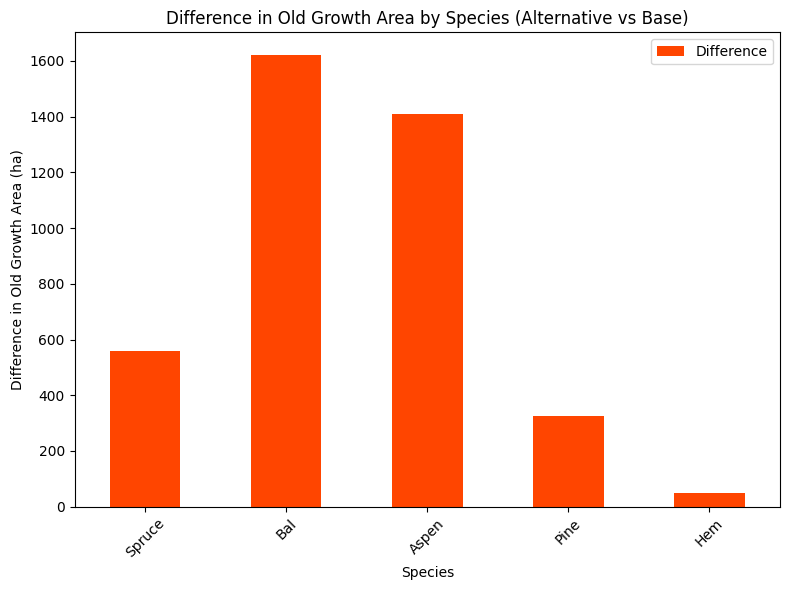

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_kpi_age_difference.pdf


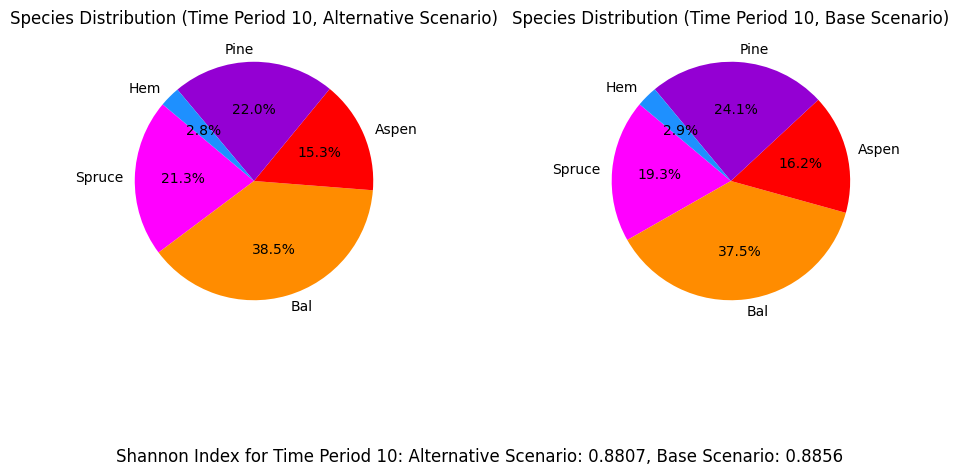

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
Running for goldenbear_max_st_gldbr_AAC_70%...
running the scenario for the Golden Bear mining site (70%_AAC),
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 3949 rows, 36130 columns and 470612 nonzeros
Model fingerprint: 0x5e7ce2dc
Coefficient statistics:
  Matrix range     [1e-02, 1e+05]
  Objective range  [2e+02, 1e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 7e+09]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 2038 rows and 2031 columns
Presolve time: 0.21s
Presolved: 1911 rows, 34100 

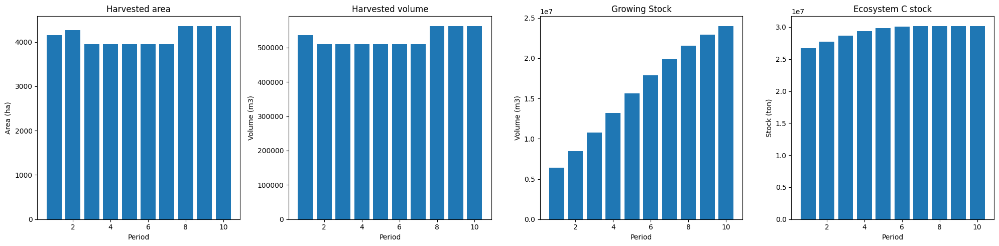

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_70%_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  5584
The economic indicator (the provincial government revenues) is:  190433
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


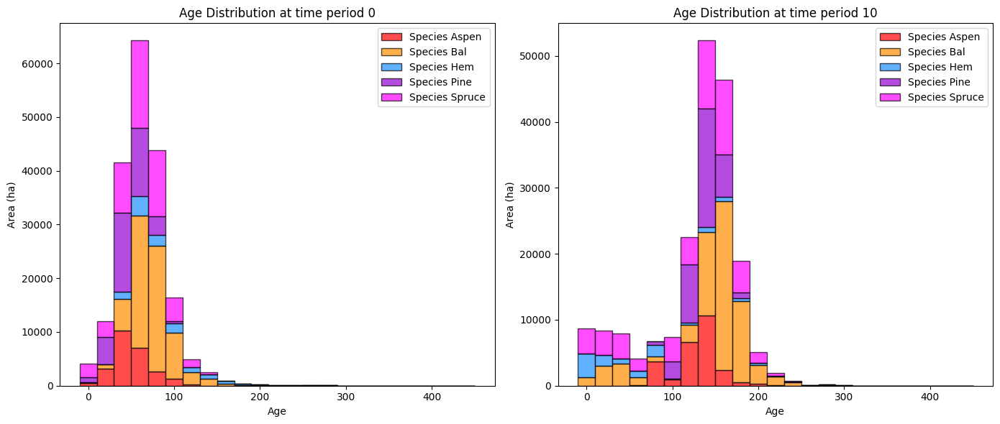

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_70%_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                 0            10    Difference
Spruce    2.708533   4867.746044   4865.037511
Bal     278.565372  11490.228389  11211.663018
Aspen   273.490478   9540.490036   9266.999558
Pine      0.000000   7206.327965   7206.327965
Hem     419.699331    779.239284    359.539953

Overall diversity has **increased** by 32909.57 hectares from time period 0 to time period 10.


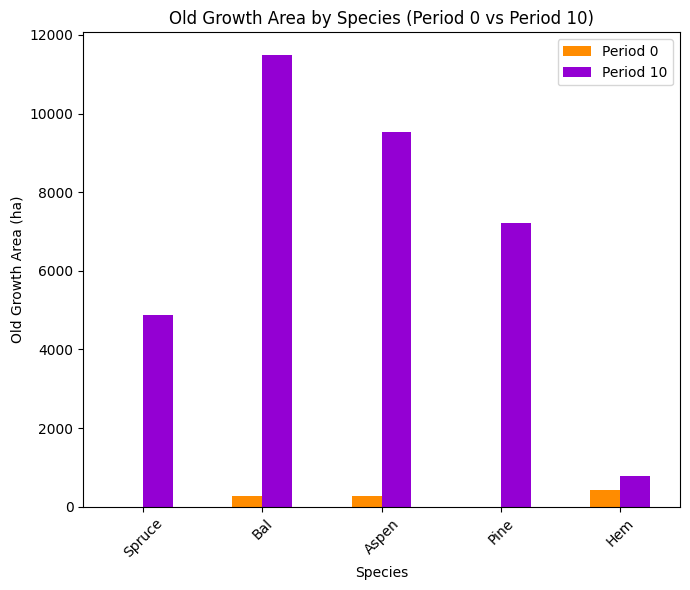

Clustered column plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_70%_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.9455
Shannon Evenness Index for time period 10: 0.8828

Diversity has **decreased** by 6.28% from time 0 to time 10.


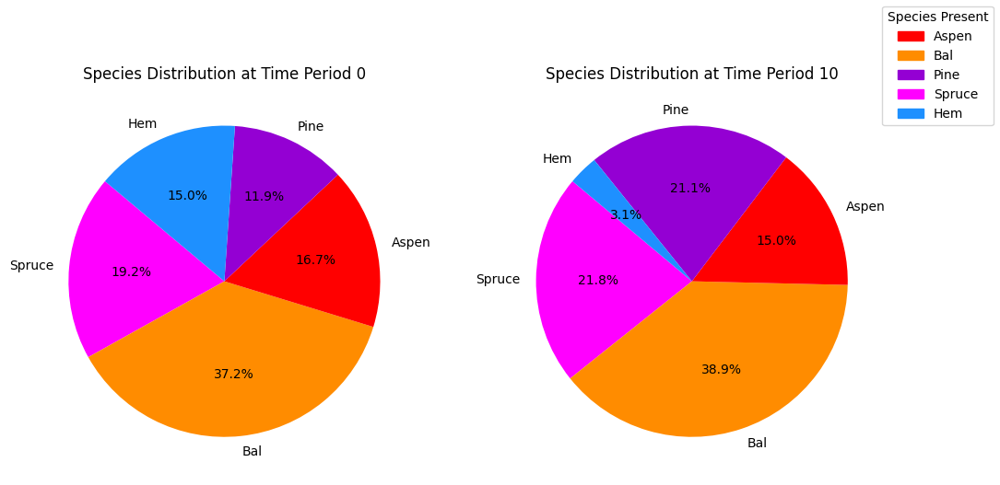

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_70%_species_pie.pdf
running business as usual scenario for the Golden Bear mine site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 3949 rows, 36130 columns and 470612 nonzeros
Model fingerprint: 0x7ea88e1f
Coefficient statistics:
  Matrix range     [1e-02, 1e+05]
  Objective range  [2e+02, 1e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 4e+07]
Presolve removed 2037 rows and 2031 columns
Presolve time: 0.19s
Presolved: 1912 rows, 34099 columns, 421112 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Ordering time: 0.00s

Barrier statistics:
 AA' NZ     : 6.876e+04
 Factor NZ  : 9.245e+04 (roughly 15 MB of memory)
 Fact

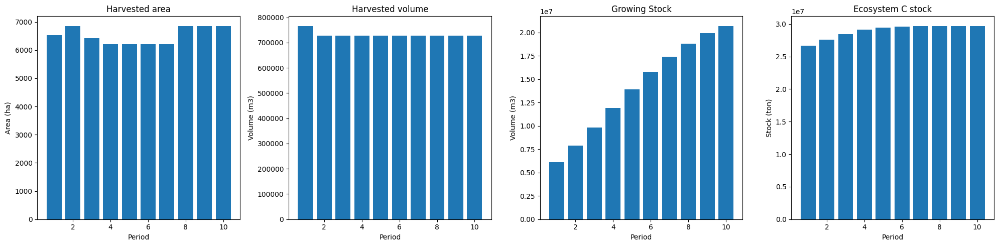

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  7734
The economic indicator (the provincial government revenues) is:  263762
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


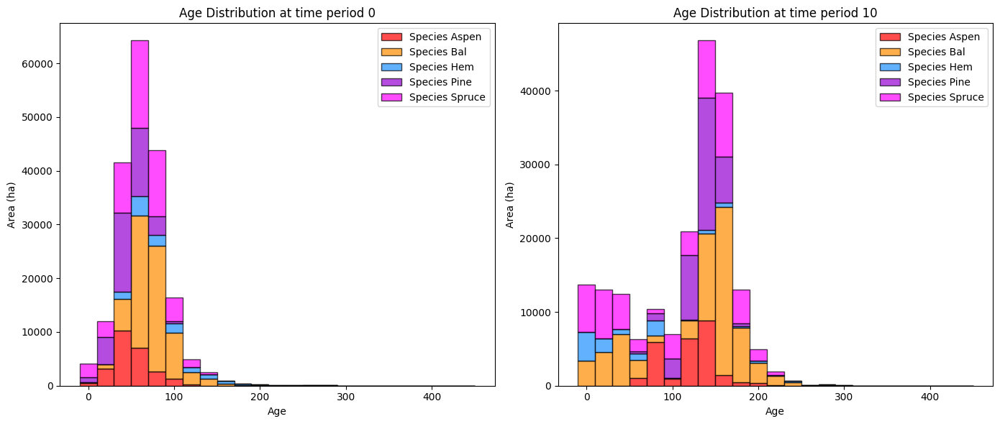

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                 0           10   Difference
Spruce    2.708533  4193.083821  4190.375287
Bal     278.565372  9045.947970  8767.382599
Aspen   273.490478  7151.110261  6877.619783
Pine      0.000000  6650.455938  6650.455938
Hem     419.699331   710.903413   291.204082

Overall diversity has **increased** by 26777.04 hectares from time period 0 to time period 10.


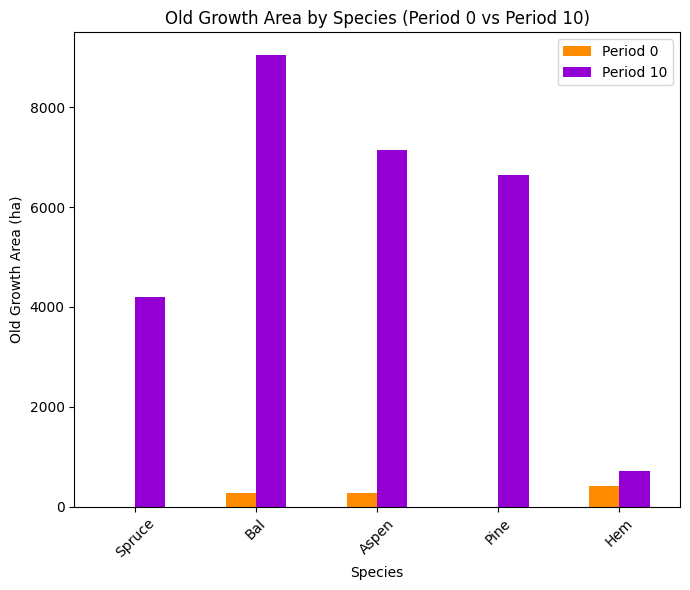

Clustered column plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.9455
Shannon Evenness Index for time period 10: 0.8856

Diversity has **decreased** by 5.99% from time 0 to time 10.


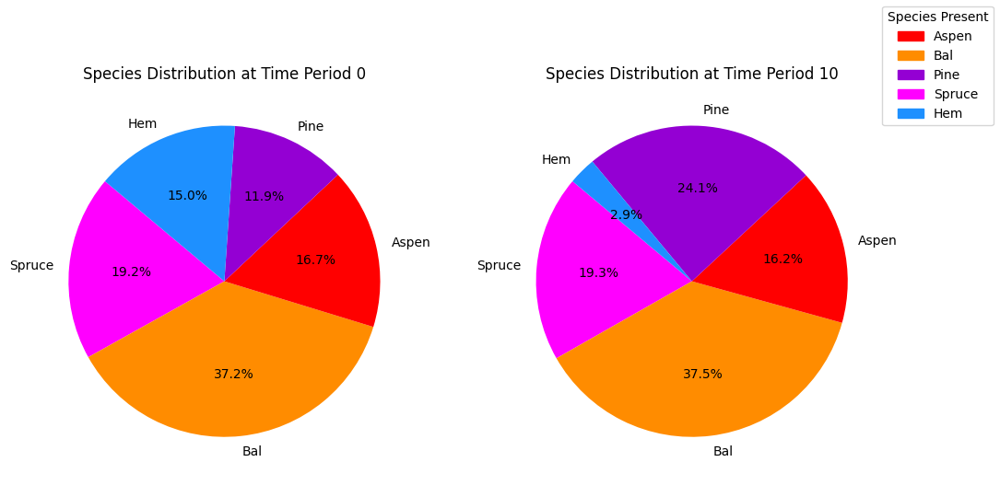

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_species_pie.pdf


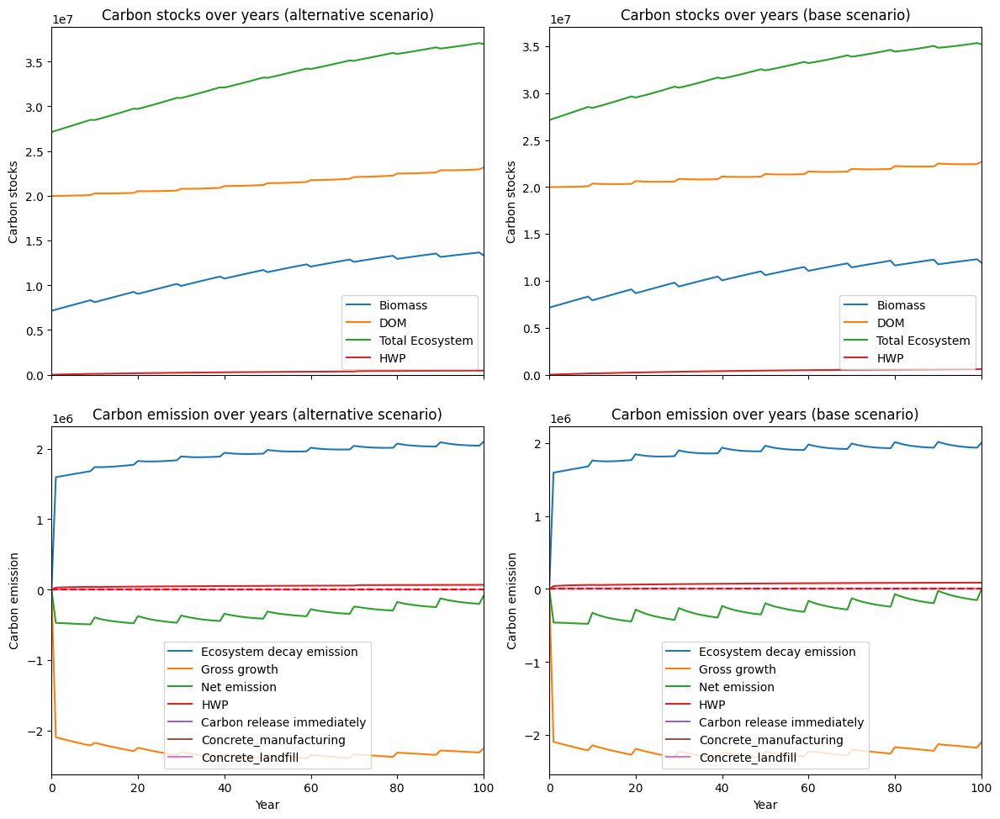

---------------------------------------------------------------------------------------
Net emission difference -1000608.3103465224
Net emission base scenario -10841308.573450401
Net emission alternative scenario -9840700.263103876
dollar_per_ton is:  9.99392059469992
Comparison of Old Growth Areas (Alternative - Base)
          0           10   Difference
Spruce  0.0   674.662224   674.662224
Bal     0.0  2444.280419  2444.280419
Aspen   0.0  2389.379775  2389.379775
Pine    0.0   555.872027   555.872027
Hem     0.0    68.335871    68.335871

Overall, the old growth area has **increased** by 6132.53 hectares in the alternative scenario compared to the base scenario.


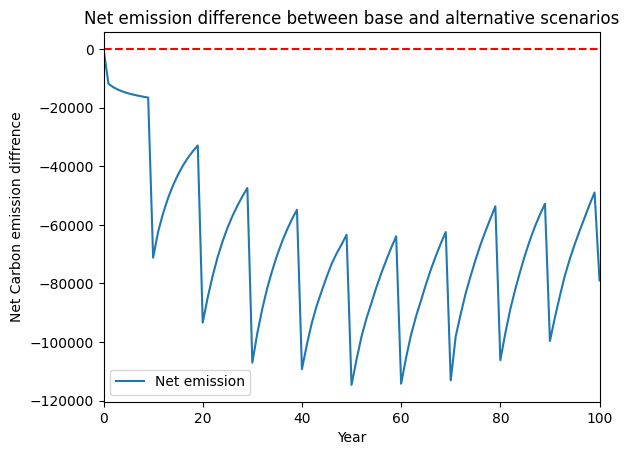

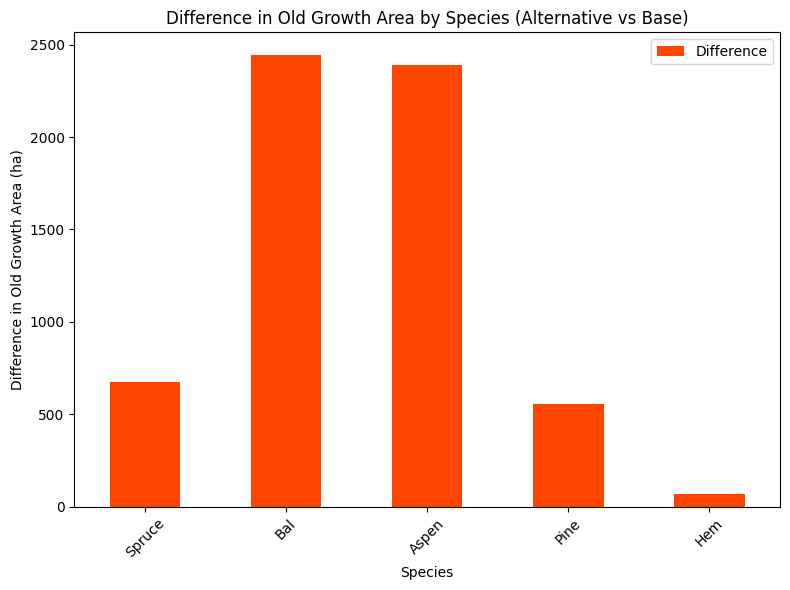

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_kpi_age_difference.pdf


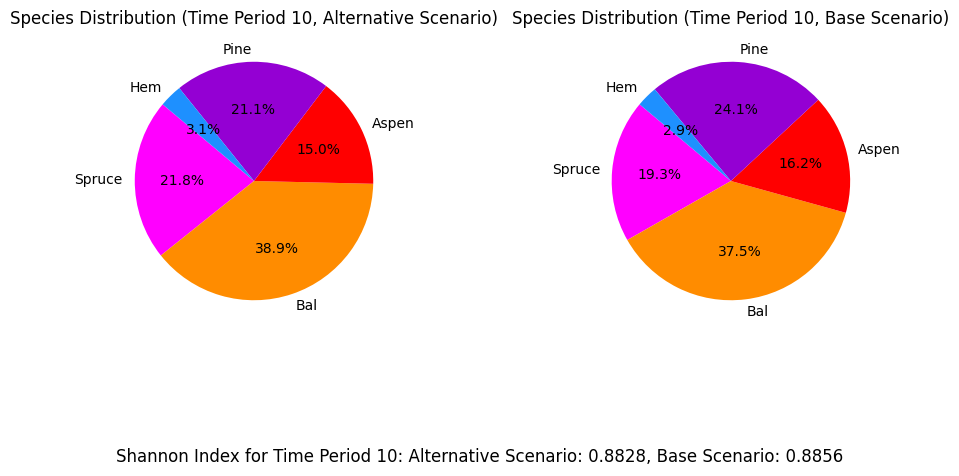

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
Running for goldenbear_max_st_gldbr_AAC_60%...
running the scenario for the Golden Bear mining site (60%_AAC),
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 3949 rows, 36130 columns and 470612 nonzeros
Model fingerprint: 0x2a0157c8
Coefficient statistics:
  Matrix range     [1e-02, 1e+05]
  Objective range  [2e+02, 1e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 7e+09]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 2038 rows and 2031 columns
Presolve time: 0.19s
Presolved: 1911 rows, 34100 

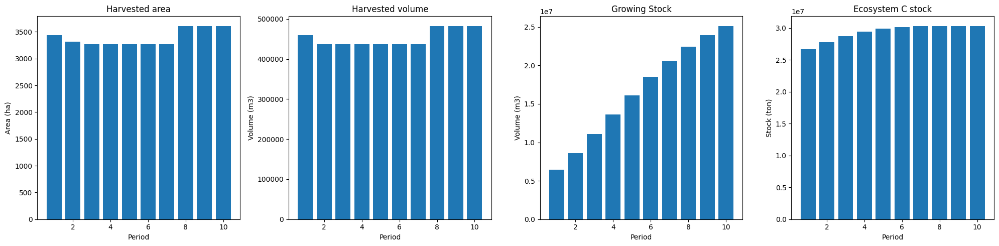

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_60%_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  4786
The economic indicator (the provincial government revenues) is:  163228
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


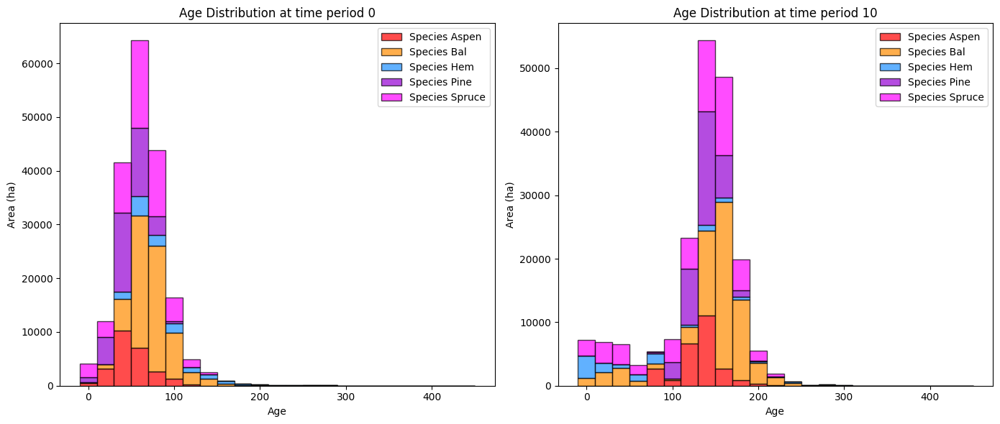

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_60%_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                 0            10    Difference
Spruce    2.708533   5115.541060   5112.832526
Bal     278.565372  12069.677653  11791.112281
Aspen   273.490478  10585.146303  10311.655825
Pine      0.000000   7412.567834   7412.567834
Hem     419.699331    790.922530    371.223199

Overall diversity has **increased** by 34999.39 hectares from time period 0 to time period 10.


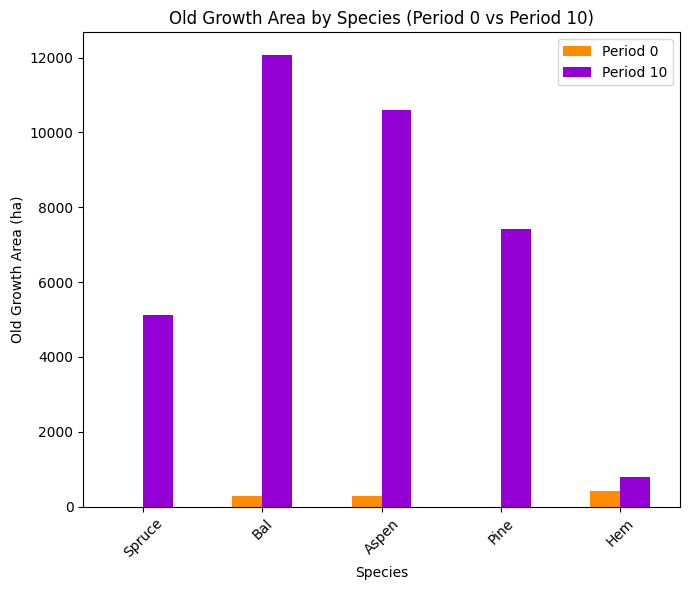

Clustered column plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_60%_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.9455
Shannon Evenness Index for time period 10: 0.8830

Diversity has **decreased** by 6.26% from time 0 to time 10.


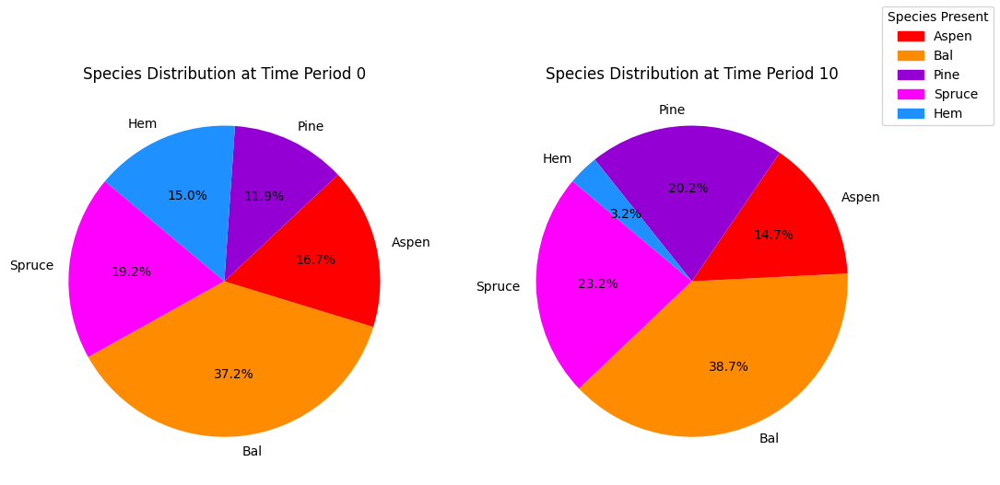

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_60%_species_pie.pdf
running business as usual scenario for the Golden Bear mine site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 3949 rows, 36130 columns and 470612 nonzeros
Model fingerprint: 0x7ea88e1f
Coefficient statistics:
  Matrix range     [1e-02, 1e+05]
  Objective range  [2e+02, 1e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 4e+07]
Presolve removed 2037 rows and 2031 columns
Presolve time: 0.15s
Presolved: 1912 rows, 34099 columns, 421112 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Ordering time: 0.00s

Barrier statistics:
 AA' NZ     : 6.876e+04
 Factor NZ  : 9.245e+04 (roughly 15 MB of memory)
 Fact

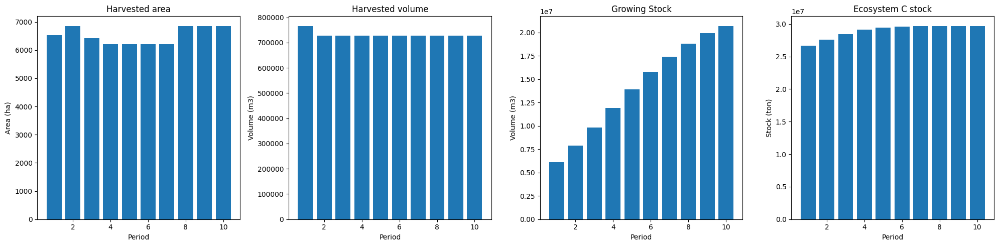

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  7734
The economic indicator (the provincial government revenues) is:  263762
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


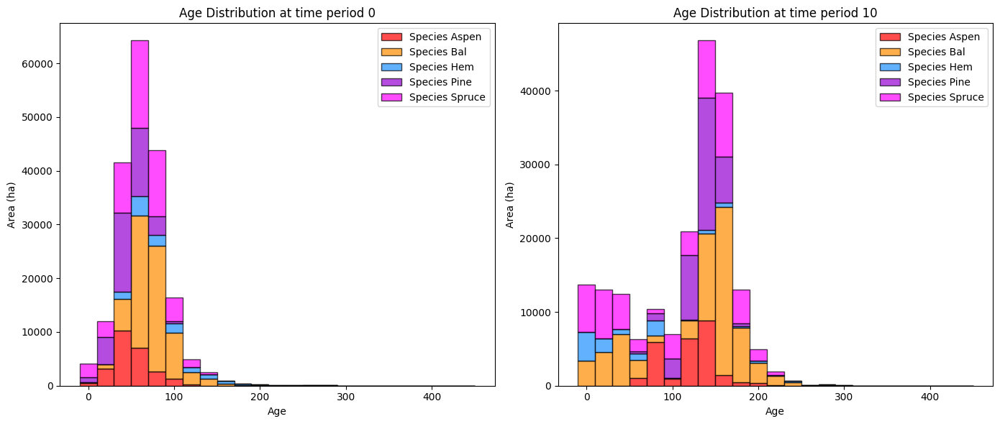

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                 0           10   Difference
Spruce    2.708533  4193.083821  4190.375287
Bal     278.565372  9045.947970  8767.382599
Aspen   273.490478  7151.110261  6877.619783
Pine      0.000000  6650.455938  6650.455938
Hem     419.699331   710.903413   291.204082

Overall diversity has **increased** by 26777.04 hectares from time period 0 to time period 10.


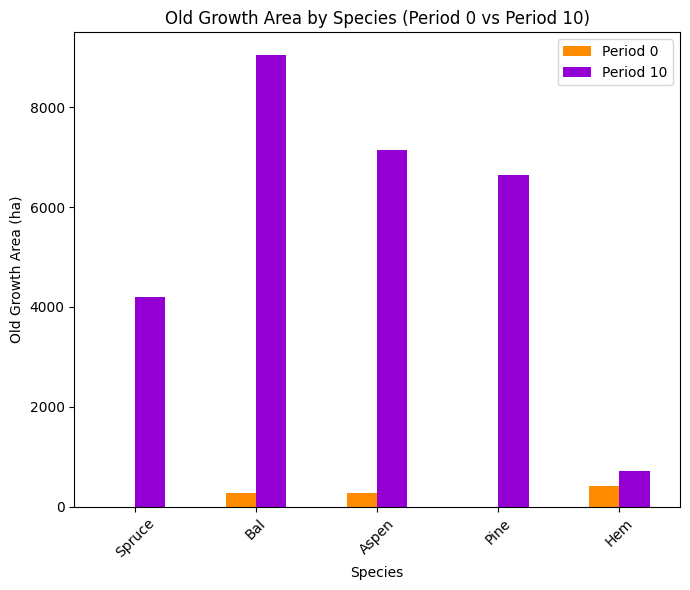

Clustered column plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.9455
Shannon Evenness Index for time period 10: 0.8856

Diversity has **decreased** by 5.99% from time 0 to time 10.


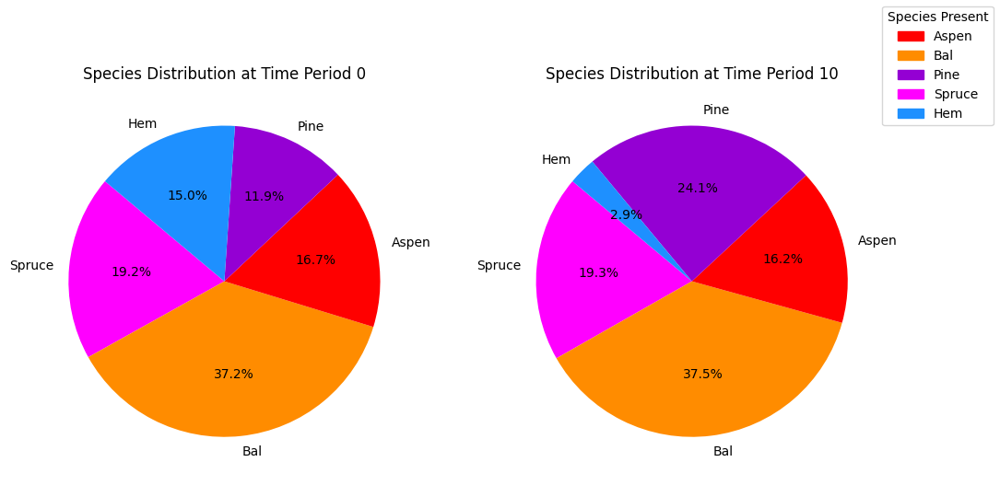

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_species_pie.pdf


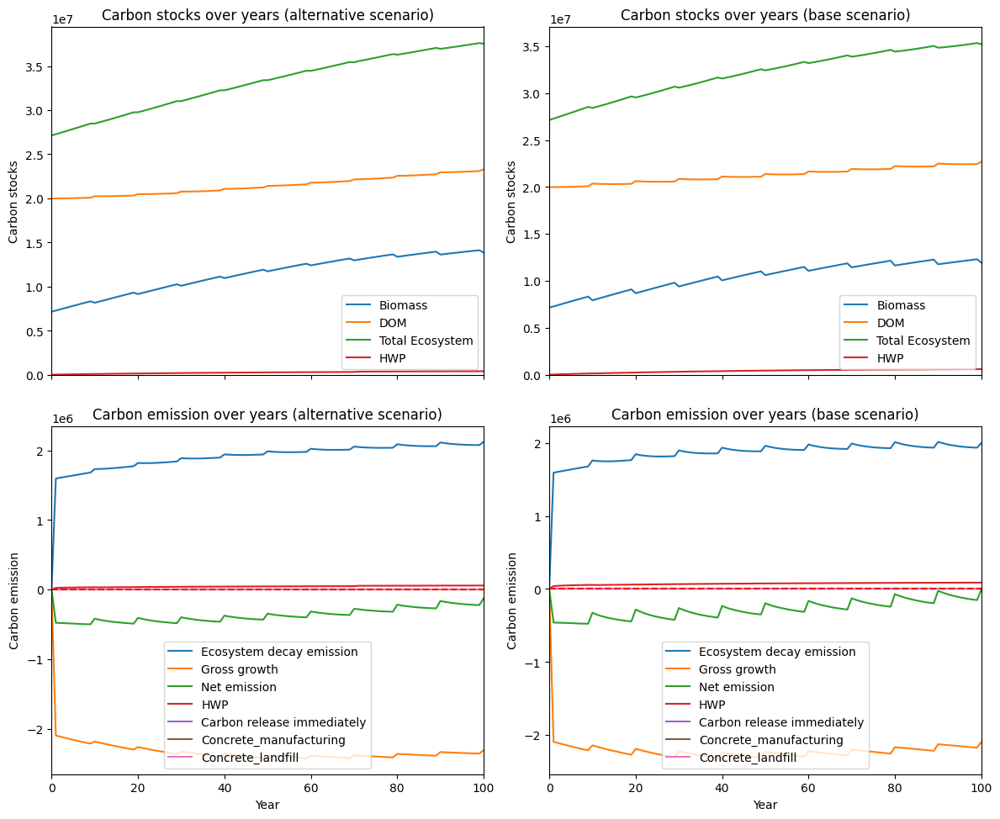

---------------------------------------------------------------------------------------
Net emission difference -1317876.1664200576
Net emission base scenario -11158576.429523937
Net emission alternative scenario -9840700.263103876
dollar_per_ton is:  7.5879663467657075
Comparison of Old Growth Areas (Alternative - Base)
          0           10   Difference
Spruce  0.0   922.457239   922.457239
Bal     0.0  3023.729682  3023.729682
Aspen   0.0  3434.036041  3434.036041
Pine    0.0   762.111896   762.111896
Hem     0.0    80.019117    80.019117

Overall, the old growth area has **increased** by 8222.35 hectares in the alternative scenario compared to the base scenario.


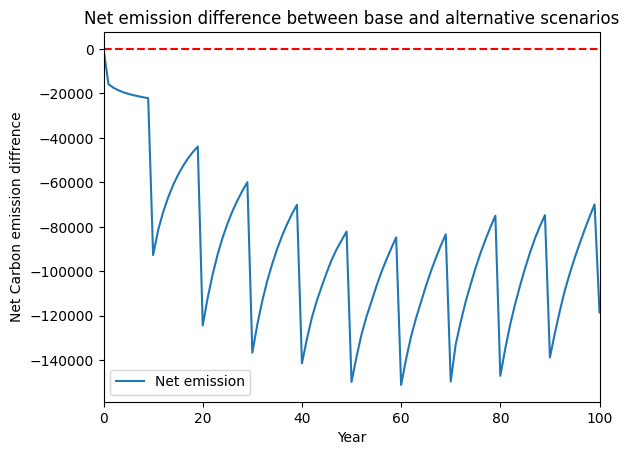

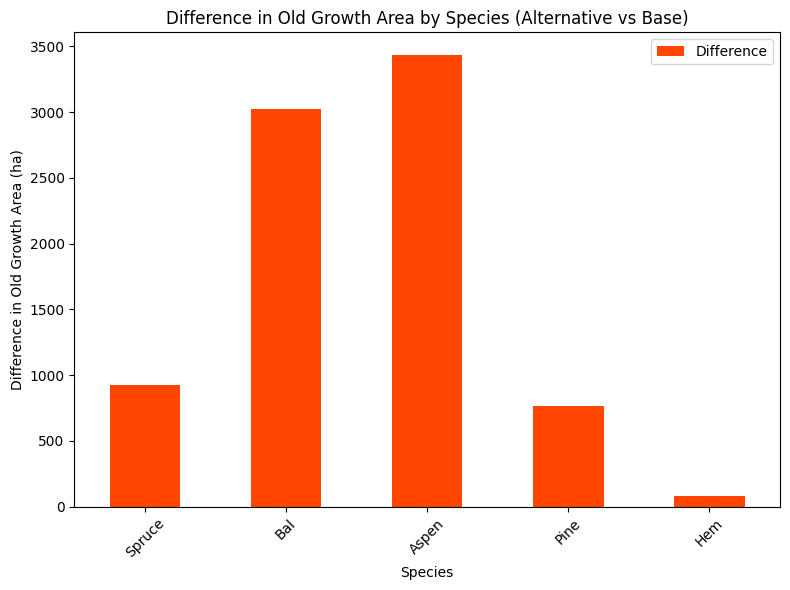

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_kpi_age_difference.pdf


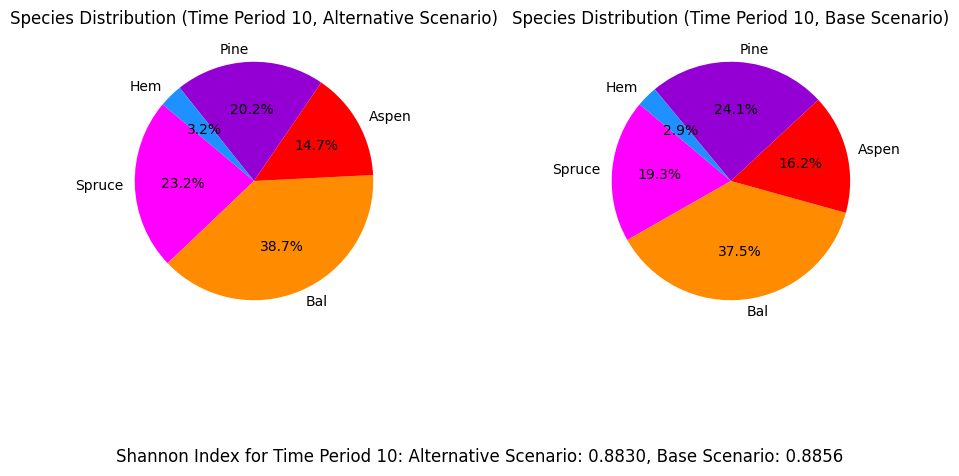

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
Running for goldenbear_max_st_gldbr_AAC_50%...
running the scenario for the Golden Bear mining site (50%_AAC),
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 3949 rows, 36130 columns and 470612 nonzeros
Model fingerprint: 0xda30585a
Coefficient statistics:
  Matrix range     [1e-02, 1e+05]
  Objective range  [2e+02, 1e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 7e+09]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 2038 rows and 2031 columns
Presolve time: 0.16s
Presolved: 1911 rows, 34100 

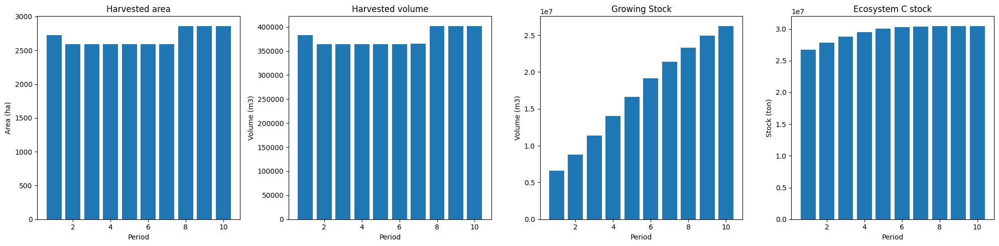

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_50%_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  3990
The economic indicator (the provincial government revenues) is:  136073
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


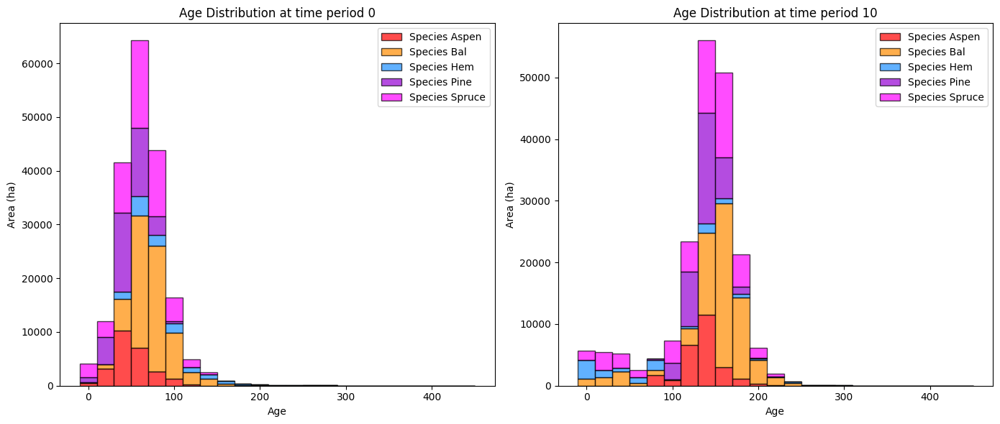

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_50%_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                 0            10    Difference
Spruce    2.708533   5513.108798   5510.400265
Bal     278.565372  12801.833364  12523.267992
Aspen   273.490478  11513.233858  11239.743380
Pine      0.000000   7496.113931   7496.113931
Hem     419.699331    830.482584    410.783253

Overall diversity has **increased** by 37180.31 hectares from time period 0 to time period 10.


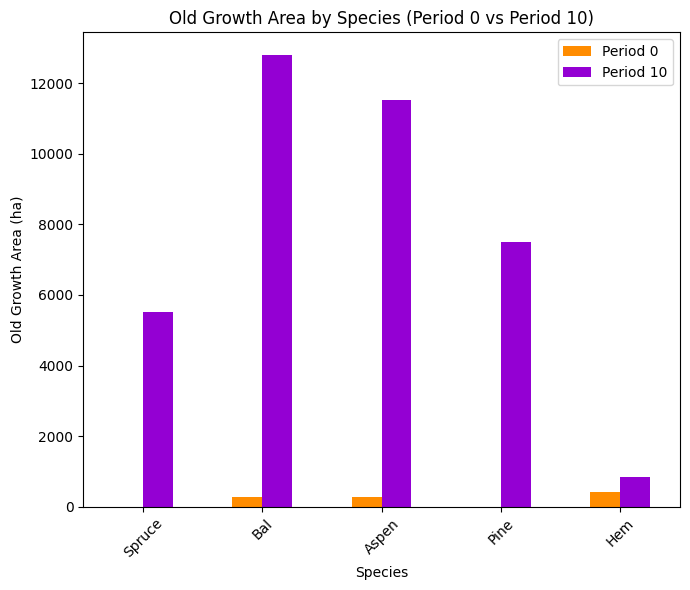

Clustered column plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_50%_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.9455
Shannon Evenness Index for time period 10: 0.8909

Diversity has **decreased** by 5.47% from time 0 to time 10.


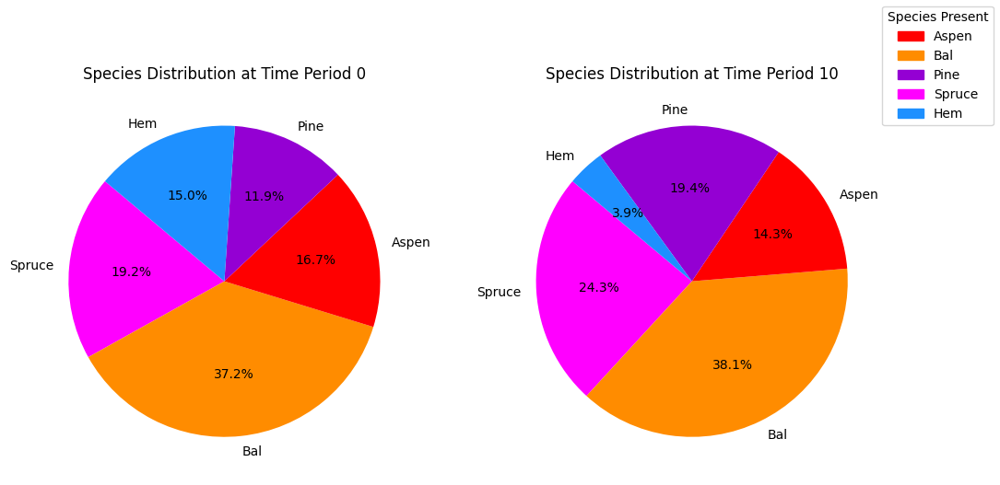

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_50%_species_pie.pdf
running business as usual scenario for the Golden Bear mine site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 3949 rows, 36130 columns and 470612 nonzeros
Model fingerprint: 0x7ea88e1f
Coefficient statistics:
  Matrix range     [1e-02, 1e+05]
  Objective range  [2e+02, 1e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 4e+07]
Presolve removed 2037 rows and 2031 columns
Presolve time: 0.15s
Presolved: 1912 rows, 34099 columns, 421112 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Ordering time: 0.00s

Barrier statistics:
 AA' NZ     : 6.876e+04
 Factor NZ  : 9.245e+04 (roughly 15 MB of memory)
 Fact

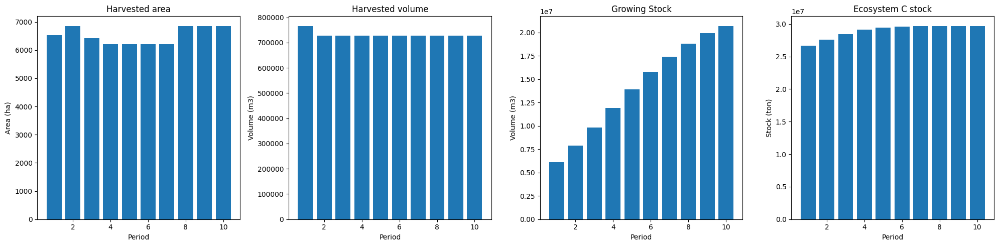

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  7734
The economic indicator (the provincial government revenues) is:  263762
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


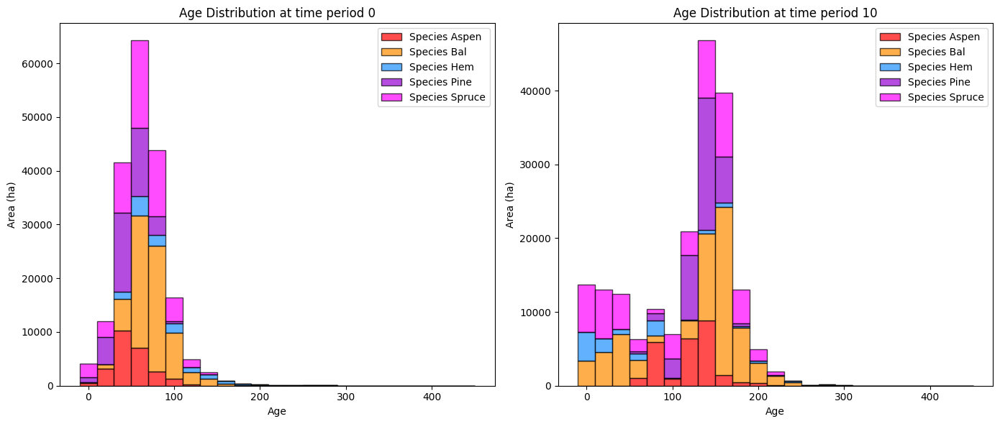

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                 0           10   Difference
Spruce    2.708533  4193.083821  4190.375287
Bal     278.565372  9045.947970  8767.382599
Aspen   273.490478  7151.110261  6877.619783
Pine      0.000000  6650.455938  6650.455938
Hem     419.699331   710.903413   291.204082

Overall diversity has **increased** by 26777.04 hectares from time period 0 to time period 10.


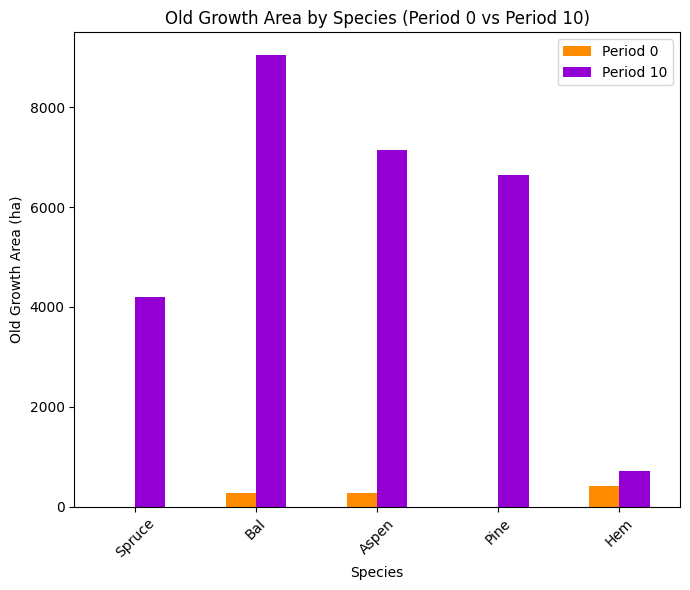

Clustered column plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.9455
Shannon Evenness Index for time period 10: 0.8856

Diversity has **decreased** by 5.99% from time 0 to time 10.


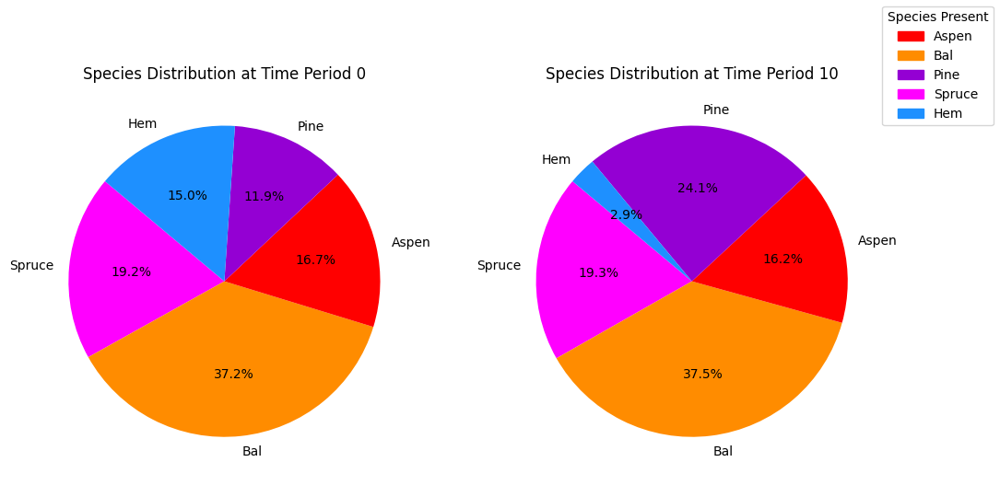

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_species_pie.pdf


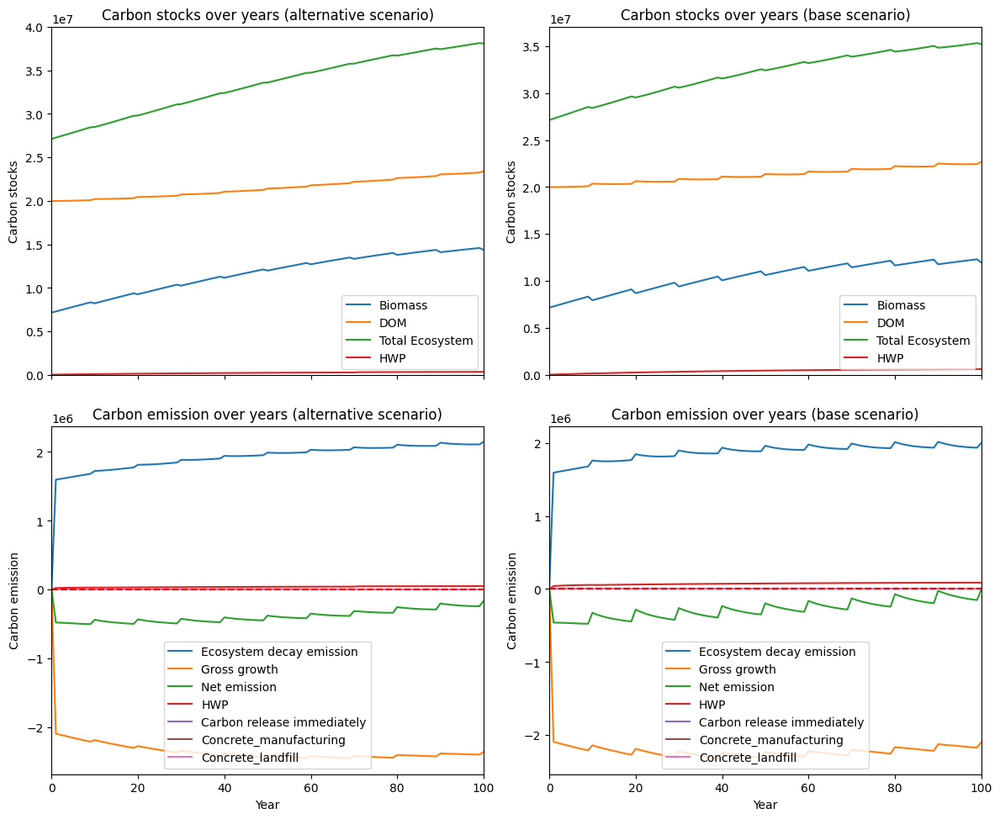

---------------------------------------------------------------------------------------
Net emission difference -1632381.8463075156
Net emission base scenario -11473082.109411394
Net emission alternative scenario -9840700.263103876
dollar_per_ton is:  6.126017648762895
Comparison of Old Growth Areas (Alternative - Base)
          0           10   Difference
Spruce  0.0  1320.024978  1320.024978
Bal     0.0  3755.885394  3755.885394
Aspen   0.0  4362.123597  4362.123597
Pine    0.0   845.657993   845.657993
Hem     0.0   119.579171   119.579171

Overall, the old growth area has **increased** by 10403.27 hectares in the alternative scenario compared to the base scenario.


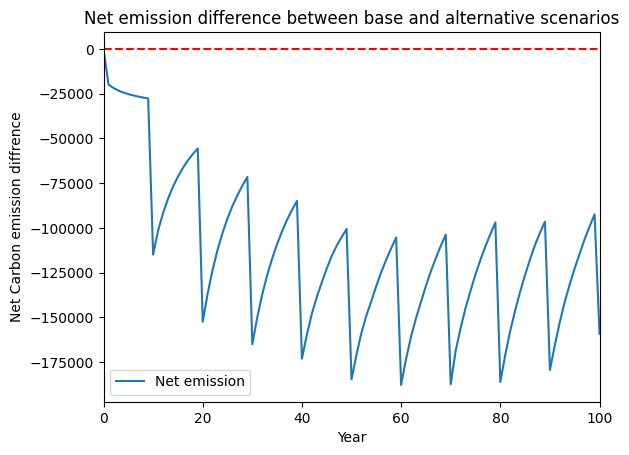

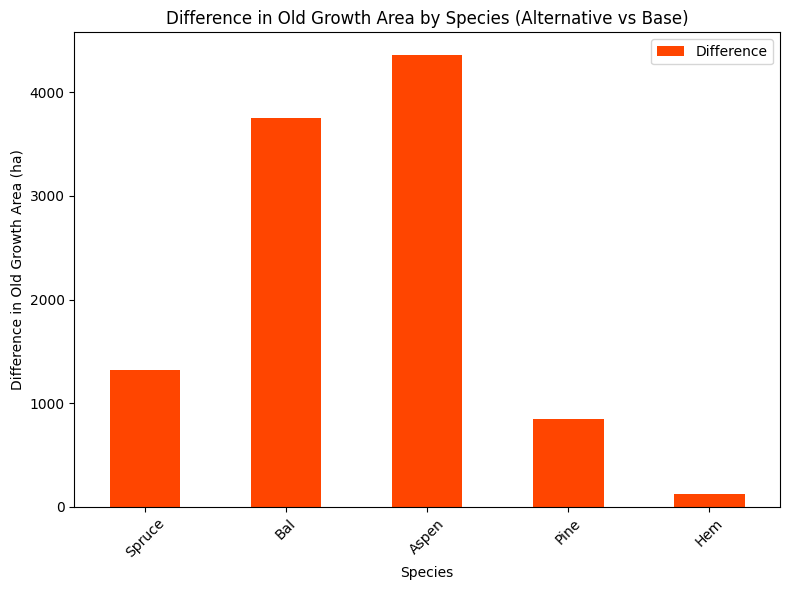

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_kpi_age_difference.pdf


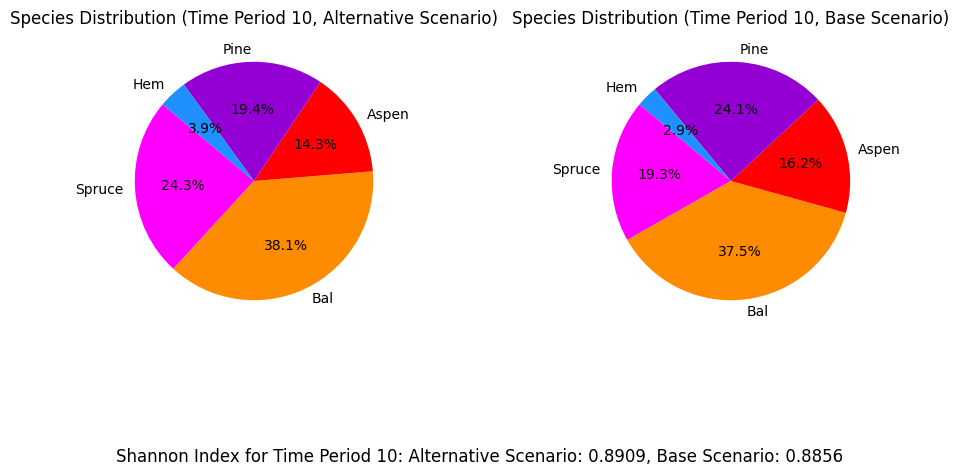

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
Running for goldenbear_max_st_gldbr_AAC_40%...
running the scenario for the Golden Bear mining site (40%_AAC),
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 3949 rows, 36130 columns and 470612 nonzeros
Model fingerprint: 0x34867c9b
Coefficient statistics:
  Matrix range     [1e-02, 1e+05]
  Objective range  [2e+02, 1e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 7e+09]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 2038 rows and 2031 columns
Presolve time: 0.17s
Presolved: 1911 rows, 34100 

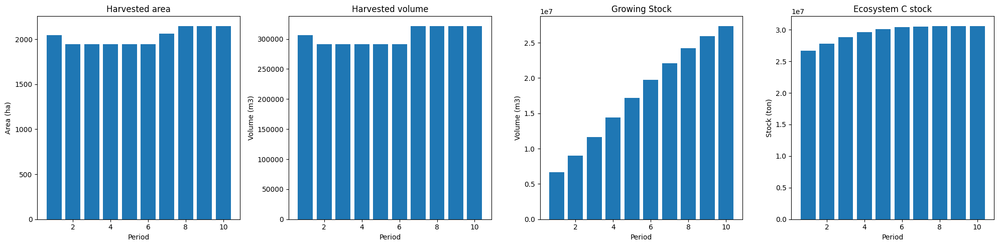

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_40%_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  3223
The economic indicator (the provincial government revenues) is:  109923
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


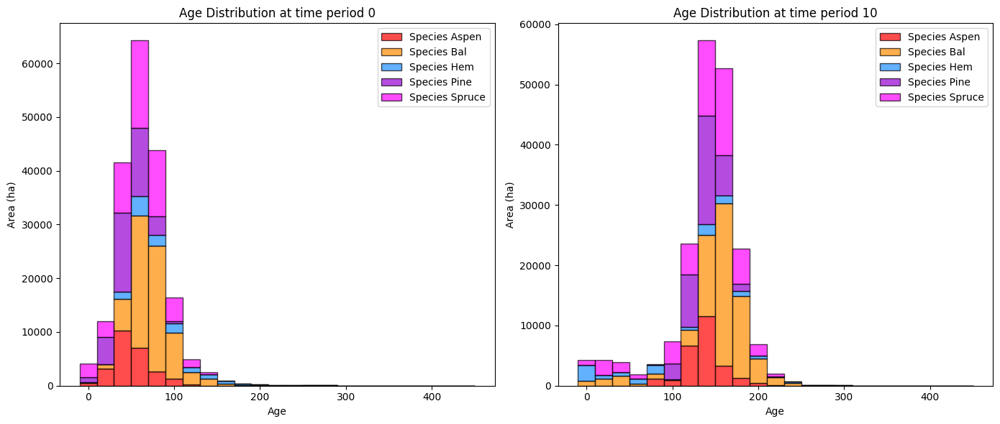

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_40%_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                 0            10    Difference
Spruce    2.708533   5972.783281   5970.074747
Bal     278.565372  13317.198662  13038.633290
Aspen   273.490478  11997.125161  11723.634683
Pine      0.000000   7600.584472   7600.584472
Hem     419.699331   1002.190802    582.491471

Overall diversity has **increased** by 38915.42 hectares from time period 0 to time period 10.


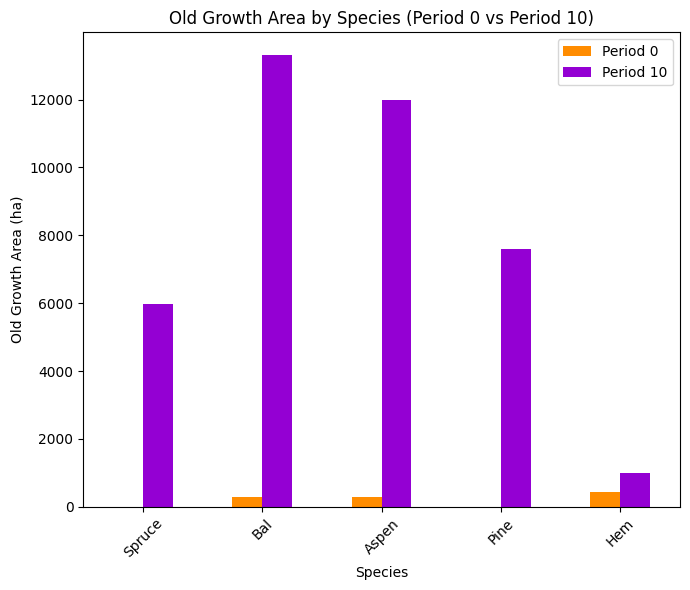

Clustered column plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_40%_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.9455
Shannon Evenness Index for time period 10: 0.9007

Diversity has **decreased** by 4.48% from time 0 to time 10.


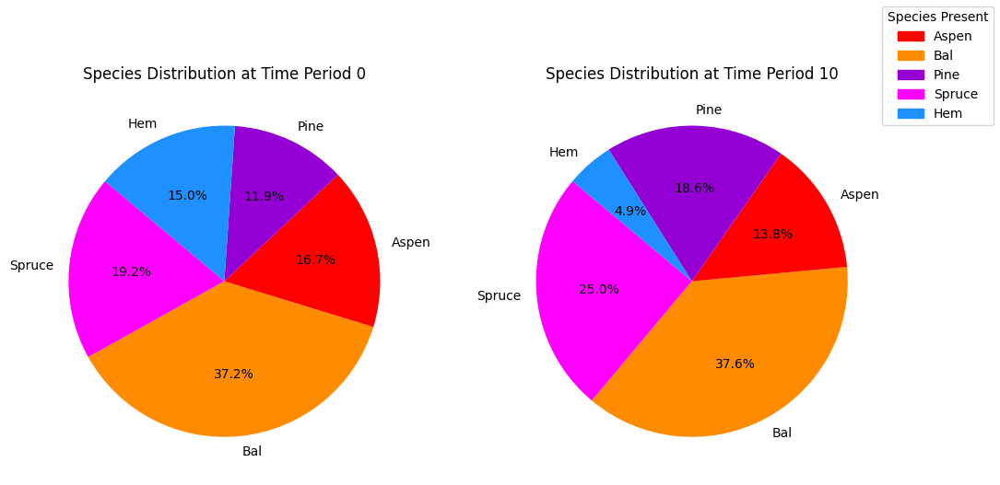

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_40%_species_pie.pdf
running business as usual scenario for the Golden Bear mine site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 3949 rows, 36130 columns and 470612 nonzeros
Model fingerprint: 0x7ea88e1f
Coefficient statistics:
  Matrix range     [1e-02, 1e+05]
  Objective range  [2e+02, 1e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 4e+07]
Presolve removed 2037 rows and 2031 columns
Presolve time: 0.17s
Presolved: 1912 rows, 34099 columns, 421112 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Ordering time: 0.00s

Barrier statistics:
 AA' NZ     : 6.876e+04
 Factor NZ  : 9.245e+04 (roughly 15 MB of memory)
 Fact

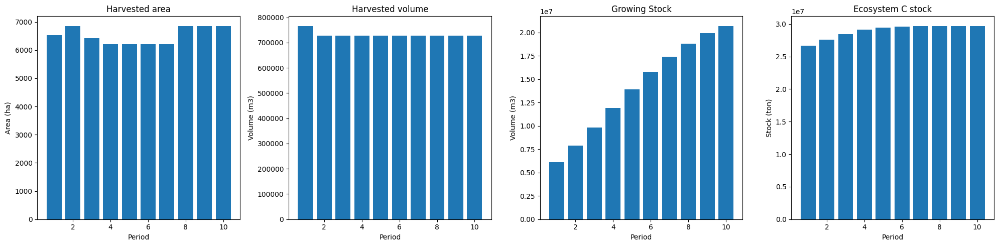

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  7734
The economic indicator (the provincial government revenues) is:  263762
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


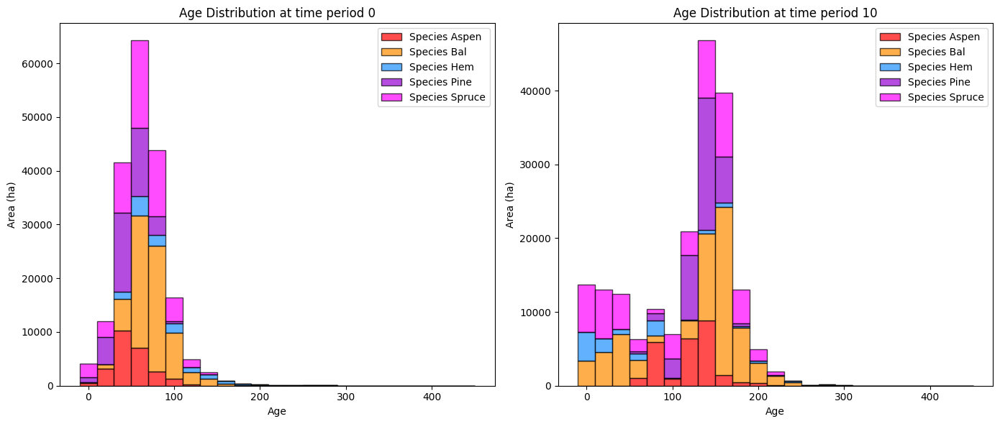

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                 0           10   Difference
Spruce    2.708533  4193.083821  4190.375287
Bal     278.565372  9045.947970  8767.382599
Aspen   273.490478  7151.110261  6877.619783
Pine      0.000000  6650.455938  6650.455938
Hem     419.699331   710.903413   291.204082

Overall diversity has **increased** by 26777.04 hectares from time period 0 to time period 10.


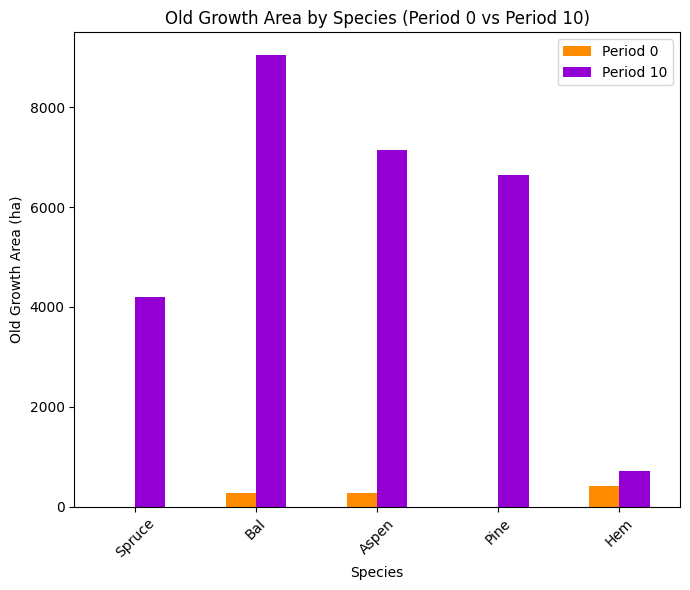

Clustered column plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.9455
Shannon Evenness Index for time period 10: 0.8856

Diversity has **decreased** by 5.99% from time 0 to time 10.


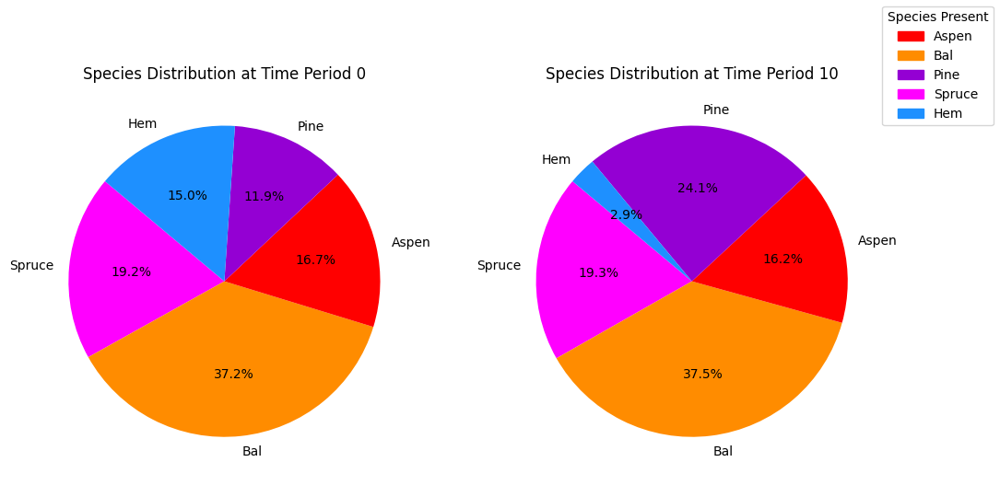

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_species_pie.pdf


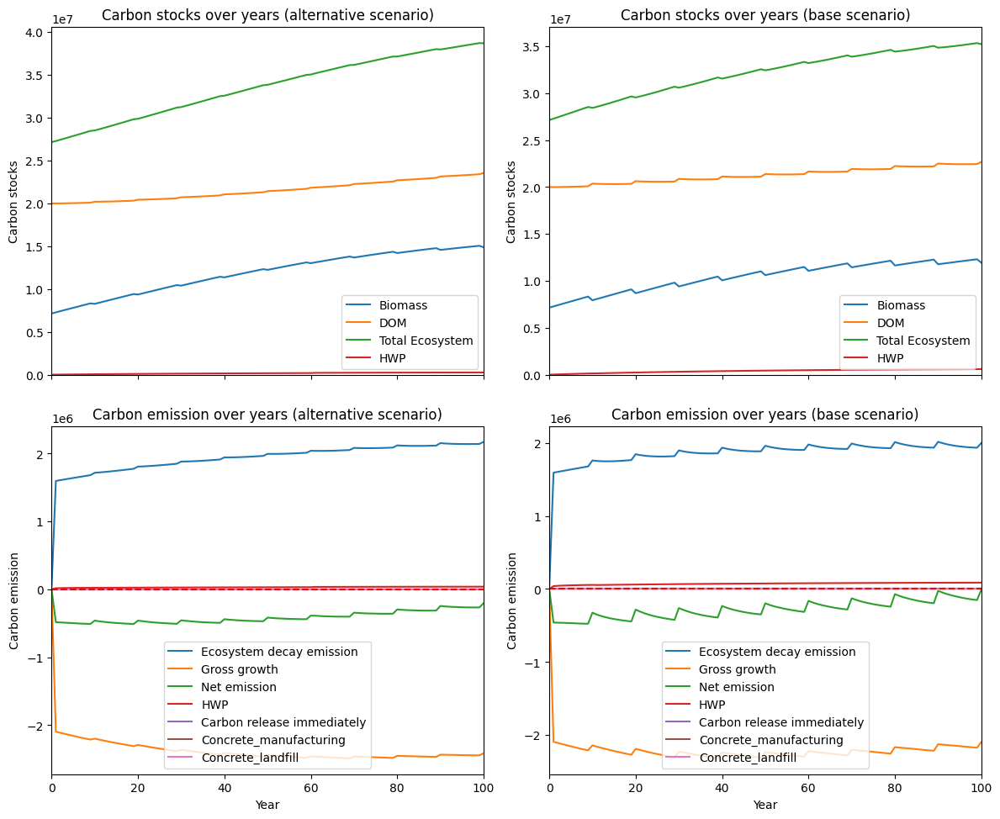

---------------------------------------------------------------------------------------
Net emission difference -1930922.9587900229
Net emission base scenario -11771623.221893903
Net emission alternative scenario -9840700.263103876
dollar_per_ton is:  5.178870526386156
Comparison of Old Growth Areas (Alternative - Base)
          0           10   Difference
Spruce  0.0  1779.699460  1779.699460
Bal     0.0  4271.250691  4271.250691
Aspen   0.0  4846.014899  4846.014899
Pine    0.0   950.128534   950.128534
Hem     0.0   291.287389   291.287389

Overall, the old growth area has **increased** by 12138.38 hectares in the alternative scenario compared to the base scenario.


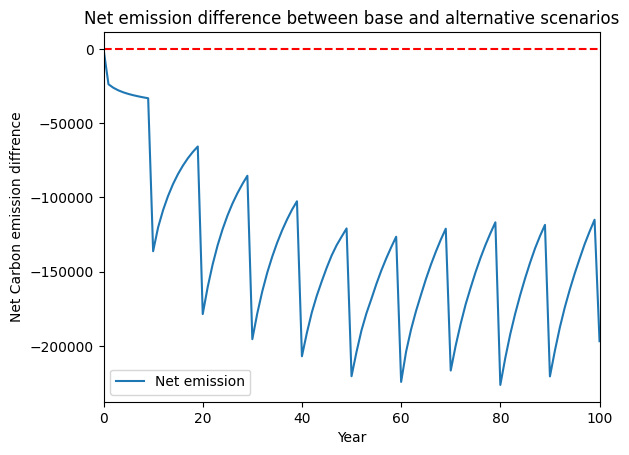

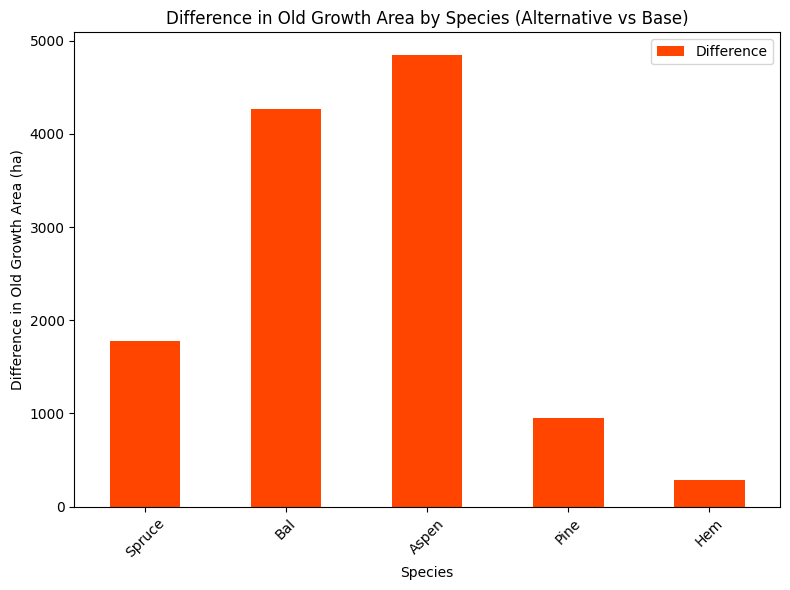

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_kpi_age_difference.pdf


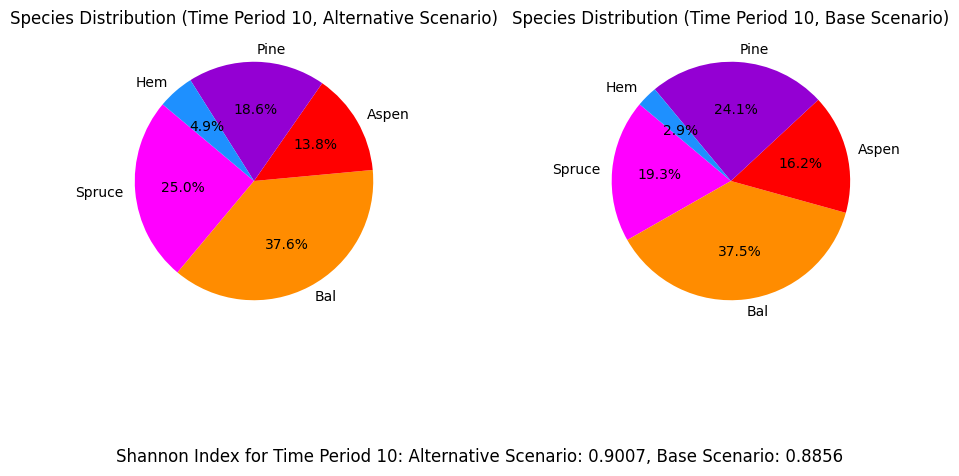

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
Running for goldenbear_max_st_gldbr_AAC_30%...
running the scenario for the Golden Bear mining site (30%_AAC),
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 3949 rows, 36130 columns and 470612 nonzeros
Model fingerprint: 0xfaf29a14
Coefficient statistics:
  Matrix range     [1e-02, 1e+05]
  Objective range  [2e+02, 1e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 7e+09]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 2038 rows and 2031 columns
Presolve time: 0.15s
Presolved: 1911 rows, 34100 

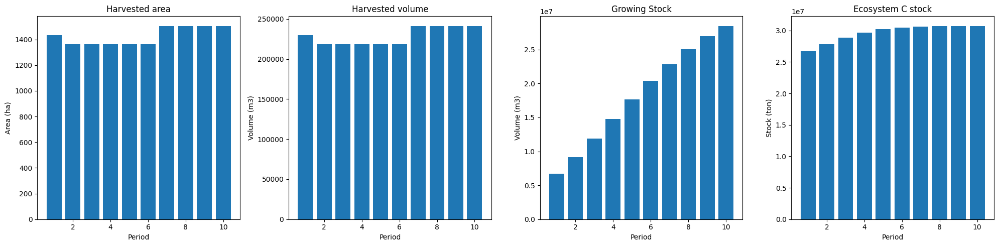

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_30%_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  2417
The economic indicator (the provincial government revenues) is:  82442
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


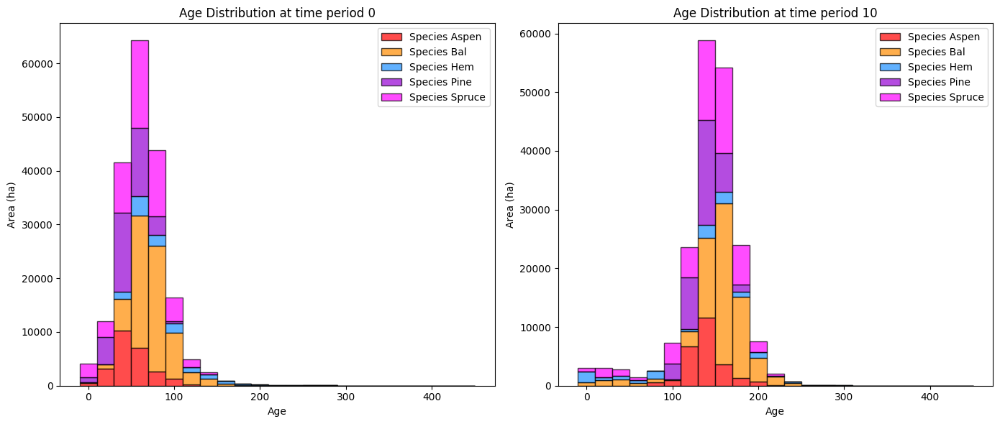

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_30%_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                 0            10    Difference
Spruce    2.708533   6387.237848   6384.529314
Bal     278.565372  13723.682465  13445.117093
Aspen   273.490478  12602.070884  12328.580406
Pine      0.000000   7631.887200   7631.887200
Hem     419.699331   1275.211146    855.511815

Overall diversity has **increased** by 40645.63 hectares from time period 0 to time period 10.


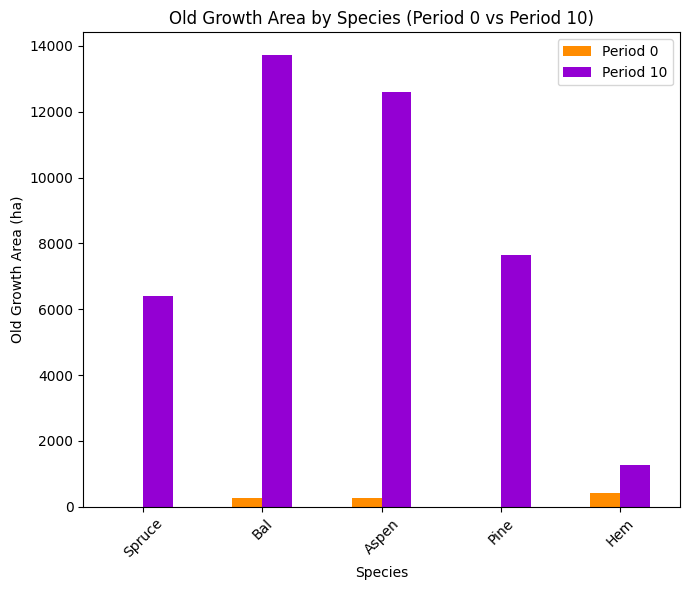

Clustered column plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_30%_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.9455
Shannon Evenness Index for time period 10: 0.9101

Diversity has **decreased** by 3.54% from time 0 to time 10.


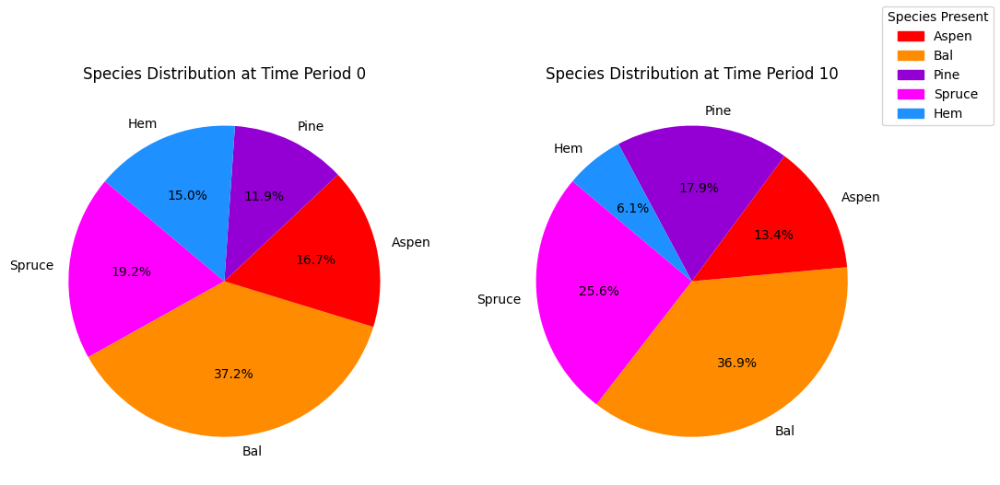

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_30%_species_pie.pdf
running business as usual scenario for the Golden Bear mine site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 3949 rows, 36130 columns and 470612 nonzeros
Model fingerprint: 0x7ea88e1f
Coefficient statistics:
  Matrix range     [1e-02, 1e+05]
  Objective range  [2e+02, 1e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 4e+07]
Presolve removed 2037 rows and 2031 columns
Presolve time: 0.13s
Presolved: 1912 rows, 34099 columns, 421112 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Ordering time: 0.00s

Barrier statistics:
 AA' NZ     : 6.876e+04
 Factor NZ  : 9.245e+04 (roughly 15 MB of memory)
 Fact

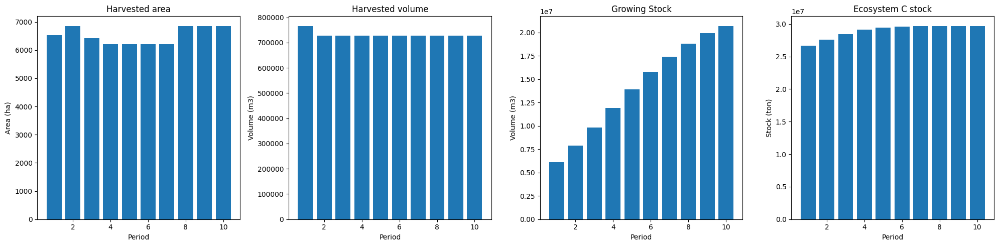

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  7734
The economic indicator (the provincial government revenues) is:  263762
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


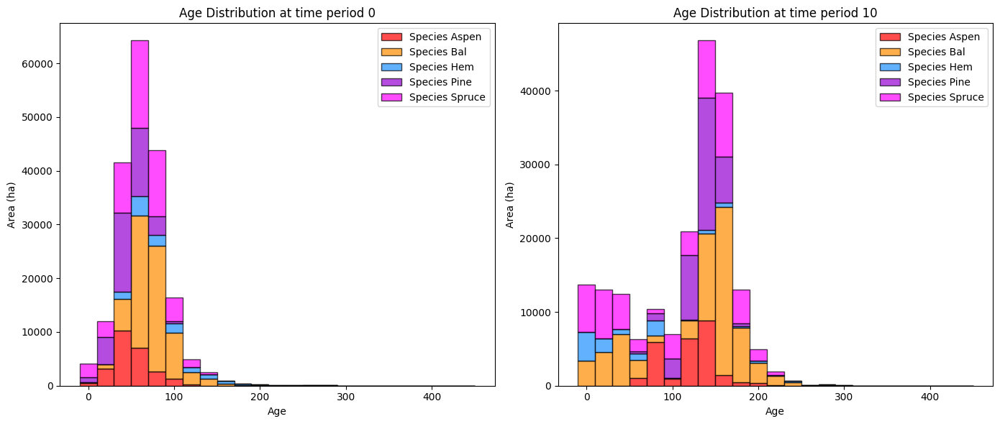

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                 0           10   Difference
Spruce    2.708533  4193.083821  4190.375287
Bal     278.565372  9045.947970  8767.382599
Aspen   273.490478  7151.110261  6877.619783
Pine      0.000000  6650.455938  6650.455938
Hem     419.699331   710.903413   291.204082

Overall diversity has **increased** by 26777.04 hectares from time period 0 to time period 10.


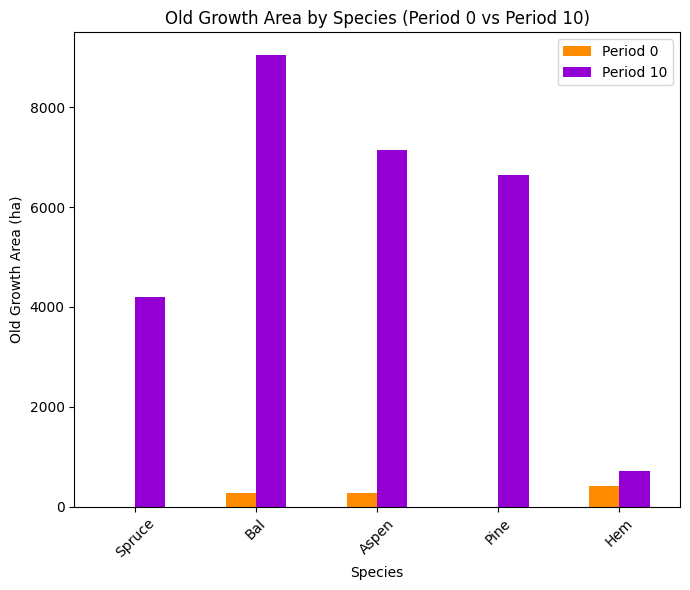

Clustered column plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.9455
Shannon Evenness Index for time period 10: 0.8856

Diversity has **decreased** by 5.99% from time 0 to time 10.


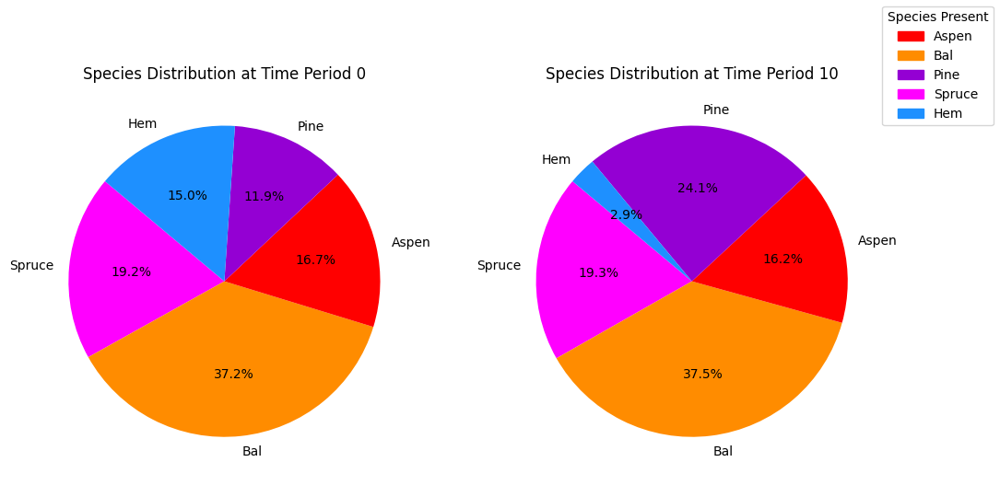

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_species_pie.pdf


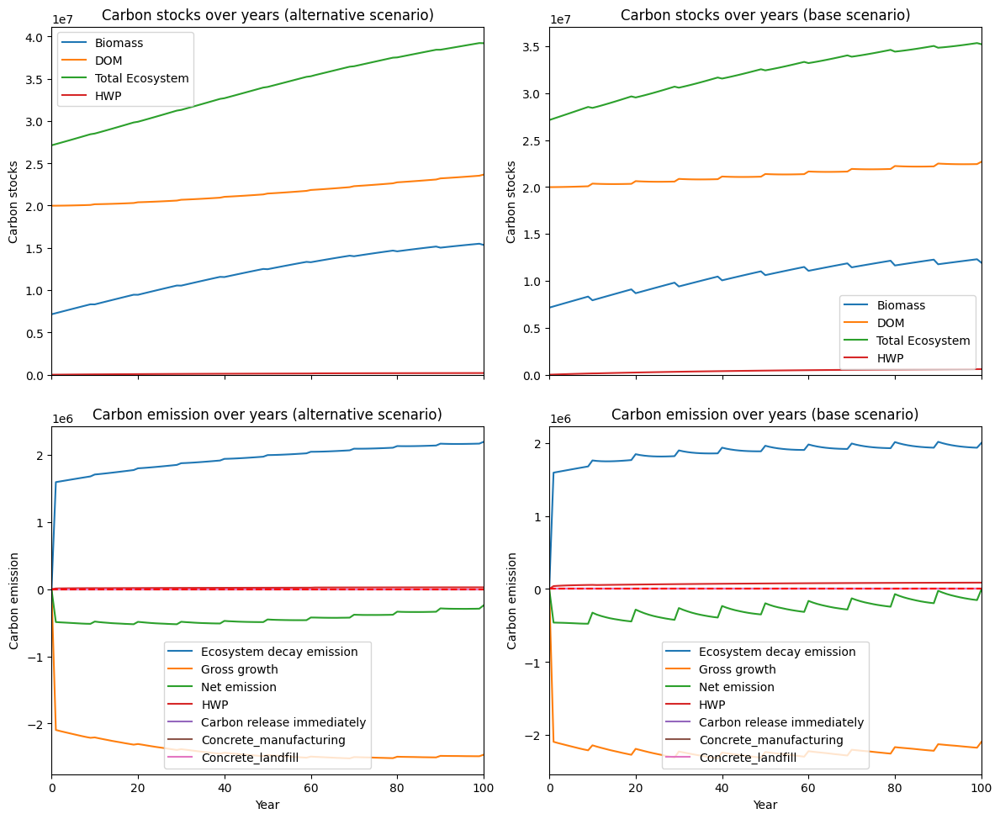

---------------------------------------------------------------------------------------
Net emission difference -2213401.7999341073
Net emission base scenario -12054102.063037988
Net emission alternative scenario -9840700.263103876
dollar_per_ton is:  4.517932532763685
Comparison of Old Growth Areas (Alternative - Base)
          0           10   Difference
Spruce  0.0  2194.154027  2194.154027
Bal     0.0  4677.734494  4677.734494
Aspen   0.0  5450.960623  5450.960623
Pine    0.0   981.431263   981.431263
Hem     0.0   564.307732   564.307732

Overall, the old growth area has **increased** by 13868.59 hectares in the alternative scenario compared to the base scenario.


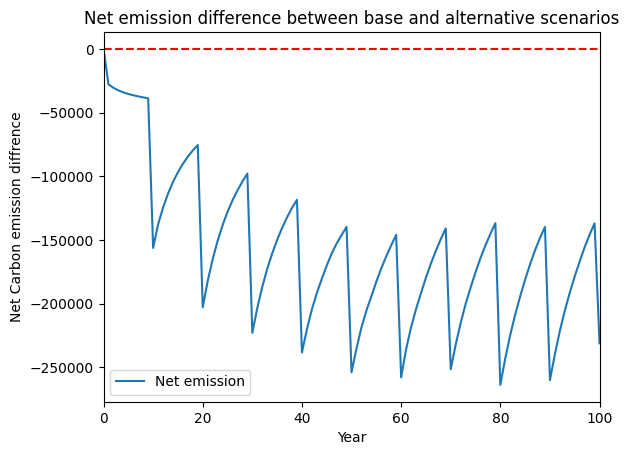

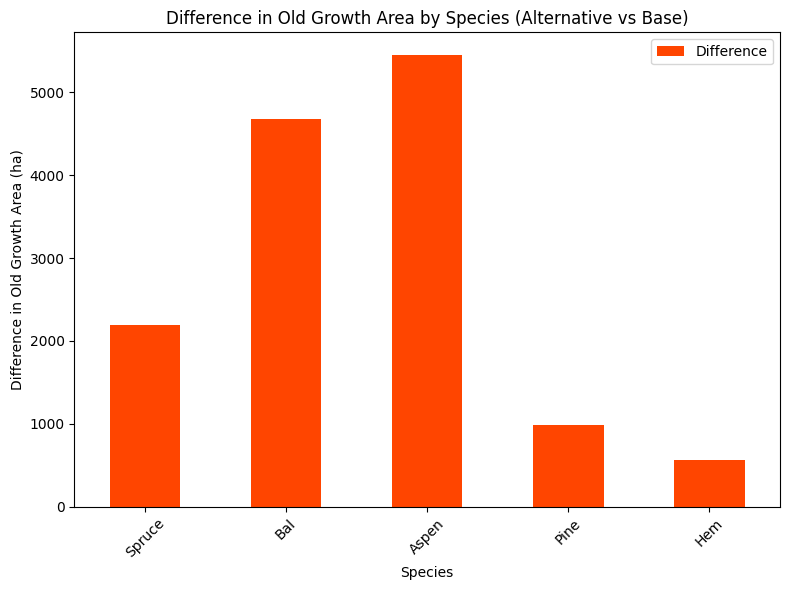

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_kpi_age_difference.pdf


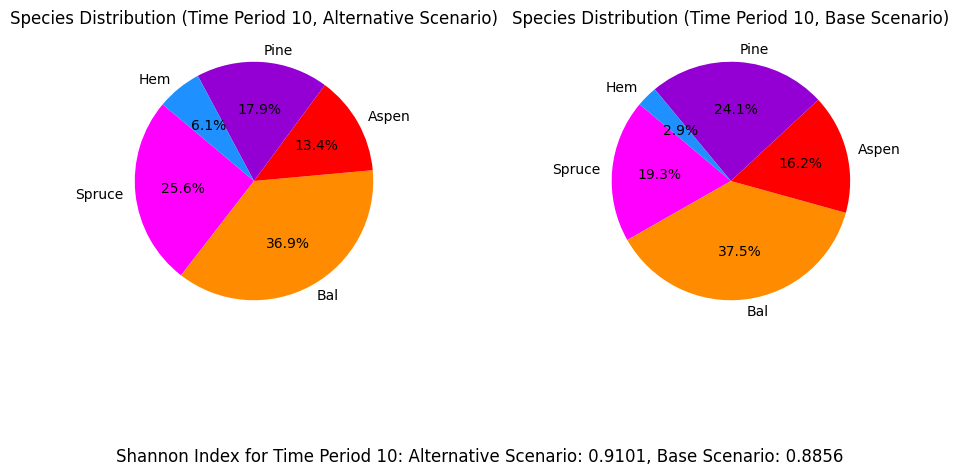

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
Running for goldenbear_max_st_gldbr_AAC_20%...
running the scenario for the Golden Bear mining site (20%_AAC),
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 3949 rows, 36130 columns and 470612 nonzeros
Model fingerprint: 0x1d9b7b3a
Coefficient statistics:
  Matrix range     [1e-02, 1e+05]
  Objective range  [2e+02, 1e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 7e+09]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 2038 rows and 2031 columns
Presolve time: 0.13s
Presolved: 1911 rows, 34100 

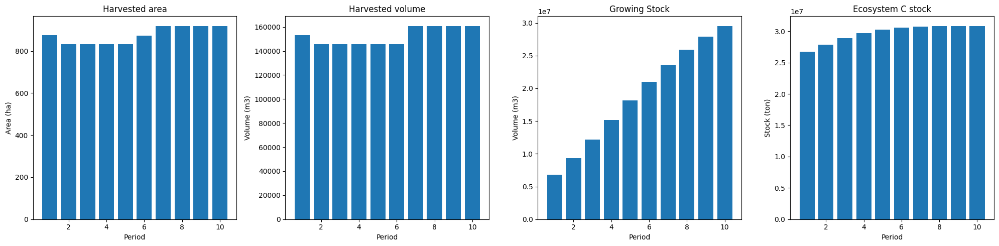

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_20%_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  1611
The economic indicator (the provincial government revenues) is:  54961
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


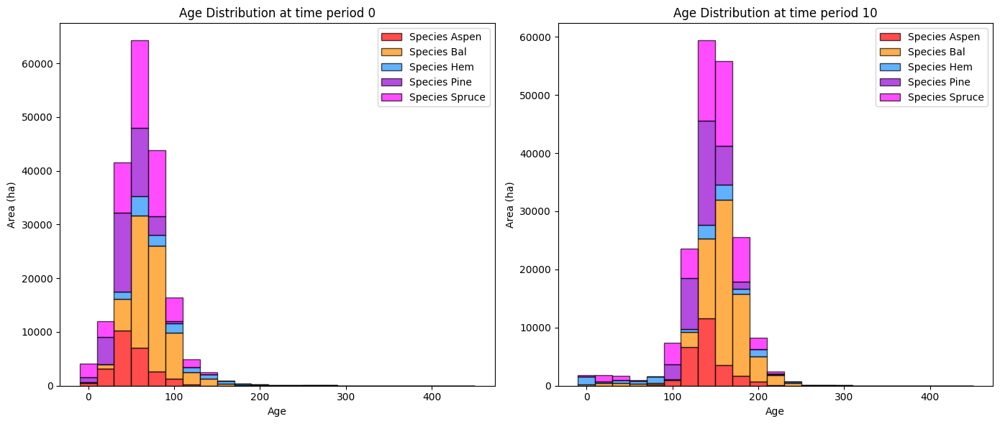

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_20%_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                 0            10    Difference
Spruce    2.708533   6903.317592   6900.609058
Bal     278.565372  14657.490394  14378.925023
Aspen   273.490478  13027.839047  12754.348569
Pine      0.000000   7631.887200   7631.887200
Hem     419.699331   1548.794344   1129.095013

Overall diversity has **increased** by 42794.86 hectares from time period 0 to time period 10.


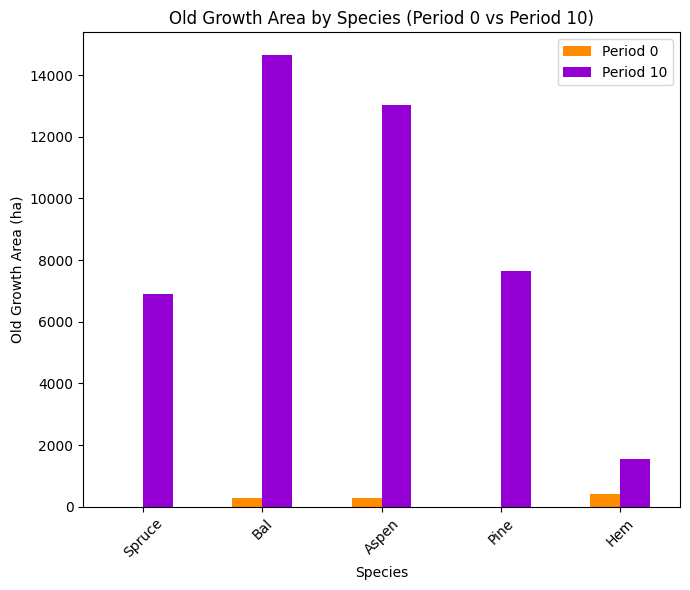

Clustered column plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_20%_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.9455
Shannon Evenness Index for time period 10: 0.9137

Diversity has **decreased** by 3.18% from time 0 to time 10.


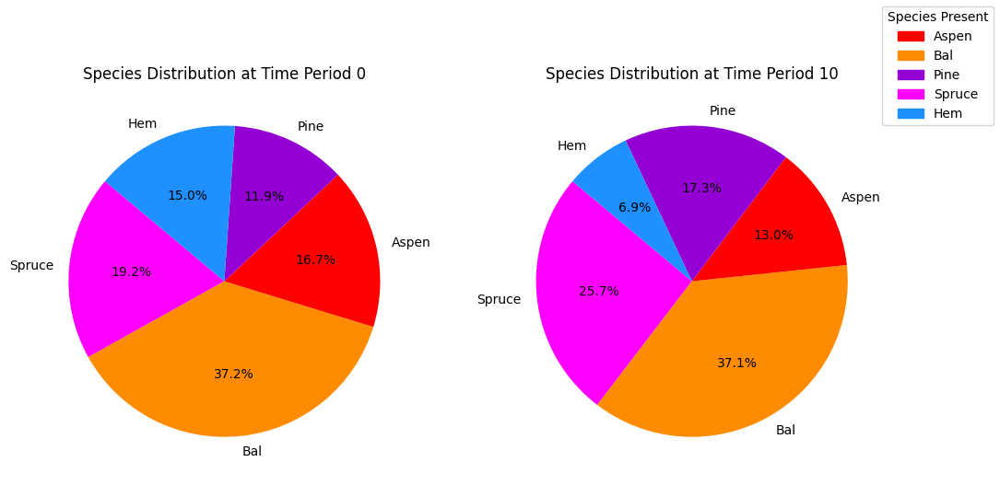

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_20%_species_pie.pdf
running business as usual scenario for the Golden Bear mine site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 3949 rows, 36130 columns and 470612 nonzeros
Model fingerprint: 0x7ea88e1f
Coefficient statistics:
  Matrix range     [1e-02, 1e+05]
  Objective range  [2e+02, 1e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 4e+07]
Presolve removed 2037 rows and 2031 columns
Presolve time: 0.13s
Presolved: 1912 rows, 34099 columns, 421112 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Ordering time: 0.00s

Barrier statistics:
 AA' NZ     : 6.876e+04
 Factor NZ  : 9.245e+04 (roughly 15 MB of memory)
 Fact

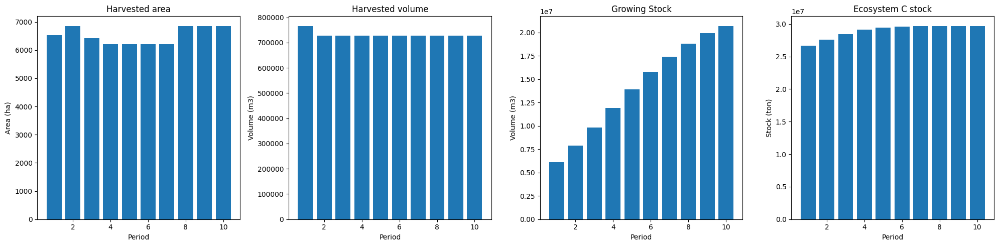

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  7734
The economic indicator (the provincial government revenues) is:  263762
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


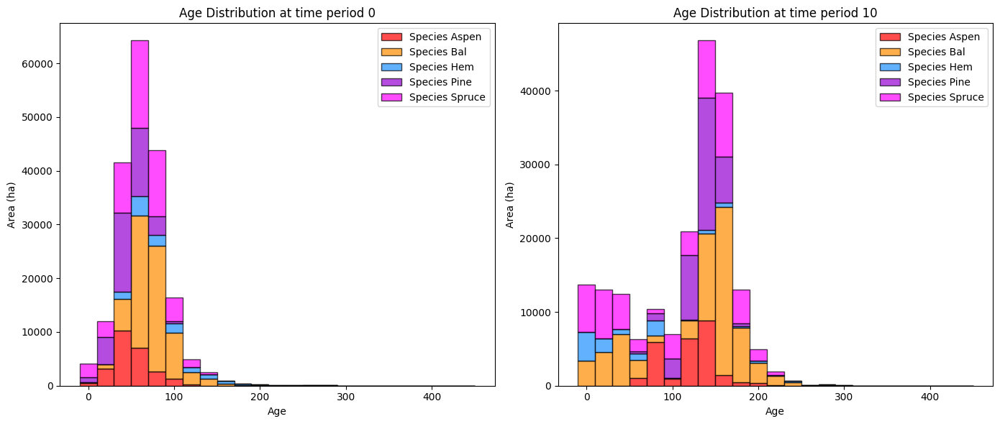

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                 0           10   Difference
Spruce    2.708533  4193.083821  4190.375287
Bal     278.565372  9045.947970  8767.382599
Aspen   273.490478  7151.110261  6877.619783
Pine      0.000000  6650.455938  6650.455938
Hem     419.699331   710.903413   291.204082

Overall diversity has **increased** by 26777.04 hectares from time period 0 to time period 10.


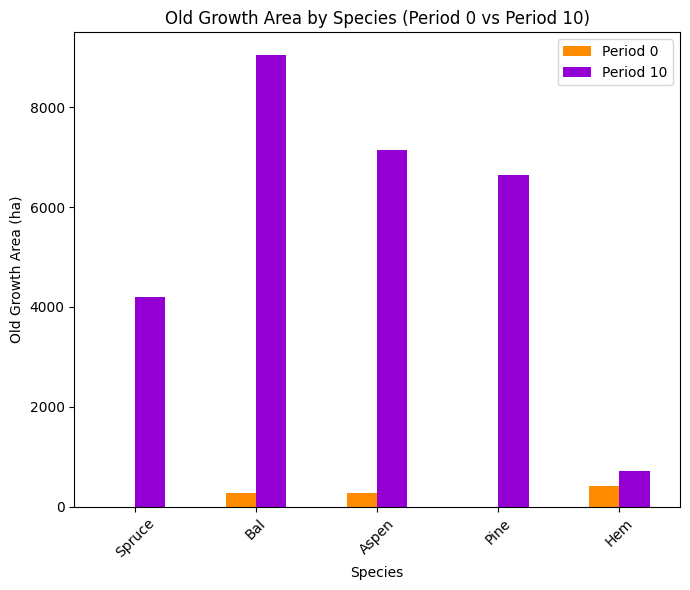

Clustered column plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.9455
Shannon Evenness Index for time period 10: 0.8856

Diversity has **decreased** by 5.99% from time 0 to time 10.


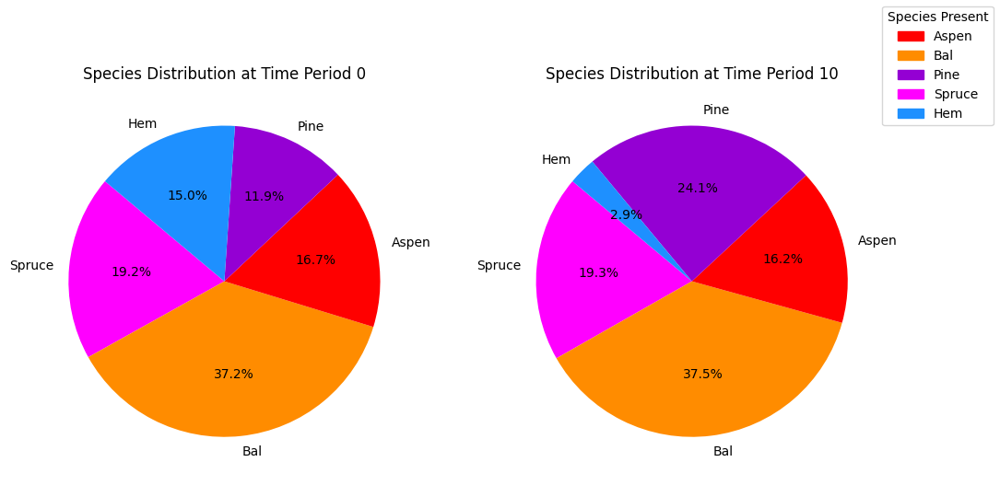

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_species_pie.pdf


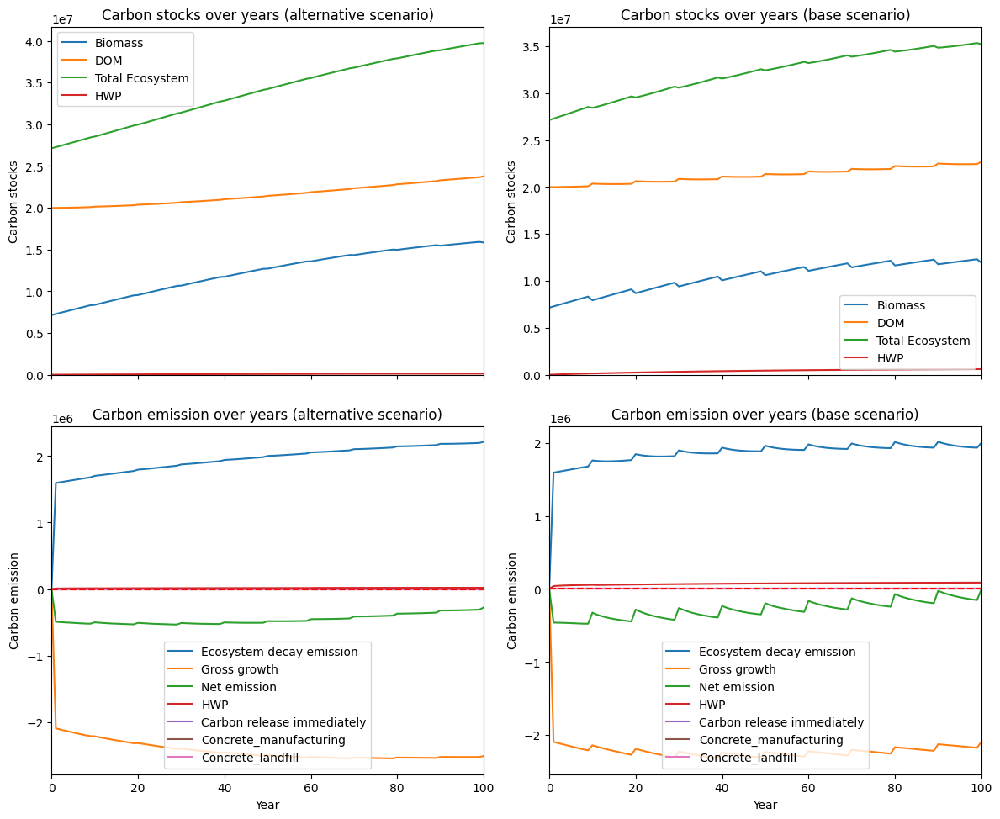

---------------------------------------------------------------------------------------
Net emission difference -2490238.4143907065
Net emission base scenario -12330938.677494586
Net emission alternative scenario -9840700.263103876
dollar_per_ton is:  4.015679760705454
Comparison of Old Growth Areas (Alternative - Base)
          0           10   Difference
Spruce  0.0  2710.233771  2710.233771
Bal     0.0  5611.542424  5611.542424
Aspen   0.0  5876.728786  5876.728786
Pine    0.0   981.431263   981.431263
Hem     0.0   837.890930   837.890930

Overall, the old growth area has **increased** by 16017.83 hectares in the alternative scenario compared to the base scenario.


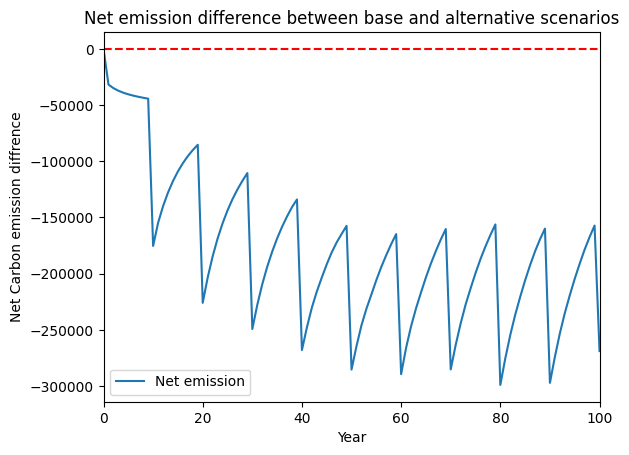

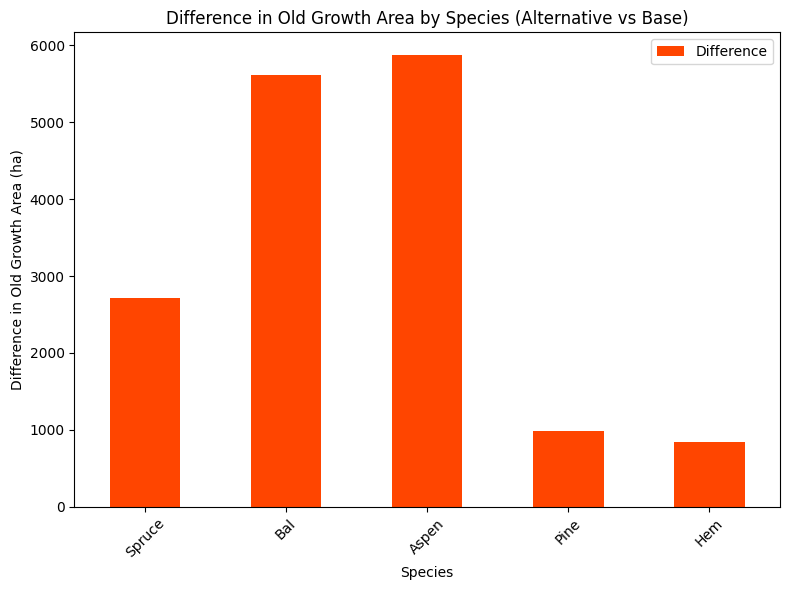

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_kpi_age_difference.pdf


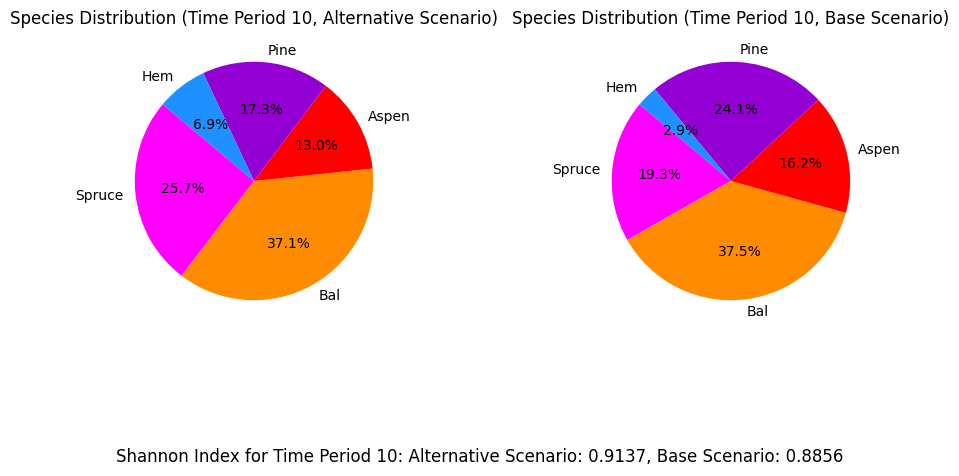

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
Running for goldenbear_max_st_gldbr_AAC_10%...
running the scenario for the Golden Bear mining site (10%_AAC),
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 3949 rows, 36130 columns and 470612 nonzeros
Model fingerprint: 0x9b592f29
Coefficient statistics:
  Matrix range     [1e-02, 1e+05]
  Objective range  [2e+02, 1e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 7e+09]
         Consider reformulating model or setting NumericFocus parameter
         to avoid numerical issues.
Presolve removed 2038 rows and 2031 columns
Presolve time: 0.16s
Presolved: 1911 rows, 34100 

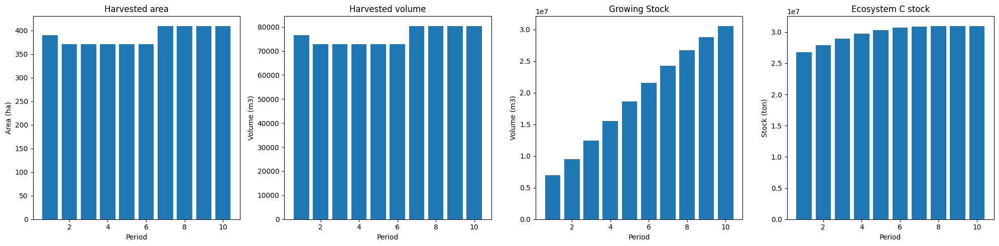

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_10%_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  805
The economic indicator (the provincial government revenues) is:  27480
------------------------------------------------
Saved cbm_output_1 and cbm_output_2 as pickle files.


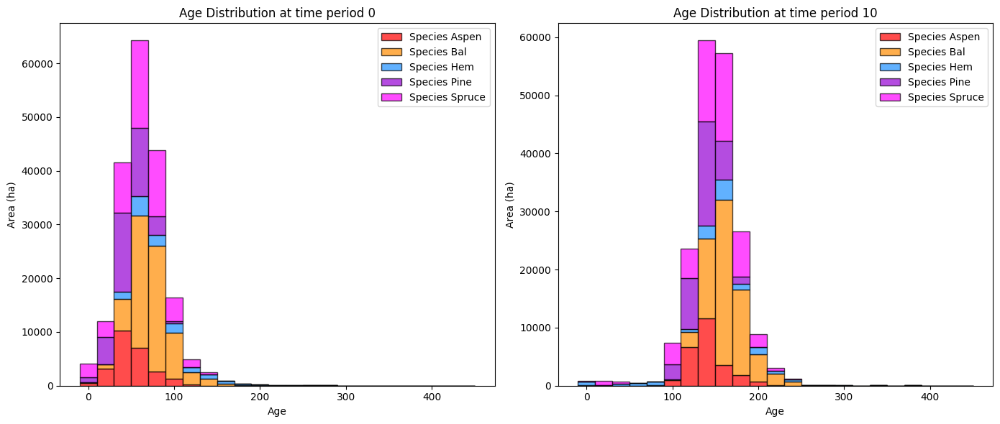

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_10%_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                 0            10    Difference
Spruce    2.708533   7327.189161   7324.480628
Bal     278.565372  15769.417536  15490.852164
Aspen   273.490478  13191.618272  12918.127794
Pine      0.000000   7631.887200   7631.887200
Hem     419.699331   2234.881146   1815.181815

Overall diversity has **increased** by 45180.53 hectares from time period 0 to time period 10.


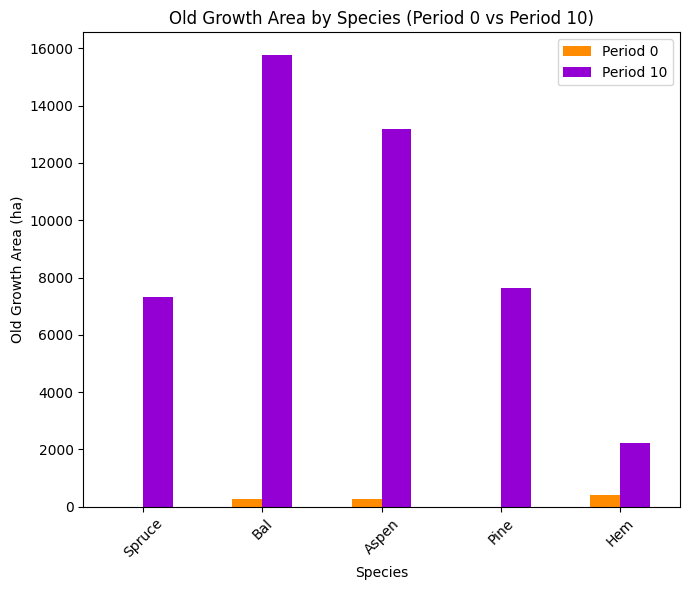

Clustered column plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_10%_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.9455
Shannon Evenness Index for time period 10: 0.9193

Diversity has **decreased** by 2.63% from time 0 to time 10.


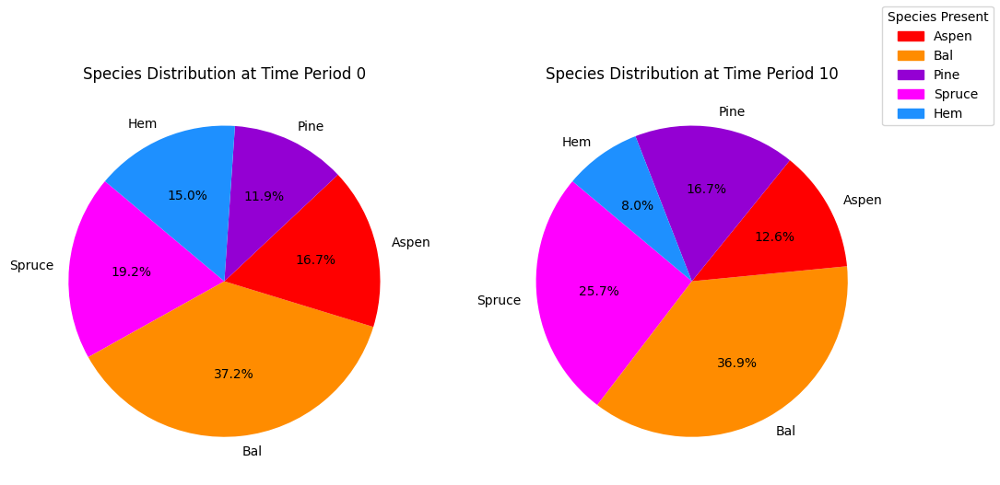

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_gldbr_AAC_10%_species_pie.pdf
running business as usual scenario for the Golden Bear mine site
Gurobi Optimizer version 10.0.3 build v10.0.3rc0 (linux64)

CPU model: Intel Core Processor (Broadwell, IBRS), instruction set [SSE2|AVX|AVX2]
Thread count: 16 physical cores, 16 logical processors, using up to 16 threads

Optimize a model with 3949 rows, 36130 columns and 470612 nonzeros
Model fingerprint: 0x7ea88e1f
Coefficient statistics:
  Matrix range     [1e-02, 1e+05]
  Objective range  [2e+02, 1e+06]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+00, 4e+07]
Presolve removed 2037 rows and 2031 columns
Presolve time: 0.15s
Presolved: 1912 rows, 34099 columns, 421112 nonzeros

Concurrent LP optimizer: primal simplex, dual simplex, and barrier
Showing barrier log only...

Ordering time: 0.00s

Barrier statistics:
 AA' NZ     : 6.876e+04
 Factor NZ  : 9.245e+04 (roughly 15 MB of memory)
 Fact

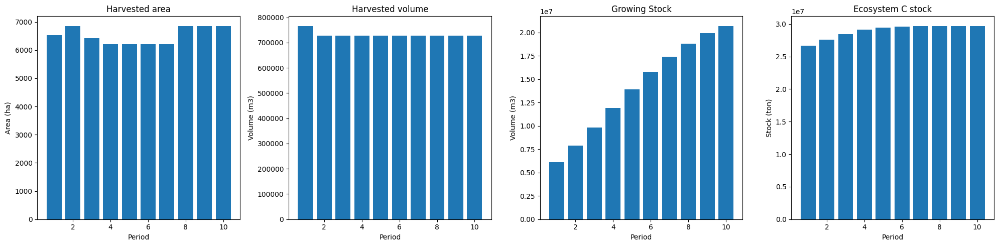

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_scheduling_maxstock.pdf
------------------------------------------------
The scocial indicator (the number of job creation) is:  7734
The economic indicator (the provincial government revenues) is:  263762
------------------------------------------------
Saved cbm_output_3 and cbm_output_4 as pickle files.


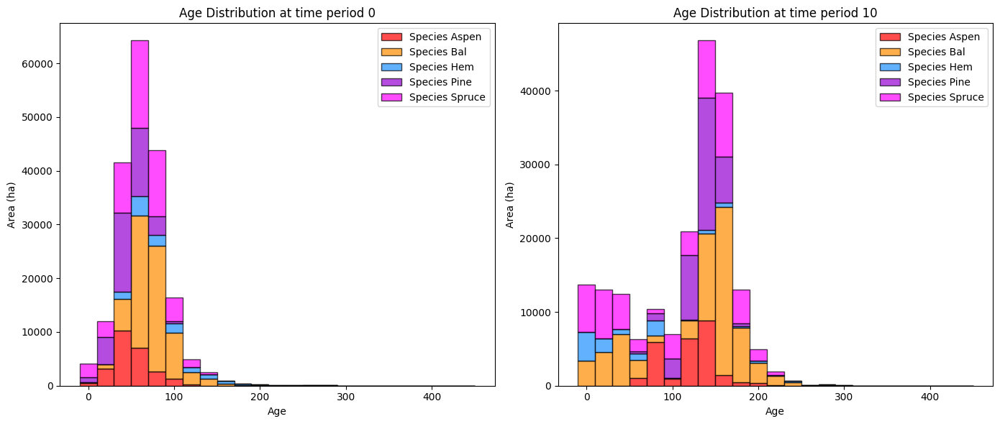

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_age_distribution.pdf

Old Growth Data (in hectares). 
Negative value indicates loss of old growth and positive value indicates gain of old growth.
                 0           10   Difference
Spruce    2.708533  4193.083821  4190.375287
Bal     278.565372  9045.947970  8767.382599
Aspen   273.490478  7151.110261  6877.619783
Pine      0.000000  6650.455938  6650.455938
Hem     419.699331   710.903413   291.204082

Overall diversity has **increased** by 26777.04 hectares from time period 0 to time period 10.


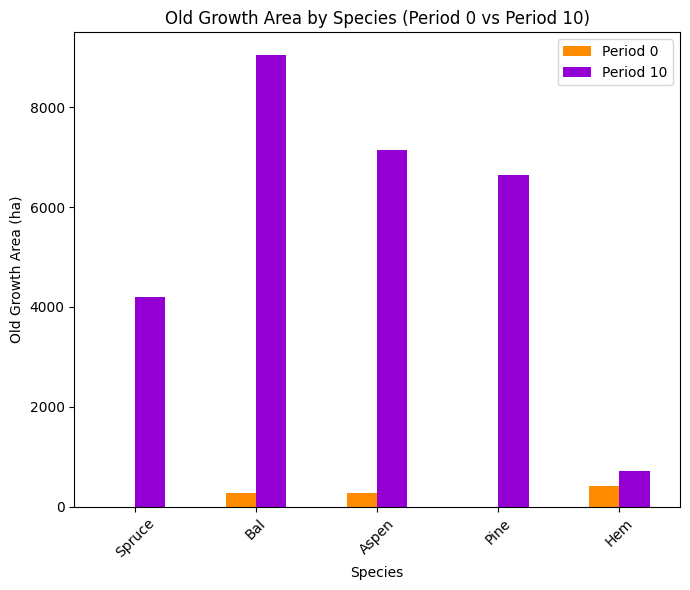

Clustered column plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_old_growth_comparison.pdf

Shannon Evenness Index for time period 0: 0.9455
Shannon Evenness Index for time period 10: 0.8856

Diversity has **decreased** by 5.99% from time 0 to time 10.


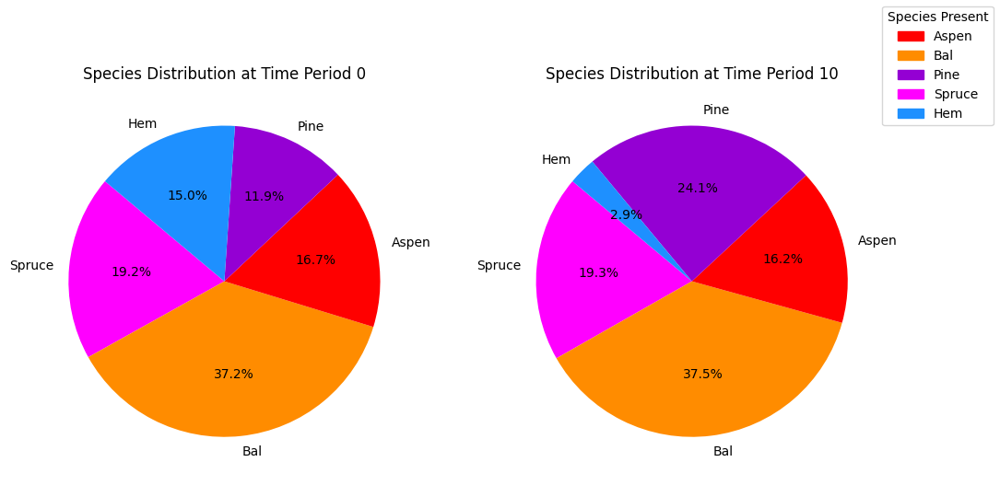

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_bau_gldbr_species_pie.pdf


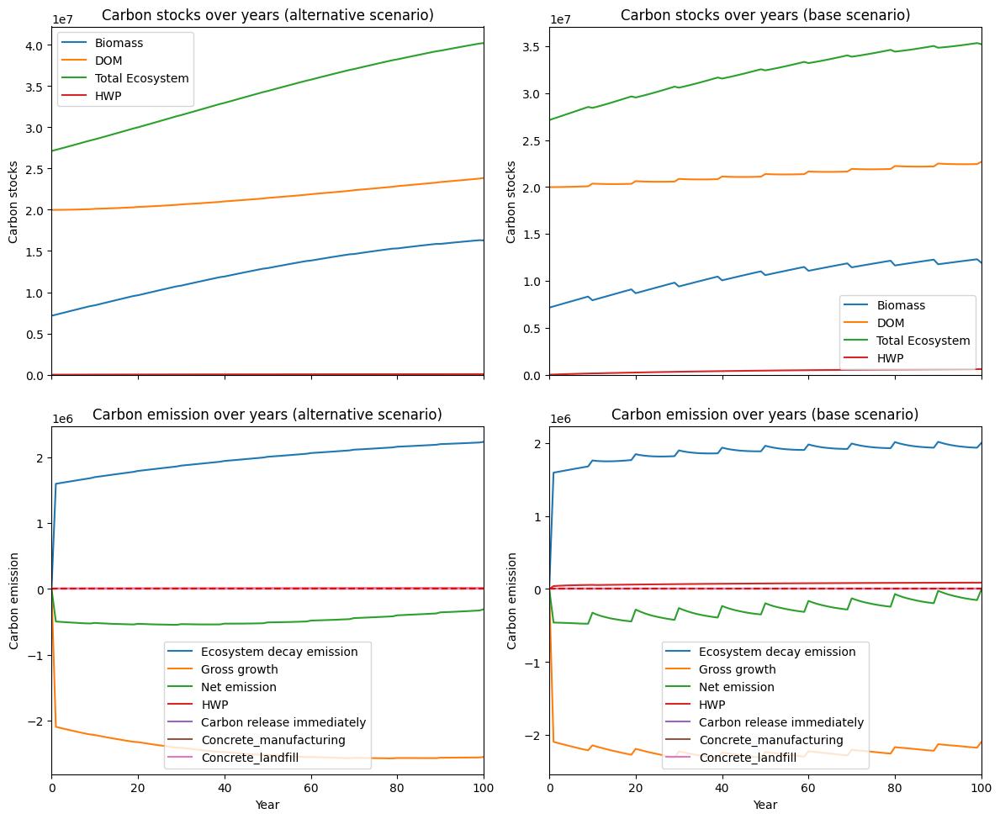

---------------------------------------------------------------------------------------
Net emission difference -2767761.2821188536
Net emission base scenario -12608461.545222733
Net emission alternative scenario -9840700.263103876
dollar_per_ton is:  3.6130283578302396
Comparison of Old Growth Areas (Alternative - Base)
          0           10   Difference
Spruce  0.0  3134.105340  3134.105340
Bal     0.0  6723.469565  6723.469565
Aspen   0.0  6040.508011  6040.508011
Pine    0.0   981.431263   981.431263
Hem     0.0  1523.977733  1523.977733

Overall, the old growth area has **increased** by 18403.49 hectares in the alternative scenario compared to the base scenario.


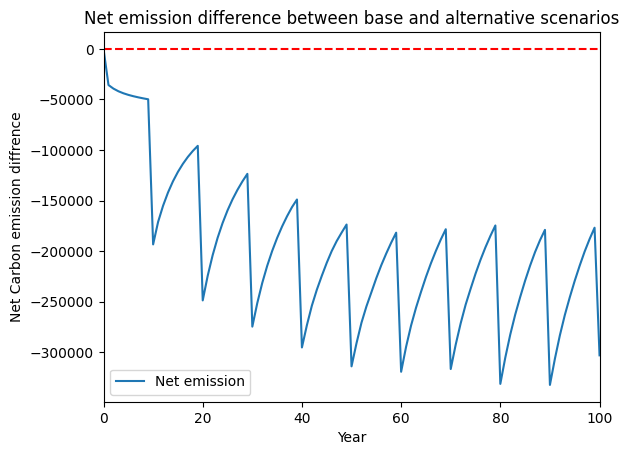

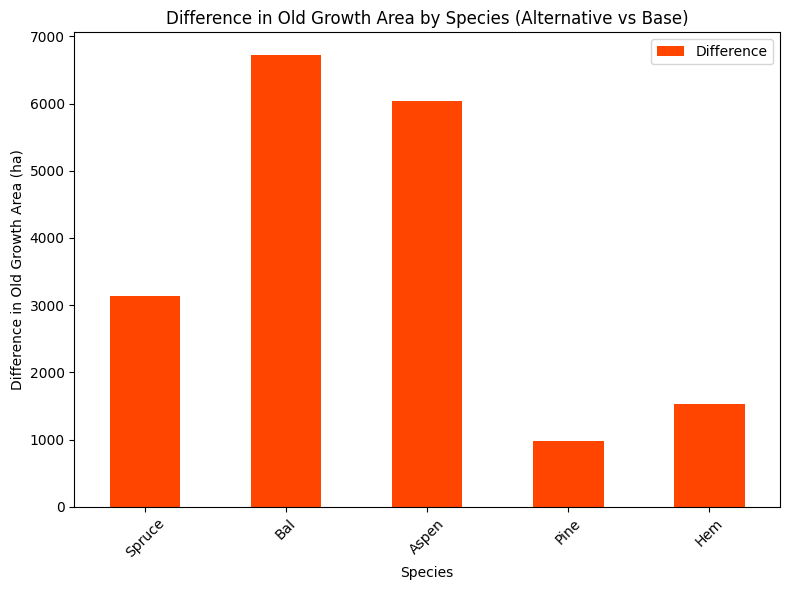

<Figure size 640x480 with 0 Axes>

Plot saved to ./outputs/fig/goldenbear/goldenbear_max_st_kpi_age_difference.pdf


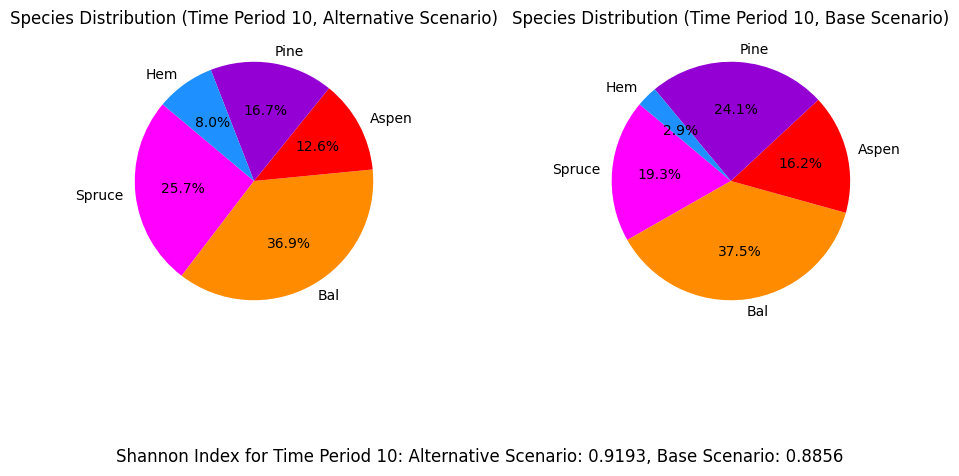

Pie Charts for Time Periods 0 and 10 saved to ./outputs/fig/goldenbear/goldenbear_max_st_kpi_species_difference_pie.pdf
---------------------------------------------------------------------------------------
It took 105.0 minutes to run all scenarios.


In [26]:
Start = time.time()
scenario_names = scenario_options.get(case_study, [])
for scenario_name in scenario_names:
    print(f"Running for {case_study}_{obj_mode}_{scenario_name}...")
    results_scenarios(fm, 
                      clt_percentage, 
                      credibility, 
                      budget_input, 
                      n_steps, 
                      max_harvest, 
                      scenario_name, 
                      displacement_effect, 
                      hwp_pool_effect_value, 
                      release_immediately_value, 
                      case_study, 
                      obj_mode,                   
                      pickle_output_base=False, 
                      pickle_output_alter=False)
print('It took', round((time.time() - Start) / 60, 1), "minutes to run all scenarios.")

In [27]:
print('It took', round((time.time() - Start) / 60, 1), "minutes to run this script.")

It took 105.0 minutes to run this script.
